# mini-vLLM, Part 9: A Decode Loop That Lives in CUDA Graphs

**What we will build and measure**

[Stage 9](https://github.com/chizkidd/minivllm/blob/main/08_fused_int8_and_self_speculation.ipynb) built a fused int8 kernel and found two things it could not fix. The kernel made a one-token decode step faster than fp16, but only inside a CUDA graph or under `torch.compile`: a Triton kernel launched eagerly costs about as much CPU time as it saves. And anything that fed *several* tokens through the int8 model was slow, because the kernel for a block of tokens (a tensor-core `tl.dot`) read the weights six to twelve times slower than the fp16 layer, so the checking pass of speculative decoding cost the int8 model two to three and a half times a one-token step. Stage 9's speculation loop was eager, so even a fast kernel could not have won in it.

**Stage 10 asks the question that was left: do int8 weights and speculative decoding multiply?** To answer it we need two pieces Stage 9 did not have, and a guesser that cannot confuse the answer.

1. **A multi-row int8 kernel.** The checking pass feeds the last accepted token and up to `k` drafts, 2 to 8 rows of `x`. A kernel that reads each int8 weight *once* and uses it for all of those rows on the ordinary FMA units (no tensor cores, no staging) should cost about what the one-token kernel costs. Correctness first, then a tuning run, then the go/no-go gate against the fp16 layer, timed inside a CUDA graph so that launch cost does not hide the kernels.
2. **A forward pass that lives in a graph.** A captured pass for a fixed number of tokens over the static KV cache, for one token (a plain decode step) and for `k + 1` tokens (the checking pass). Cost of a block against a single token, fp16 against int8, eager against graph.
3. **Plain decoding in the graph, end to end.** Tokens per second of fp16 and int8 at 0.5B, 1.5B and 3B, eager and in a graph: what quantization buys a decoder at batch 1 once the loop itself is fast.
4. **Speculation in the graph.** The n-gram lookup guesses for free, so the only thing that decides is the cost of the checking pass, and the target (fp16 or int8) is the thing under test: fp16 or int8 weights, plain or n-gram, each against fp16 eager (the Stage 9 baseline), fp16 in a graph and int8 in a graph. Do the two gains multiply, and where do they not?

**How to use this notebook.** Same shape as the earlier parts: *Goal, Concept, Code, Result, Takeaway*, with a prediction written down before every benchmark. The "how to read it" notes are written before the numbers exist. The numbers come from your run.

| # | Section | What we learn | Approx. runtime on a Kaggle T4 (estimates, not yet timed) |
| --- | --- | --- | --- |
| 0 | Setup | Reproducible environment, the whole package | seconds |
| 1 | The multi-row kernel | Correctness, tuned block sizes, and whether it beats the fp16 layer at 2 to 8 rows | about ten minutes (Triton compiles for each tuning candidate) |
| 2 | A forward pass in a graph | The cost of a block of tokens against one token, fp16 against int8, eager against graph | about five minutes |
| 3 | Plain decoding in a graph | Tokens per second end to end by size, weights and mode | about ten minutes |
| 4 | Speculation in the graph | Do int8 and speculation multiply, exactness, the cost model | about fifteen to twenty minutes (the sweeps) |
| 5 | Save and publish | JSON, figure inventory, GitHub | seconds |
| 6 | Lessons | Summary, questions, exercises | seconds |

**Kaggle setup:** Accelerator = GPU T4 x2 (we use only the first GPU), Internet = On. Run top to bottom and restart the kernel before the final run. Set `QUICK = True` in the setup cell for a pass with the 1.5B target only and fewer repeats (a few minutes shorter in each section).

**Self-contained.** Like the earlier parts, the `%%writefile` cells write the whole `minivllm/` and `bench/` packages and the notebook imports them. New in this part: `minivllm/graph_decode.py` (the graph decoder), `StaticForward` in `minivllm/draft.py`, the multi-row kernel and the dequantize fallback in `minivllm/int8_kernel.py`, and `time_in_graph` and a `reps` option of `tune_int8_kernel` in `bench/metrics.py`.

---
## 0. Setup

**Goal:** one imports cell, one environment record, then the package.

- `CUDA_VISIBLE_DEVICES=0` is set *before* importing torch, so "we only use one GPU" is enforced rather than assumed.
- `ENV` records GPU, torch, transformers, Triton and python versions, saved with the results.
- `QUICK = True` shrinks the run: one target, fewer prompts and repeats.
- After editing a `%%writefile` cell, re-run it and then restart the kernel, because modules that were already imported keep their old code.

In [45]:
import os
os.environ.setdefault("CUDA_VISIBLE_DEVICES", "0")   # Kaggle T4 x2: use one GPU only

import gc, platform, random, time

import numpy as np
import pandas as pd
import torch, transformers
import torch.nn.functional as F

for d in ("minivllm", "bench", "results"):
    os.makedirs(d, exist_ok=True)
for pkg in ("minivllm", "bench"):
    open(f"{pkg}/__init__.py", "a").close()

assert torch.cuda.is_available(), "Turn on a GPU accelerator in Kaggle settings"
import triton

QUICK = False   # True: the 1.5B target only, fewer prompts and repeats
SEED = 0

ENV = {
    "gpu": torch.cuda.get_device_name(0),
    "torch": torch.__version__,
    "transformers": transformers.__version__,
    "triton": triton.__version__,
    "python": platform.python_version(),
}
print(ENV)

{'gpu': 'Tesla T4', 'torch': '2.11.0+cu128', 'transformers': '5.16.1', 'triton': '3.6.0', 'python': '3.13.15'}


### The package

What is new in this part (everything else is repeated verbatim from Part 8):

| File | New in this part |
| --- | --- |
| `minivllm/int8_kernel.py` | the **multi-row kernel** `gemvm` (each int8 weight read once and used for up to 8 rows of `x` on the FMA units), a `dequant` fallback for more than 8 rows, new row buckets, and the grids the tuner searches. Explained in section 1. |
| `minivllm/draft.py` | `StaticForward`: a forward pass for a fixed number of tokens over the static KV cache, captured in a CUDA graph. Explained in section 2. |
| `minivllm/graph_decode.py` | **new.** `GraphDecoder`: plain and speculative greedy decoding where every model pass is a graph replay. Explained in sections 3 and 4. |
| `bench/metrics.py` | `time_in_graph` (time a function as repeated calls inside one CUDA graph), `reps` in `tune_int8_kernel`, `include_dot` in `linear_gate`, and `plain_fn` and `spec_fn` hooks in `sweep_proposers`. |

In [46]:
%%writefile minivllm/model.py
import torch
import torch.nn.functional as F

from .quant import QWeight, qlinear

def linear(x, w, b=None):
    """F.linear, or the int8 weight-only product (Stage 8) when w is a QWeight. The fp16 path is F.linear itself."""
    if isinstance(w, QWeight):
        return qlinear(x, w, b)
    return F.linear(x, w, b)

def rms_norm(x, weight, eps):
    xf = x.float()
    xf = xf * torch.rsqrt(xf.pow(2).mean(-1, keepdim=True) + eps)
    return weight * xf.to(x.dtype)

def rotate_half(x):
    h = x.shape[-1] // 2
    return torch.cat((-x[..., h:], x[..., :h]), dim=-1)

def apply_rope(x, cos, sin):
    return x * cos + rotate_half(x) * sin

class MiniQwen:
    def __init__(self, hf_model, max_pos=2048):
        cfg = hf_model.config
        self.n_layers = cfg.num_hidden_layers
        self.n_heads = cfg.num_attention_heads
        self.n_kv = cfg.num_key_value_heads
        self.hd = getattr(cfg, "head_dim", None) or cfg.hidden_size // self.n_heads
        self.n_rep = self.n_heads // self.n_kv
        self.eps = cfg.rms_norm_eps

        m = hf_model.model
        self.embed = m.embed_tokens.weight
        self.norm_w = m.norm.weight
        self.lm_head = hf_model.lm_head.weight
        self.device, self.dtype = self.embed.device, self.embed.dtype
        self.layers = []
        for l in m.layers:
            a, mlp = l.self_attn, l.mlp
            self.layers.append(dict(
                ln1=l.input_layernorm.weight, ln2=l.post_attention_layernorm.weight,
                q_w=a.q_proj.weight, q_b=a.q_proj.bias,
                k_w=a.k_proj.weight, k_b=a.k_proj.bias,
                v_w=a.v_proj.weight, v_b=a.v_proj.bias,
                o_w=a.o_proj.weight,
                gate=mlp.gate_proj.weight, up=mlp.up_proj.weight, down=mlp.down_proj.weight,
            ))

        theta = getattr(cfg, "rope_theta", None)
        if theta is None:
            theta = cfg.rope_parameters["rope_theta"]
        inv = 1.0 / (theta ** (torch.arange(0, self.hd, 2, device=self.device).float() / self.hd))
        t = torch.arange(max_pos, device=self.device).float()
        emb = torch.cat([torch.outer(t, inv)] * 2, dim=-1)
        self.cos, self.sin = emb.cos().to(self.dtype), emb.sin().to(self.dtype)

    @torch.no_grad()
    def forward(self, ids, cache=None, positions=None, attn_mask=None, all_logits=False):
        """
        ids: [B, T]. Returns logits for the LAST position only: [B, vocab].
        Batching of sequences with different lengths (Stage 3) adds two optional inputs:
          positions: [B, T] RoPE position of every token (default: consecutive from the cache length).
          attn_mask: bool [B, 1, T, L], True = this query may attend to this key, where L is the
                     number of keys after the cache update (default: causal, no padding).
        Speculative decoding (Stage 6) adds all_logits: return the logits of every position, [B, T, vocab], so
        one pass can check several drafted tokens. Feeding T > 1 tokens on top of a non-empty cache (the checking
        pass) needs an explicit attn_mask, because the default causal mask assumes an empty cache.
        """
        B, T = ids.shape
        pos0 = cache.length if cache is not None else 0
        assert not (cache is not None and T > 1 and pos0 > 0 and attn_mask is None), \
            "several tokens on a non-empty cache need an explicit attn_mask"
        if positions is None:
            assert pos0 + T <= self.cos.shape[0], "sequence longer than RoPE table"
            cos = self.cos[pos0:pos0 + T][None, None]
            sin = self.sin[pos0:pos0 + T][None, None]
        else:
            cos = self.cos[positions][:, None]   # [B, 1, T, head_dim]
            sin = self.sin[positions][:, None]

        x = F.embedding(ids, self.embed)
        for i, L in enumerate(self.layers):
            h = rms_norm(x, L["ln1"], self.eps)
            q = linear(h, L["q_w"], L["q_b"]).view(B, T, self.n_heads, self.hd).transpose(1, 2)
            k = linear(h, L["k_w"], L["k_b"]).view(B, T, self.n_kv, self.hd).transpose(1, 2)
            v = linear(h, L["v_w"], L["v_b"]).view(B, T, self.n_kv, self.hd).transpose(1, 2)
            q, k = apply_rope(q, cos, sin), apply_rope(k, cos, sin)
            if cache is not None:
                k, v = cache.update(i, k, v)
            # Expand KV heads to match query heads (GQA). Wasteful, a known optimization target.
            k = k.repeat_interleave(self.n_rep, dim=1)
            v = v.repeat_interleave(self.n_rep, dim=1)
            a = F.scaled_dot_product_attention(q, k, v, attn_mask=attn_mask,
                                               is_causal=(attn_mask is None and T > 1))
            a = a.transpose(1, 2).reshape(B, T, -1)
            x = x + linear(a, L["o_w"])
            h = rms_norm(x, L["ln2"], self.eps)
            x = x + linear(F.silu(linear(h, L["gate"])) * linear(h, L["up"]), L["down"])
        if cache is not None:
            cache.advance(T)
        x = rms_norm(x if all_logits else x[:, -1], self.norm_w, self.eps)
        return linear(x, self.lm_head)

Overwriting minivllm/model.py


In [47]:
%%writefile minivllm/batching.py
import torch

def left_pad(seqs, pad_id, device, pad_to=None):
    """
    Stack variable-length token lists into one [B, T] tensor, padding on the LEFT so that the
    last column is a real token for every sequence (generation reads the last position).
    Returns (ids [B, T], lens [B]) where lens are the real prompt lengths. `pad_to` forces a
    longer T than the longest prompt (e.g. to round up to a multiple of 8). 
    
    If you use `pad_to`, build the matching `Layout(..., T=ids.shape[1])` too: Layout assumes 
    the longest prompt otherwise, and its positions and masks would not fit the tensor.
    """
    lens = [len(s) for s in seqs]
    T = max(lens + [pad_to or 0])
    ids = torch.full((len(seqs), T), pad_id, dtype=torch.long)
    for i, s in enumerate(seqs):
        ids[i, T - len(s):] = torch.as_tensor(s, dtype=torch.long)
    return ids.to(device), torch.tensor(lens, device=device)

class Layout:
    """
    Positions and attention masks for one wave of left-padded sequences.
    
      column:   0 1 2 3 4 5 | 6 7 8 ...      T = longest prompt, then generated tokens follow
      seq A:    . . A A A A | g g g          (. = padding, A = prompt token, g = generated)
      seq B:    . B B B B B | g g g
    
    Every sequence shares the same cache columns, so the cache stays a single rectangle. Padding
    columns are never attended to, and RoPE positions count only real tokens (A starts at 0).
    """                                                                         
    def __init__(self, lens, max_new, device, T=None):
        self.lens = lens.to(device)                         # [B] real prompt lengths
        self.T = T or int(self.lens.max())                  # padded prompt length (columns)
        self.device = device
        self.pad = self.T - self.lens                       # [B] padding columns per sequence
        cols = torch.arange(self.T + max_new, device=device)
        self.key_real = cols[None, :] >= self.pad[:, None]  # [B, T + max_new]: True on real tokens

    def prefill(self):
        """positions [B, T] and mask [B, 1, T, T] for the prompt pass."""
        T, dev = self.T, self.device
        cols = torch.arange(T, device=dev)
        positions = (cols[None, :] - self.pad[:, None]).clamp(min=0)
        causal = torch.tril(torch.ones(T, T, dtype=torch.bool, device=dev))
        mask = causal[None] & self.key_real[:, None, :T]
        # A padding query would otherwise have no key to attend to. A fully masked row makes the
        # softmax NaN, and 0 * NaN is NaN, so it would poison real tokens. Let it see itself.
        mask = mask | torch.eye(T, dtype=torch.bool, device=dev)[None]
        return positions, mask[:, None]

    def decode(self, j):
        """
        positions [B, 1] and mask [B, 1, 1, L] for the step that consumes generated token j
        (j = 1 is the token the prompt pass produced). It sits in cache column T + j - 1.
        """
        positions = (self.lens + (j - 1))[:, None]
        mask = self.key_real[:, None, None, :self.T + j]
        return positions, mask

Overwriting minivllm/batching.py


In [48]:
%%writefile minivllm/block_allocator.py
from collections import deque


class BlockAllocator:
    """
    A pool of `num_blocks` fixed-size KV blocks, handed out and taken back by id.

    The allocator knows nothing about tensors or tokens: it only tracks which block ids are free. A sequence
    that needs `n` blocks gets a list of `n` ids (its block table) and gives them back when it finishes, so
    memory freed by one request is immediately usable by the next, whatever their lengths.

    Free ids are kept in a FIFO queue. That is not required for correctness, but it recycles blocks in
    release order, so after some churn a sequence's blocks are scattered over the pool instead of forming one
    contiguous run, which is exactly the situation a block table exists to handle.
    """
    def __init__(self, num_blocks):
        assert num_blocks > 0
        self.num_blocks = num_blocks
        self._free = deque(range(num_blocks))
        self._in_use = [False] * num_blocks

    @property
    def num_free(self):
        return len(self._free)

    @property
    def num_used(self):
        return self.num_blocks - len(self._free)

    def can_allocate(self, n):
        return n <= len(self._free)

    def allocate(self, n):
        """Take `n` free blocks. Returns their ids; raises if the pool cannot supply them."""
        if not self.can_allocate(n):
            raise MemoryError(f"need {n} blocks, only {len(self._free)} free")
        ids = [self._free.popleft() for _ in range(n)]
        for b in ids:
            self._in_use[b] = True
        return ids

    def free(self, ids):
        """Give blocks back. Freeing a block that is not in use is a bug (a double free), so it raises."""
        for b in ids:
            if not self._in_use[b]:
                raise ValueError(f"block {b} is not in use")
            self._in_use[b] = False
            self._free.append(b)

Overwriting minivllm/block_allocator.py


In [49]:
%%writefile minivllm/kv_cache.py
import torch
import torch.nn.functional as F

from .block_allocator import BlockAllocator

class KVCache:
    """
    Contiguous, preallocated cache for a batch of sequences.
    Each tensor has shape [n_layers, batch, n_kv_heads, max_len, head_dim].
    """
    def __init__(self, n_layers, batch, n_kv_heads, max_len, head_dim, device, dtype):
        shape = (n_layers, batch, n_kv_heads, max_len, head_dim)
        self.k = torch.zeros(shape, device=device, dtype=dtype)
        self.v = torch.zeros(shape, device=device, dtype=dtype)
        self.length = 0
        self.max_len = max_len

    def update(self, layer, k, v):
        """k, v: [batch, n_kv_heads, T, head_dim]. Returns everything cached so far."""
        T = k.shape[2]
        end = self.length + T
        assert end <= self.max_len, "KV cache overflow"
        self.k[layer, :, :, self.length:end] = k
        self.v[layer, :, :, self.length:end] = v
        return self.k[layer, :, :, :end], self.v[layer, :, :, :end]

    def advance(self, T):
        """Called once per forward pass, after all layers have written."""
        self.length += T

    def truncate(self, length):
        """Forget everything after the first `length` tokens (Stage 6: drop the rejected draft tokens).
        The old keys stay in memory but are never read, and the next write overwrites them."""
        assert 0 <= length <= self.length, "can only truncate to a shorter length"
        self.length = length

    @property
    def nbytes(self):
        return 2 * self.k.numel() * self.k.element_size()

    @staticmethod
    def bytes_per_token(n_layers, n_kv_heads, head_dim, dtype_bytes=2):
        return 2 * n_layers * n_kv_heads * head_dim * dtype_bytes


class SlotCache:
    """
    A fixed pool of `slots` sequence slots, each with room for `max_len` tokens, for continuous batching.
    Shape [n_layers, slots, n_kv_heads, max_len, head_dim], like KVCache, but every slot has its OWN length
    (`lens`). A finished sequence frees its slot at once and a waiting request is prefilled into it, while
    the other slots keep decoding. Each slot is still one contiguous worst-case rectangle (Stage 5 replaces
    that with blocks).

    model.forward only needs `length`, `update` and `advance`, so two small views plug the pool into it:
      prefill_view(slot): one new prompt (batch 1, no padding) written into one free slot.
      decode_view():      one token for EVERY slot at its own column. Slots that are free decode a dummy
                          token that is masked and overwritten later, which keeps the batch shape fixed.
    """
    def __init__(self, n_layers, slots, n_kv_heads, max_len, head_dim, device, dtype):
        shape = (n_layers, slots, n_kv_heads, max_len, head_dim)
        self.k = torch.zeros(shape, device=device, dtype=dtype)
        self.v = torch.zeros(shape, device=device, dtype=dtype)
        self.slots, self.max_len, self.device = slots, max_len, device
        self.lens = [0] * slots     # tokens stored per slot; plain ints, so reading them never syncs the GPU

    def prefill_view(self, slot):
        return _PrefillView(self, slot)

    def decode_view(self):
        return _DecodeView(self)

    def free(self, slot):
        self.lens[slot] = 0

    @property
    def used_tokens(self):
        return sum(self.lens)

    @property
    def nbytes(self):
        return 2 * self.k.numel() * self.k.element_size()


class _PrefillView:
    length = 0   # forward() reads this only to start positions at 0, and a prefill starts from an empty slot

    def __init__(self, cache, slot):
        assert cache.lens[slot] == 0, "slot is not free"
        self.c, self.slot = cache, slot

    def update(self, layer, k, v):
        """k, v: [1, n_kv_heads, T, head_dim]."""
        T = k.shape[2]
        assert T <= self.c.max_len, "KV slot overflow"
        self.c.k[layer, self.slot, :, :T] = k[0]
        self.c.v[layer, self.slot, :, :T] = v[0]
        return self.c.k[layer, self.slot:self.slot + 1, :, :T], self.c.v[layer, self.slot:self.slot + 1, :, :T]

    def advance(self, T):
        self.c.lens[self.slot] = T


class _DecodeView:
    length = 0   # positions are passed in explicitly, so forward() never needs the shared length

    def __init__(self, cache):
        self.c = cache
        self.rows = torch.arange(cache.slots, device=cache.device)
        self.cols = torch.tensor(cache.lens, device=cache.device)   # the column each slot writes its new token to
        self.end = max(cache.lens) + 1                               # columns that can matter this step
        assert self.end <= cache.max_len, "KV slot overflow"

    def update(self, layer, k, v):
        """k, v: [slots, n_kv_heads, 1, head_dim]. Returns the first `end` columns of every slot."""
        self.c.k[layer, self.rows, :, self.cols] = k[:, :, 0]
        self.c.v[layer, self.rows, :, self.cols] = v[:, :, 0]
        return self.c.k[layer, :, :, :self.end], self.c.v[layer, :, :, :self.end]

    def advance(self, T):
        pass     # the scheduler advances only the slots that are actually running


class PagedCache:
    """
    A KV cache made of fixed-size blocks drawn from one shared pool (Stage 5).
    Each tensor has shape [n_layers, num_blocks, n_kv_heads, block_size, head_dim]. A sequence does not own a
    rectangle: it owns a list of block ids (its block table) and a length, and token t of the sequence lives in
    block table[t // block_size] at offset t % block_size. Blocks are handed out by a BlockAllocator when a
    sequence is added and returned the moment it is freed, so a request holds memory for the tokens it needs,
    not for the longest request the server might ever see.

    Sequences are named by any hashable id (we use the request id). `add(seq, tokens)` reserves enough blocks
    for the whole request, `tokens` = prompt + generated tokens that will be stored, so a running sequence can
    never run out of blocks half way (Stage 5 keeps admission simple; reserving lazily needs preemption,
    which is exercise 1).

    model.forward only needs `length`, `update` and `advance`, so two views plug the pool into it, as for SlotCache:
      prefill_view(seq):  one new prompt (batch 1, no padding) written into the sequence's blocks.
      decode_view(seqs):  one token for each listed sequence, each written at its own position. The keys and
                          values of those sequences are gathered through their block tables into one dense
                          tensor, then ordinary attention runs on it.
    """
    def __init__(self, n_layers, num_blocks, block_size, n_kv_heads, head_dim, device, dtype):
        shape = (n_layers, num_blocks, n_kv_heads, block_size, head_dim)
        self.k = torch.zeros(shape, device=device, dtype=dtype)
        self.v = torch.zeros(shape, device=device, dtype=dtype)
        self.num_blocks, self.block_size, self.device = num_blocks, block_size, device
        self.n_kv_heads, self.head_dim = n_kv_heads, head_dim
        self.allocator = BlockAllocator(num_blocks)
        self.tables = {}     # seq -> list of block ids
        self.lens = {}       # seq -> tokens stored (plain ints, so reading them never syncs the GPU)
        self.cap = {}        # seq -> tokens reserved for it

    def blocks_for(self, tokens):
        return -(-tokens // self.block_size)

    def can_admit(self, tokens):
        return self.allocator.can_allocate(self.blocks_for(tokens))

    def add(self, seq, tokens):
        """Reserve blocks for a sequence that will store up to `tokens` tokens."""
        assert seq not in self.tables, "sequence already in the cache"
        self.tables[seq] = self.allocator.allocate(self.blocks_for(tokens))
        self.lens[seq], self.cap[seq] = 0, tokens

    def free(self, seq):
        """Give the sequence's blocks back to the pool. Their contents are not erased, only forgotten."""
        self.allocator.free(self.tables.pop(seq))
        del self.lens[seq], self.cap[seq]

    def prefill_view(self, seq):
        return _PagedPrefillView(self, seq)

    def decode_view(self, seqs):
        return _PagedDecodeView(self, list(seqs))

    @property
    def used_tokens(self):
        """Tokens actually stored."""
        return sum(self.lens.values())

    @property
    def reserved_tokens(self):
        """Tokens the running sequences will have stored when they finish."""
        return sum(self.cap.values())

    @property
    def allocated_tokens(self):
        """Token capacity of the blocks handed out (reserved tokens rounded up to whole blocks)."""
        return self.allocator.num_used * self.block_size

    @property
    def bytes_per_block(self):
        return 2 * self.k.shape[0] * self.k[0, 0].numel() * self.k.element_size()

    @property
    def nbytes(self):
        return 2 * self.k.numel() * self.k.element_size()


class _PagedPrefillView:
    length = 0   # forward() reads this only to start positions at 0, and a prefill starts from an empty sequence

    def __init__(self, cache, seq):
        assert cache.lens[seq] == 0, "sequence already has tokens"
        self.c, self.seq = cache, seq

    def update(self, layer, k, v):
        """k, v: [1, n_kv_heads, T, head_dim]. Writes them block by block and returns them unchanged."""
        c, T = self.c, k.shape[2]
        assert T <= c.cap[self.seq], "KV reservation overflow"
        nb = c.blocks_for(T)
        blocks = torch.tensor(c.tables[self.seq][:nb], device=c.device)
        pad = nb * c.block_size - T
        for cache_t, x in ((c.k, k), (c.v, v)):
            # [n_kv, T, hd] -> pad the last block with zeros -> [nb, n_kv, block_size, hd]
            x = F.pad(x[0], (0, 0, 0, pad)).view(c.n_kv_heads, nb, c.block_size, c.head_dim).transpose(0, 1)
            cache_t[layer, blocks] = x
        return k, v   # a prefill attends to the prompt it just computed, so there is nothing to gather

    def advance(self, T):
        self.c.lens[self.seq] = T


class _PagedDecodeView:
    length = 0   # positions are passed in explicitly, so forward() never needs the shared length

    def __init__(self, cache, seqs):
        self.c = cache
        bs = cache.block_size
        lens = [cache.lens[s] for s in seqs]
        assert all(l < cache.cap[s] for s, l in zip(seqs, lens)), "KV reservation overflow"
        self.end = max(lens) + 1                      # columns that can matter this step
        nb = cache.blocks_for(self.end)
        # Block table of the batch, [n, nb]. A sequence with fewer blocks is padded with block 0: those columns
        # lie beyond its position, so the attention mask hides whatever they hold.
        table = [(cache.tables[s] + [0] * nb)[:nb] for s in seqs]
        self.table = torch.tensor(table, device=cache.device)
        self.wblk = torch.tensor([cache.tables[s][l // bs] for s, l in zip(seqs, lens)], device=cache.device)
        self.woff = torch.tensor([l % bs for l in lens], device=cache.device)

    def update(self, layer, k, v):
        """k, v: [n, n_kv_heads, 1, head_dim]. Returns the first `end` columns of every sequence, gathered."""
        c = self.c
        c.k[layer, self.wblk, :, self.woff] = k[:, :, 0]
        c.v[layer, self.wblk, :, self.woff] = v[:, :, 0]
        n, nb = self.table.shape
        out = []
        for cache_t in (c.k, c.v):
            g = cache_t[layer][self.table]                                    # [n, nb, n_kv, block_size, hd]
            g = g.permute(0, 2, 1, 3, 4).reshape(n, c.n_kv_heads, nb * c.block_size, c.head_dim)
            out.append(g[:, :, :self.end])
        return out[0], out[1]

    def advance(self, T):
        pass     # the scheduler advances only the sequences that are actually running

Overwriting minivllm/kv_cache.py


In [50]:
%%writefile minivllm/speculative.py
import time
import torch
from .kv_cache import KVCache


def _tick():
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    return time.perf_counter()


class PromptLookup:
    """
    A draft that needs no model: look for an earlier place in the context where the last few tokens occurred
    before, and propose the tokens that followed them there. It works when the output repeats the input
    (copying, quoting, code that repeats itself) and proposes nothing when it does not.

    Longer n-grams are tried first (the most recent match of the longest one that matches wins), down to
    `ngram_min`. `__call__(context, k)` returns up to `k` token ids, or [] if nothing matches.
    """
    def __init__(self, ngram_max=3, ngram_min=1):
        assert 1 <= ngram_min <= ngram_max
        self.ngram_max, self.ngram_min = ngram_max, ngram_min

    def __call__(self, context, k):
        n_ctx = len(context)
        if k <= 0:
            return []
        for n in range(min(self.ngram_max, n_ctx - 1), self.ngram_min - 1, -1):
            tail = context[-n:]
            for i in range(n_ctx - n - 1, -1, -1):       # most recent earlier occurrence first
                if context[i] == tail[0] and context[i:i + n] == tail:
                    return list(context[i + n:i + n + k])  # not empty: i + n <= n_ctx - 1
        return []


@torch.no_grad()
def generate_speculative(model, prompt_ids, max_new, k=4, proposer=None, rollback=True):
    """
    Greedy generation of one sequence, several tokens per forward pass when the draft is right.

    Each iteration the draft proposes up to k tokens. One forward pass feeds the last generated token and the
    draft, [last, d1, ..., dk], on top of the cache, with a causal mask over the cache, and returns the model's
    own greedy choice after every one of them: c0 (after last), c1 (after d1), ... The draft is accepted while it
    agrees with the model: d1 is right if c0 == d1, d2 is right if c1 == d2, and so on. If `a` drafts are right,
    the pass has produced a + 1 tokens (c0 .. ca, the last one is a free "bonus"), and the cache keeps the first
    a + 1 of the fed tokens. Because every token comes from the model's own greedy choice, the output is the same
    as plain greedy decoding, just in fewer passes. If the draft is empty or wrong, the pass is an ordinary
    decode step.

    rollback=False skips the cache truncation, which makes the output wrong as soon as a draft is rejected. It
    exists only for the negative control in the notebook.

    prompt_ids: list of token ids. Returns (generated token ids, stats), stats = {"ttft": seconds,
    "steps": [{"drafted": n, "accepted": a, "step_s": seconds} per pass after the prefill]}.
    """
    proposer = proposer or PromptLookup()
    device = model.device
    ids = torch.tensor([list(prompt_ids)], device=device)
    P = ids.shape[1]
    room = k + 1 if rollback else max_new * (k + 1)       # without rollback the rejected tokens pile up in the cache
    cache = KVCache(model.n_layers, 1, model.n_kv, P + max_new + room, model.hd, device, model.dtype)
    t0 = _tick()
    tokens = [int(model.forward(ids, cache).argmax(-1))]
    ttft = _tick() - t0
    steps = []
    while len(tokens) < max_new:
        remaining = max_new - len(tokens)
        draft = proposer(list(prompt_ids) + tokens, min(k, remaining - 1)) if remaining > 1 else []
        feed = torch.tensor([[tokens[-1]] + draft], device=device)
        pos0, T = cache.length, feed.shape[1]
        mask = None
        if T > 1:    # query j sits at position pos0 + j and may attend to every key up to and including its own
            mask = (torch.arange(pos0 + T, device=device)[None, :] <= (pos0 + torch.arange(T, device=device))[:, None])[None, None]
        t1 = _tick()
        choice = model.forward(feed, cache, attn_mask=mask, all_logits=True).argmax(-1)[0].tolist()
        dt = _tick() - t1
        a = 0
        while a < len(draft) and choice[a] == draft[a]:
            a += 1
        tokens += choice[:a + 1]
        if rollback:
            cache.truncate(pos0 + a + 1)
        steps.append(dict(drafted=len(draft), accepted=a, step_s=dt))
    return tokens[:max_new], {"ttft": ttft, "steps": steps}

Overwriting minivllm/speculative.py


In [51]:
%%writefile minivllm/draft.py
import statistics
import time
import torch
from .kv_cache import KVCache


def _tick():
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    return time.perf_counter()


class StaticKVCache:
    """
    A KV cache whose tensors never change shape: [n_layers, 1, n_kv_heads, max_len, head_dim], one sequence.
    A forward pass writes its new keys at explicit positions (a device tensor set with `set_write`) and returns
    the WHOLE buffer, so the attention mask, not a slice, decides which keys count. That is what lets a decode
    step be captured in a CUDA graph: every shape, and every address, is the same on every step. `length` is a
    plain Python int that the owner keeps up to date, because the model's own length bookkeeping is not used.
    """
    def __init__(self, n_layers, n_kv_heads, max_len, head_dim, device, dtype):
        shape = (n_layers, 1, n_kv_heads, max_len, head_dim)
        self.k = torch.zeros(shape, device=device, dtype=dtype)
        self.v = torch.zeros(shape, device=device, dtype=dtype)
        self.max_len = max_len
        self.length = 0
        self.pos = None

    def set_write(self, positions):
        """positions: long tensor [T], where the next forward pass writes its T new keys."""
        self.pos = positions

    def update(self, layer, k, v):
        """k, v: [1, n_kv_heads, T, head_dim]. Writes at the positions set by set_write, returns every key."""
        self.k[layer].index_copy_(2, self.pos, k)
        self.v[layer].index_copy_(2, self.pos, v)
        return self.k[layer], self.v[layer]

    def advance(self, T):
        pass     # the owner moves `length`

    def truncate(self, length):
        assert 0 <= length <= self.length, "can only truncate to a shorter length"
        self.length = length


class StaticForward:
    """
    A forward pass over a StaticKVCache for a FIXED number T of tokens, captured in a CUDA graph (Stage 10). Everything a graph needs to
    replay is a static buffer: the token ids [1, T] and their positions [T] are device tensors that `run` overwrites, the attention mask
    is computed from the positions inside the captured pass, and the logits are the output tensor of the graph (overwritten by the next
    run, so read them before running again). With all_logits the logits are [1, T, vocab], one per fed token, which is what the checking
    pass of speculation needs; otherwise they are [1, vocab], those of the last token.

    The rollback of a speculative decoder is free with this cache: a pass writes its T keys at the positions it is given, a row only
    attends to keys at or before its own position, and keys beyond what the owner considers accepted are overwritten before any row can
    read them, so "forgetting" the rejected tokens is just not advancing the owner's length. causal=False breaks that on purpose (every
    row sees every key up to the last position of the block): it is the negative control for the tests.

    Without a CUDA device (or if capture fails) it runs the same pass eagerly and says why in `graph_error`, so the logic is testable on the
    CPU and the graph is a pure speed-up.
    """
    def __init__(self, model, cache, T, all_logits=False, capture=True, causal=True):
        assert T >= 1
        self.model, self.cache, self.T, self.all_logits, self.causal = model, cache, T, all_logits, causal
        self.device = model.device
        self.ids = torch.zeros((1, T), dtype=torch.long, device=self.device)
        self.pos = torch.zeros((T,), dtype=torch.long, device=self.device)
        self._cols = torch.arange(cache.max_len, device=self.device)
        self.logits, self._graph, self.graph_error, self.mode = None, None, None, "static"
        if capture:
            self._try_capture()

    def _forward(self):
        self.cache.set_write(self.pos)
        if self.causal:
            mask = self._cols[None, :] <= self.pos[:, None]                                    # [T, max_len]
        else:
            mask = (self._cols[None, :] <= self.pos[-1]).expand(self.T, -1)
        return self.model.forward(self.ids, self.cache, positions=self.pos[None, :], attn_mask=mask[None, None], all_logits=self.all_logits)

    @torch.no_grad()
    def _try_capture(self):
        if self.device.type != "cuda" or not torch.cuda.is_available():
            self.graph_error = "CUDA graphs need a CUDA device"
            return
        try:
            stream = torch.cuda.Stream()
            stream.wait_stream(torch.cuda.current_stream())
            with torch.cuda.stream(stream):
                for _ in range(3):                      # warm-up on a side stream, as CUDA graph capture requires
                    self._forward()
            torch.cuda.current_stream().wait_stream(stream)
            torch.cuda.synchronize()
            graph = torch.cuda.CUDAGraph()
            with torch.cuda.graph(graph):
                self.logits = self._forward()
            self._graph, self.mode = graph, "graph"
            self.cache.k.zero_()                        # the warm-up wrote junk at the first positions
            self.cache.v.zero_()
        except Exception as e:                          # capture can fail for reasons that depend on the torch build
            self._graph, self.graph_error = None, f"{type(e).__name__}: {e}"

    @torch.no_grad()
    def replay(self):
        """Run the pass on whatever is in the static buffers (self.ids, self.pos) and return the logits."""
        if self._graph is not None:
            self._graph.replay()
        else:
            self.logits = self._forward()
        return self.logits

    @torch.no_grad()
    def run(self, ids, start):
        """Feed the T token ids `ids` at positions start .. start + T - 1 and return the logits."""
        assert len(ids) == self.T and start + self.T <= self.cache.max_len, "the block does not fit in the cache"
        self.ids.copy_(torch.tensor([list(ids)], device=self.device))
        self.pos.copy_(torch.arange(start, start + self.T, device=self.device))
        return self.replay()


class DraftModel:
    """
    A small model used as the guesser of speculative decoding (Stage 7). It has the same interface as
    PromptLookup, `proposer(context, k) -> list of up to k token ids`, so generate_speculative can use either.

    The draft model keeps its own KV cache of the context it has seen. On each call:
      1. SYNC. The context grew since the last call (the target accepted some drafts and added a bonus token),
         so the draft's cache is truncated to the longest prefix it shares with the new context, never longer
         than len(context) - 1, so there is always at least one new token to feed and fresh logits to read.
         The keys of drafted tokens the target accepted are kept (no recompute), the rest are dropped.
      2. FEED the tokens of the context the cache does not have yet (the whole prompt on the first call, then
         the bonus token, or the last drafted token and the bonus after a fully accepted draft) in ONE pass,
         and read the logits after the last one: that is the first guess.
      3. GUESS k - 1 more tokens greedily, one single-token step each, feeding each guess back in.
    So a call costs k draft forward passes, the unit the cost model of Stage 7 uses.

    mode:
      "eager":  an ordinary KVCache and one forward pass per step, as the target runs.
      "static": the same steps over a StaticKVCache (fixed shapes), run eagerly. It exists so the benefit of
                a CUDA graph can be told apart from the cost of the fixed-shape path.
      "graph":  the single-token step is captured once in a CUDA graph and replayed, which removes the
                per-kernel launch cost that dominates a small model's step. Needs a CUDA device. If capture is
                not possible the model falls back to "static" and `graph_error` says why.
    sync=False is the negative control: it does not truncate (it forgets to roll back after a rejection), so the
    stale keys of rejected guesses stay in the cache and its guesses get worse. The target still checks every
    token, so the OUTPUT stays correct, only the acceptance collapses.
    """
    def __init__(self, model, max_len, mode="eager", sync=True):
        assert mode in ("eager", "static", "graph")
        self.model, self.max_len, self.sync = model, max_len, sync
        self.device, self.mode = model.device, mode
        self.graph_error, self._graph = None, None
        self.tokens = []                 # the context tokens whose keys are in the cache (sync=True)
        self._ctx_fed = 0                # sync=False only: how much of the context has been fed
        if mode == "eager":
            self.cache = KVCache(model.n_layers, 1, model.n_kv, max_len, model.hd, self.device, model.dtype)
        else:
            self.cache = StaticKVCache(model.n_layers, model.n_kv, max_len, model.hd, self.device, model.dtype)
            self._tok = torch.zeros((1, 1), dtype=torch.long, device=self.device)
            self._posv = torch.zeros((1,), dtype=torch.long, device=self.device)
            self._cols = torch.arange(max_len, device=self.device)
        if mode == "graph":
            self._try_capture()

    # ---- the single-token step over the static cache, the part a CUDA graph captures ---------------------------
    def _step(self):
        """Feed self._tok at position self._posv, write its keys, and leave the next guess in self._tok."""
        self.cache.set_write(self._posv)
        mask = (self._cols[None, :] <= self._posv[:, None])[None, None]            # [1, 1, 1, max_len]
        logits = self.model.forward(self._tok, self.cache, positions=self._posv[None, :], attn_mask=mask)
        nxt = logits.argmax(-1, keepdim=True)
        self._tok.copy_(nxt)
        self._posv.add_(1)
        return nxt

    def _try_capture(self):
        if self.device.type != "cuda" or not torch.cuda.is_available():
            self.graph_error, self.mode = "CUDA graphs need a CUDA device", "static"
            return
        try:
            stream = torch.cuda.Stream()
            stream.wait_stream(torch.cuda.current_stream())
            with torch.cuda.stream(stream):
                for _ in range(3):                      # warm-up on a side stream, as CUDA graph capture requires
                    self._posv.zero_()
                    self._tok.zero_()
                    self._step()
            torch.cuda.current_stream().wait_stream(stream)
            torch.cuda.synchronize()
            graph = torch.cuda.CUDAGraph()
            self._posv.zero_()
            self._tok.zero_()
            with torch.cuda.graph(graph):
                self._step()
            self._graph = graph
            self.cache.k.zero_()                        # the warm-up wrote junk at the first positions
            self.cache.v.zero_()
        except Exception as e:                          # capture can fail for reasons that depend on the torch build
            self._graph = None
            self.graph_error, self.mode = f"{type(e).__name__}: {e}", "static"

    # ---- feeding tokens ------------------------------------------------------------------------------------
    def _feed(self, new):
        """Append the tokens `new` (a list) to the cache and return the logits after the last one, [1, vocab]."""
        T, n0 = len(new), self.cache.length
        assert n0 + T <= self.max_len, f"the draft cache holds {self.max_len} tokens, needs {n0 + T}"
        ids = torch.tensor([new], device=self.device)
        if self.mode == "eager":
            mask = None
            if T > 1 and n0 > 0:     # several tokens on top of a non-empty cache need an explicit causal mask
                mask = (torch.arange(n0 + T, device=self.device)[None, :]
                        <= (n0 + torch.arange(T, device=self.device))[:, None])[None, None]
            return self.model.forward(ids, self.cache, attn_mask=mask)
        positions = torch.arange(n0, n0 + T, device=self.device)
        self.cache.set_write(positions)
        mask = (self._cols[None, :] <= positions[:, None])[None, None]            # [1, 1, T, max_len]
        logits = self.model.forward(ids, self.cache, positions=positions[None, :], attn_mask=mask)
        self.cache.length = n0 + T
        return logits

    # ---- the proposer interface ----------------------------------------------------------------------------
    @torch.no_grad()
    def __call__(self, context, k):
        context = list(context)
        n_ctx = len(context)
        if k <= 0 or n_ctx == 0:
            return []
        assert n_ctx + k <= self.max_len, f"the draft cache holds {self.max_len} tokens, needs {n_ctx + k}"
        if self.sync:
            lcp, limit = 0, min(len(self.tokens), n_ctx - 1)
            while lcp < limit and self.tokens[lcp] == context[lcp]:
                lcp += 1
            self.cache.truncate(lcp)
            self.tokens = self.tokens[:lcp]
            new = context[lcp:]
            self.tokens += new
        else:                                   # the broken control: never roll back, only append what is new
            new = context[self._ctx_fed:] or context[-1:]
            self._ctx_fed = n_ctx
        logits = self._feed(new)
        if self.mode == "eager":
            guesses = [int(logits.argmax(-1))]
            for _ in range(k - 1):
                logits = self.model.forward(torch.tensor([[guesses[-1]]], device=self.device), self.cache)
                guesses.append(int(logits.argmax(-1)))
        else:
            self._tok.copy_(logits.argmax(-1, keepdim=True))
            self._posv.fill_(self.cache.length)
            picked = [self._tok.clone()]
            for _ in range(k - 1):
                if self._graph is not None:
                    self._graph.replay()
                else:
                    self._step()
                picked.append(self._tok.clone())
            self.cache.length += k - 1
            guesses = torch.cat(picked, dim=1)[0].tolist()                        # one sync for the whole draft
        if self.sync:
            self.tokens += guesses[:-1]         # the last guess was never fed, so it has no keys
        return guesses

    def reset(self):
        """Forget everything cached (a new unrelated sequence). Not needed between calls: the sync handles it."""
        self.cache.length = 0
        self.tokens, self._ctx_fed = [], 0

    # ---- cost ----------------------------------------------------------------------------------------------
    @torch.no_grad()
    def time_step(self, context_len, iters=20, warmup=3):
        """
        Milliseconds (median) of one single-token draft step, argmax included, on top of `context_len` cached
        tokens (whatever the cache holds there, which does not change the work), in this model's own mode. This is
        the numerator of c, the draft step time over the target step time. The cache is left exactly as it was.
        """
        assert context_len < self.max_len, "the draft cache has no room for a step at this length"
        saved = (self.cache.length, self.tokens, self._ctx_fed)
        slot = (self.cache.k[..., context_len, :].clone(), self.cache.v[..., context_len, :].clone())   # the only keys a step here writes
        times = []
        for i in range(warmup + iters):
            self.cache.length = context_len
            if self.mode == "eager":
                tok = torch.zeros((1, 1), dtype=torch.long, device=self.device)
                t0 = _tick()
                int(self.model.forward(tok, self.cache).argmax(-1))
            else:
                self._tok.zero_()
                self._posv.fill_(context_len)
                t0 = _tick()
                if self._graph is not None:
                    self._graph.replay()
                else:
                    self._step()
            dt = _tick() - t0
            if i >= warmup:
                times.append(dt)
        self.cache.length, self.tokens, self._ctx_fed = saved
        self.cache.k[..., context_len, :] = slot[0]
        self.cache.v[..., context_len, :] = slot[1]
        return 1000 * statistics.median(times)


class TimedProposer:
    """Wraps any proposer and records the wall time of every call, so the cost of guessing can be separated from
    the cost of checking. Works the same for PromptLookup and DraftModel."""
    def __init__(self, proposer):
        self.proposer, self.times = proposer, []

    def __call__(self, context, k):
        t0 = _tick()
        out = self.proposer(context, k)
        self.times.append(_tick() - t0)
        return out

Overwriting minivllm/draft.py


In [52]:
%%writefile minivllm/graph_decode.py
import torch

from .draft import StaticForward, StaticKVCache, _tick


class GraphDecoder:
    """
    Decoding that lives in CUDA graphs (Stage 10): one sequence, a StaticKVCache, and one captured forward pass for every block length
    it will need, so a decode step and a speculative checking pass are each ONE graph launch and no kernel launches happen from
    Python in between. That is what lets a hand-written kernel pay: a Triton kernel launched eagerly costs about as much CPU time as it
    saves (Stage 9), and inside a graph it costs nothing.

      plain(ids, max_new):                       greedy decoding, one captured one-token pass per token
      speculative(ids, max_new, k, proposer):    the same loop as minivllm.speculative.generate_speculative, but the checking pass is a
                                                 captured pass of FIXED length k + 1: the block is [last token] + drafts, padded with
                                                 zeros when the proposer gave fewer than k, and the rows after the real drafts are
                                                 ignored. A round with no draft at all has nothing to check, so it is the ordinary
                                                 one-token pass instead of a block. The output equals plain greedy decoding of the
                                                 same weights up to fp16 near-ties (Stage 6), for any proposer.

    The prompt is prefilled eagerly through the same static cache (a prompt is a big block, so a captured pass would not help). The
    rollback after a rejected draft is only moving the length: see StaticForward. `ks` lists the draft lengths to capture a checking
    pass for; max_len must cover the prompt, max_new and k + 1. causal=False is the negative control (see StaticForward).
    """
    def __init__(self, model, max_len, ks=(), capture=True, causal=True):
        self.model, self.max_len, self.capture, self.causal = model, max_len, capture, causal
        self.device = model.device
        self.cache = StaticKVCache(model.n_layers, model.n_kv, max_len, model.hd, self.device, model.dtype)
        self.step = StaticForward(model, self.cache, 1, all_logits=False, capture=capture, causal=causal)
        self.verify = {}
        for k in ks:
            self.add_block(k)
        self._cols = torch.arange(max_len, device=self.device)

    def add_block(self, k):
        """Capture the checking pass for drafts of length k (a pass of k + 1 tokens). Do this before timing anything."""
        if k not in self.verify:
            self.verify[k] = StaticForward(self.model, self.cache, k + 1, all_logits=True, capture=self.capture, causal=self.causal)
        return self.verify[k]

    @property
    def mode(self):
        """"graph" if every captured pass is a graph, "static" if any of them fell back to running eagerly."""
        return "graph" if self.step.mode == "graph" and all(v.mode == "graph" for v in self.verify.values()) else "static"

    @property
    def graph_error(self):
        return next((f.graph_error for f in [self.step, *self.verify.values()] if f.graph_error), None)

    @torch.no_grad()
    def _prefill(self, ids):
        """Feed the whole prompt through the static cache (eagerly) and return the logits after its last token, [1, vocab]."""
        n = len(ids)
        assert n >= 1 and n <= self.max_len, "the prompt does not fit in the cache"
        positions = torch.arange(n, device=self.device)
        self.cache.set_write(positions)
        mask = (self._cols[None, :] <= positions[:, None])[None, None]
        logits = self.model.forward(torch.tensor([list(ids)], device=self.device), self.cache, positions=positions[None, :], attn_mask=mask)
        self.cache.length = n
        return logits

    @torch.no_grad()
    def plain(self, ids, max_new):
        """Greedy decoding. Returns (the max_new generated tokens, {"ttft": seconds, "itl": [seconds per decoded token]})."""
        n = len(ids)
        assert n + max_new <= self.max_len, "the cache does not have room for the prompt and the generated tokens"
        t0 = _tick()
        tok = self._prefill(ids).argmax(-1, keepdim=True)                       # [1, 1]
        t1 = _tick()
        out = [tok.clone()]
        step = self.step
        step.ids.copy_(tok)
        step.pos.fill_(n)
        for _ in range(max_new - 1):
            nxt = step.replay().argmax(-1, keepdim=True)
            out.append(nxt.clone())
            step.ids.copy_(nxt)
            step.pos.add_(1)
        tokens = torch.cat(out, dim=1)[0].tolist()                              # one sync for the whole generation
        t2 = _tick()
        return tokens, {"ttft": t1 - t0, "itl": [(t2 - t1) / max(1, max_new - 1)] * (max_new - 1)}

    @torch.no_grad()
    def speculative(self, ids, max_new, k, proposer):
        """
        Speculative greedy decoding with drafts of up to k tokens from `proposer(context, k)` (PromptLookup, DraftModel, ...).
        Returns (the max_new generated tokens, {"ttft": seconds, "steps": [one dict per round]}) in the format of generate_speculative:
        each round records how many tokens were drafted and accepted and the seconds of the checking pass (`step_s`).
        """
        n = len(ids)
        assert k >= 1 and n + max_new + k <= self.max_len, "the cache does not have room for the prompt, the generated tokens and a block"
        fwd = self.add_block(k)
        T = k + 1
        t0 = _tick()
        context = list(ids) + [int(self._prefill(ids).argmax(-1))]
        ttft = _tick() - t0
        n_cache, steps = n, []                                                    # keys of the prompt are cached; context[-1] is not fed yet
        while len(context) - n < max_new:
            drafts = [int(d) for d in proposer(context, k)][:k]
            t1 = _tick()
            if drafts:
                block = [context[-1]] + drafts + [0] * (k - len(drafts))
                choices = fwd.run(block, n_cache)[0].argmax(-1).tolist()         # the model's own greedy choice after every fed token
            else:                                                                 # nothing to check: an ordinary one-token step
                choices = [int(self.step.run([context[-1]], n_cache).argmax(-1))]
            step_s = _tick() - t1
            a = 0
            while a < len(drafts) and drafts[a] == choices[a]:
                a += 1
            context += choices[:a + 1]                                            # the a accepted drafts, then one token of its own
            n_cache += a + 1
            steps.append({"drafted": len(drafts), "accepted": a, "step_s": step_s})
        return context[n:n + max_new], {"ttft": ttft, "steps": steps}

Overwriting minivllm/graph_decode.py


In [53]:
%%writefile minivllm/quant.py
import copy

import torch
import torch.nn.functional as F


class QWeight:
    """
    A weight-only int8 matrix (Stage 8): q is int8 [out, in] and scale holds one value per output channel
    ([out]), or a single value for the per-tensor control. The matrix it stands for is q * scale per row, and a
    linear layer computes x @ q.T * scale, so the activations stay in fp16 and only the weights are small.
    `path` picks how the product is computed (see qlinear).
    """
    def __init__(self, q, scale, dtype, path="dequant"):
        assert q.dtype == torch.int8 and q.dim() == 2
        assert scale.numel() in (1, q.shape[0])
        self.q, self.scale, self.dtype, self.path = q, scale, dtype, path

    @property
    def shape(self):
        return self.q.shape

    @property
    def device(self):
        return self.q.device

    @property
    def nbytes(self):
        return self.q.numel() * self.q.element_size() + self.scale.numel() * self.scale.element_size()


@torch.no_grad()
def quantize_weight(w, per_channel=True, path="dequant"):
    """
    Symmetric int8 quantization of a [out, in] matrix. One scale per output channel (a row) by default, so a row with large
    weights does not coarsen the steps of every other row; per_channel=False uses one scale for the whole matrix (the control
    that shows why). Values map to [-127, 127], so zero stays exactly zero.

    Runs without autograd, as do dequantize, reconstruction_error and channel_errors. A Hugging Face weight is an nn.Parameter
    that requires grad, and a scale computed from one outside no_grad would carry a graph that keeps two fp32 copies of the
    whole matrix alive (8 bytes per weight), enough to fill a 16 GB GPU while quantizing a 0.5B model three times.
    """
    assert w.dim() == 2
    wf = w.float()
    amax = wf.abs().amax(dim=1, keepdim=True) if per_channel else wf.abs().amax().reshape(1, 1)
    scale = (amax / 127.0).clamp(min=1e-8)
    q = torch.round(wf / scale).clamp(-127, 127).to(torch.int8)
    return QWeight(q, scale.reshape(-1).to(w.dtype), w.dtype, path=path)


@torch.no_grad()
def dequantize(qw):
    """The matrix a QWeight stands for, in its original dtype (a copy: this is what the eager path materializes)."""
    s = qw.scale if qw.scale.numel() == 1 else qw.scale[:, None]
    return qw.q.to(qw.dtype) * s


@torch.no_grad()
def reconstruction_error(w, qw):
    """(relative Frobenius error, largest absolute error) of the quantized matrix against the original."""
    diff = dequantize(qw).float() - w.float()
    return (diff.norm() / w.float().norm()).item(), diff.abs().max().item()


@torch.no_grad()
def channel_errors(w, qw):
    """Relative error of every output channel (row): ||dequantized row - row|| / ||row||. The Frobenius error of the whole
    matrix is dominated by its large rows and hides what happens to the small ones, which this shows."""
    diff = dequantize(qw).float() - w.float()
    return diff.norm(dim=1) / w.float().norm(dim=1).clamp(min=1e-12)


PATHS = ("dequant", "intpack", "triton")

# The int8 product x @ q.T is about 127 / amax(row) times bigger than the real output, and fp16 stops at 65504. Outputs of a
# few hundred (Qwen has such activations) times a factor of a hundred or more would overflow to infinity. Scaling the input by
# a power of two first costs nothing in precision and keeps the unscaled product inside the range; the scale undoes it.
PRE = 2.0 ** -7


def qlinear(x, qw, bias=None):
    """
    x @ W.T + bias for a quantized W. Three paths compute the same thing:
      "dequant":  F.linear(x * PRE, q.to(x.dtype)) * (scale / PRE). Eagerly this writes a full fp copy of the weights and reads
                  it back, which moves MORE bytes than the fp16 layer it replaces; it only pays if a compiler fuses the
                  int8-to-fp16 conversion into the matmul. The scale is applied to the small output, not to the weights.
      "intpack":  torch._weight_int8pack_mm, a fused weight-only int8 matmul that accumulates in fp32 and applies the scales
                  itself, where this build provides one.
      "triton":   the fused Triton kernel of minivllm/int8_kernel.py (Stage 9): reads the weights as bytes, converts them in
                  registers, accumulates in fp32 and applies the scale to the fp32 result. Needs Triton.
    """
    if qw.path == "triton":
        from .int8_kernel import int8_matmul
        y = int8_matmul(x, qw.q, qw.scale)
    elif qw.path == "intpack":
        y = torch._weight_int8pack_mm(x.reshape(-1, x.shape[-1]), qw.q, qw.scale.to(x.dtype)).reshape(*x.shape[:-1], qw.q.shape[0])
    else:
        y = F.linear(x * PRE, qw.q.to(x.dtype)) * (qw.scale.to(x.dtype) * (1.0 / PRE))
    return y if bias is None else y + bias


_LINEAR_KEYS = ("q_w", "k_w", "v_w", "o_w", "gate", "up", "down")


def quantize_model(model, per_channel=True, path="dequant", quantize_lm_head=True, inplace=False):
    """
    A MiniQwen whose linear weights (and, by default, lm_head) are QWeights. The embedding table, the norm weights,
    the biases and the RoPE tables stay as they are. With inplace=False the original model is left alone and the
    result shares everything but the replaced matrices; with inplace=True the original's matrices are replaced too,
    so the fp16 copies can be freed (after dropping any other references to them, such as the Hugging Face model).
    A tied lm_head (the same tensor as the embedding table) is quantized into its own int8 copy: the table stays fp16
    for the lookup, and the matmul reads the small copy.
    """
    new = model if inplace else copy.copy(model)
    layers = []
    for L in model.layers:
        nl = dict(L)
        for key in _LINEAR_KEYS:
            nl[key] = quantize_weight(L[key], per_channel, path)
        layers.append(nl)
    new.layers = layers
    if quantize_lm_head:
        new.lm_head = quantize_weight(model.lm_head, per_channel, path)
    return new


def set_path(model, path):
    """Switch every QWeight of a quantized model to another matmul path (no copy)."""
    assert path in PATHS
    for L in model.layers:
        for key in _LINEAR_KEYS:
            if isinstance(L[key], QWeight):
                L[key].path = path
    if isinstance(model.lm_head, QWeight):
        model.lm_head.path = path
    return model


def _nbytes(t):
    return t.nbytes if isinstance(t, QWeight) else t.numel() * t.element_size()


def weight_bytes_stored(model):
    """Bytes of weights the model holds in memory (a tensor shared by the embedding and a tied lm_head counts once)."""
    seen, total = set(), 0
    def add(t):
        nonlocal total
        key = (t.q.data_ptr(), t.scale.data_ptr()) if isinstance(t, QWeight) else t.data_ptr()
        if key not in seen:
            seen.add(key)
            total += _nbytes(t)
    add(model.embed); add(model.norm_w); add(model.lm_head)
    for L in model.layers:
        for t in L.values():
            if t is not None:
                add(t)
    return total


def weight_bytes_read(model):
    """
    Bytes a batch-1 decode step has to read from the weights: every matrix, bias and norm once, plus one embedding
    row. This is the number a bandwidth ceiling divides, and it differs from the stored bytes when the embedding
    table is kept for lookup next to a quantized lm_head (the table is stored but only one row of it is read).
    """
    total = model.embed.shape[1] * model.embed.element_size() + _nbytes(model.norm_w) + _nbytes(model.lm_head)
    for L in model.layers:
        for t in L.values():
            if t is not None:
                total += _nbytes(t)
    return total

Overwriting minivllm/quant.py


In [54]:
%%writefile minivllm/int8_kernel.py
"""
A fused weight-only int8 matmul in Triton (Stage 9): y = (x @ q.T) * scale, with q an int8 [N, K] matrix and one scale per
output row. The weights are read from memory as bytes, converted to the activation dtype in registers and multiplied there,
so the only traffic is one byte per weight. Stage 8 found that every way PyTorch offers to multiply by an int8 weight
(an eager dequantize, the same under torch.compile, torch._weight_int8pack_mm) is slower than the fp16 layer on a T4,
because none of them reads the weights as bytes at the rate fp16 reads its own. This kernel is the fix being tested.

Three kernels and a fallback, because a decode step, a checking block and a prompt ask for different things:
  gemv1:  one token (M == 1). A tile of BLOCK_N weight rows by BLOCK_K weights is multiplied by the matching slice of x on the
          FMA units and the products are kept in a [BLOCK_N, BLOCK_K] accumulator, reduced once at the end.
  gemvm:  up to 8 rows of x (Stage 10: a checking block of k + 1 tokens, a small decode batch). The same streaming loop as gemv1,
          but each weight tile is multiplied by every row of x while it is in registers, with a [MAX_M, BLOCK_N, BLOCK_K]
          accumulator, so the weights are still read once and a block of tokens costs about what one token costs as long as the FMA
          units have room (they do for a handful of rows). No tensor cores and no shared-memory staging, which is what made the dot
          kernel slow on a T4 in Stage 9.
  dot:    M tokens through the tensor cores (Stage 9). The x rows are tiled by BLOCK_M (16 for up to 16 rows, as tl.dot needs, and
          64 beyond), the int8 tile is converted to the activation dtype and a tensor-core dot accumulates in fp32.
  dequant: not a kernel: the dequantize path of Stage 8 (a fp16 copy of the matrix, then cuBLAS), the fallback for blocks too big
          for gemvm, such as a prompt.
Both accumulate in fp32 and apply the scale to the fp32 result, so unlike the eager dequantize there is no fp16 overflow to
guard against (no input prescale) and the scale never touches the weights. Block sizes come from an explicit table filled by a
tuning run (bench.metrics.tune_int8_kernel) and not from Triton's autotuner, which times candidate launches and so cannot run
inside CUDA-graph capture; an untuned shape falls back to a heuristic.

Triton is optional. Without it HAVE_TRITON is False and int8_matmul raises; the rest of the package never imports this module
unless a QWeight has path "triton". With TRITON_INTERPRET=1 (set before the first import) the kernels run on the CPU in Triton's
interpreter, which is how the tests check them without a GPU.
"""
import torch

try:
    import triton
    import triton.language as tl
    HAVE_TRITON = True
except Exception:                       # no Triton on this machine
    triton = tl = None
    HAVE_TRITON = False


if HAVE_TRITON:
    @triton.jit
    def _gemv1_kernel(x_ptr, q_ptr, s_ptr, y_ptr, N, K, stride_qn, BLOCK_N: tl.constexpr, BLOCK_K: tl.constexpr):
        pid = tl.program_id(0)
        offs_n = pid * BLOCK_N + tl.arange(0, BLOCK_N)
        n_mask = offs_n < N
        acc = tl.zeros((BLOCK_N, BLOCK_K), dtype=tl.float32)
        for k0 in range(0, K, BLOCK_K):
            k = k0 + tl.arange(0, BLOCK_K)
            k_mask = k < K
            w = tl.load(q_ptr + offs_n[:, None] * stride_qn + k[None, :], mask=n_mask[:, None] & k_mask[None, :], other=0)
            x = tl.load(x_ptr + k, mask=k_mask, other=0.0)
            acc += w.to(tl.float32) * x.to(tl.float32)[None, :]
        s = tl.load(s_ptr + offs_n, mask=n_mask, other=0.0).to(tl.float32)
        y = tl.sum(acc, axis=1) * s
        tl.store(y_ptr + offs_n, y.to(y_ptr.dtype.element_ty), mask=n_mask)

    @triton.jit
    def _gemvm_kernel(x_ptr, q_ptr, s_ptr, y_ptr, M, N, K, stride_xm, stride_qn, stride_ym,
                      MAX_M: tl.constexpr, BLOCK_N: tl.constexpr, BLOCK_K: tl.constexpr):
        pid = tl.program_id(0)
        offs_n = pid * BLOCK_N + tl.arange(0, BLOCK_N)
        offs_m = tl.arange(0, MAX_M)
        n_mask = offs_n < N
        m_mask = offs_m < M
        acc = tl.zeros((MAX_M, BLOCK_N, BLOCK_K), dtype=tl.float32)
        for k0 in range(0, K, BLOCK_K):
            k = k0 + tl.arange(0, BLOCK_K)
            k_mask = k < K
            w = tl.load(q_ptr + offs_n[:, None] * stride_qn + k[None, :], mask=n_mask[:, None] & k_mask[None, :], other=0).to(tl.float32)
            x = tl.load(x_ptr + offs_m[:, None] * stride_xm + k[None, :], mask=m_mask[:, None] & k_mask[None, :], other=0.0).to(tl.float32)
            acc += w[None, :, :] * x[:, None, :]
        s = tl.load(s_ptr + offs_n, mask=n_mask, other=0.0).to(tl.float32)
        y = tl.sum(acc, axis=2) * s[None, :]
        tl.store(y_ptr + offs_m[:, None] * stride_ym + offs_n[None, :], y.to(y_ptr.dtype.element_ty), mask=m_mask[:, None] & n_mask[None, :])

    @triton.jit
    def _dot_kernel(x_ptr, q_ptr, s_ptr, y_ptr, M, N, K, stride_xm, stride_qn, stride_ym,
                    BLOCK_M: tl.constexpr, BLOCK_N: tl.constexpr, BLOCK_K: tl.constexpr):
        pid_n = tl.program_id(0)
        pid_m = tl.program_id(1)
        offs_m = pid_m * BLOCK_M + tl.arange(0, BLOCK_M)
        offs_n = pid_n * BLOCK_N + tl.arange(0, BLOCK_N)
        m_mask = offs_m < M
        n_mask = offs_n < N
        acc = tl.zeros((BLOCK_M, BLOCK_N), dtype=tl.float32)
        for k0 in range(0, K, BLOCK_K):
            k = k0 + tl.arange(0, BLOCK_K)
            k_mask = k < K
            x = tl.load(x_ptr + offs_m[:, None] * stride_xm + k[None, :], mask=m_mask[:, None] & k_mask[None, :], other=0.0)
            w = tl.load(q_ptr + offs_n[None, :] * stride_qn + k[:, None], mask=n_mask[None, :] & k_mask[:, None], other=0)
            acc += tl.dot(x, w.to(x.dtype))
        s = tl.load(s_ptr + offs_n, mask=n_mask, other=0.0).to(tl.float32)
        y = acc * s[None, :]
        tl.store(y_ptr + offs_m[:, None] * stride_ym + offs_n[None, :], y.to(y_ptr.dtype.element_ty), mask=m_mask[:, None] & n_mask[None, :])


VARIANTS = ("gemv1", "gemvm", "dot", "dequant")
NUM_SMS = 40            # the T4's multiprocessors; only used to size the default tile so that every SM gets work
MAX_GEMVM_ROWS = 8      # the most rows the gemvm kernel takes; more go to the dot kernel or the dequantize path

_CONFIGS = {}           # (N, K, m_bucket) -> config, filled by a tuning run

# The candidates a tuning run times (bench.metrics.tune_int8_kernel). Many of them share a compiled kernel across shapes, since
# block sizes are compile-time constants and nothing else about a shape changes the code, so tuning many shapes compiles few kernels.
GEMV1_GRID = [{"variant": "gemv1", "BLOCK_N": bn, "BLOCK_K": bk, "num_warps": nw} for bn in (2, 4, 8, 16) for bk in (128, 256, 512) for nw in (2, 4, 8)]
GEMVM_GRID = [{"variant": "gemvm", "BLOCK_N": bn, "BLOCK_K": bk, "num_warps": nw} for bn in (1, 2, 4) for bk in (64, 128, 256) for nw in (2, 4, 8)]
DOT_GRID = [{"variant": "dot", "BLOCK_M": 16, "BLOCK_N": bn, "BLOCK_K": bk, "num_warps": nw, "num_stages": 2}
            for bn in (16, 32, 64, 128) for bk in (64, 128, 256) for nw in (4, 8)]
DEQUANT = {"variant": "dequant"}


def m_bucket(M):
    """The row counts that share a tuned configuration: 1, 2, 3 to 4, 5 to 8 (a checking block), 9 to 16, and a prompt."""
    return 1 if M == 1 else 2 if M == 2 else 4 if M <= 4 else 8 if M <= 8 else 16 if M <= 16 else 64


def max_rows(M):
    """The compile-time row count of the gemvm kernel that holds M rows: 2, 4 or 8."""
    return 2 if M <= 2 else 4 if M <= 4 else 8


def default_config(N, K, M):
    """A configuration for a shape that was not tuned. For one token the tile is sized so the grid has at least a couple of programs
    per SM; up to 8 rows the multi-row kernel; beyond that the dequantize path."""
    if M == 1:
        bn = 16
        while bn > 1 and -(-N // bn) < 2 * NUM_SMS:
            bn //= 2
        return {"variant": "gemv1", "BLOCK_N": bn, "BLOCK_K": 256, "num_warps": 4}
    if M <= MAX_GEMVM_ROWS:
        return {"variant": "gemvm", "BLOCK_N": 2, "BLOCK_K": 128, "num_warps": 4}
    return dict(DEQUANT)


def set_configs(table):
    """Install a tuned table {(N, K, m_bucket): config}; it replaces whatever was there."""
    _CONFIGS.clear()
    _CONFIGS.update(table)


def get_configs():
    return dict(_CONFIGS)


def config_for(N, K, M):
    return _CONFIGS.get((N, K, m_bucket(M))) or default_config(N, K, M)


def int8_matmul(x, q, scale, config=None):
    """
    x [..., K] (fp16 on a GPU; fp32 or fp16 in the interpreter), q int8 [N, K], scale [N] (or one value) -> [..., N] in x's dtype.
    `config` overrides the table, for tuning and tests: {"variant": "gemv1" or "gemvm", "BLOCK_N", "BLOCK_K", "num_warps"},
    {"variant": "dot", "BLOCK_M", "BLOCK_N", "BLOCK_K", "num_warps", "num_stages"} or {"variant": "dequant"}.
    """
    if not HAVE_TRITON:
        raise RuntimeError("Triton is not available on this machine, so the 'triton' path cannot run")
    N, K = q.shape
    assert x.shape[-1] == K and q.dtype == torch.int8 and q.is_contiguous()
    x2 = x.reshape(-1, K)
    if not x2.is_contiguous():
        x2 = x2.contiguous()
    M = x2.shape[0]
    cfg = config or config_for(N, K, M)
    if cfg["variant"] == "dequant":
        from .quant import PRE
        import torch.nn.functional as F
        return (F.linear(x * PRE, q.to(x.dtype)) * (scale.to(x.dtype) * (1.0 / PRE))).reshape(*x.shape[:-1], N)
    s = scale.reshape(-1)
    if s.numel() == 1:
        s = s.expand(N).contiguous()
    y = torch.empty((M, N), dtype=x.dtype, device=x.device)
    if cfg["variant"] == "gemv1":
        assert M == 1, "the gemv1 kernel handles one token; use gemvm, dot or dequant for more"
        grid = (triton.cdiv(N, cfg["BLOCK_N"]),)
        _gemv1_kernel[grid](x2, q, s, y, N, K, q.stride(0), BLOCK_N=cfg["BLOCK_N"], BLOCK_K=cfg["BLOCK_K"], num_warps=cfg.get("num_warps", 4))
    elif cfg["variant"] == "gemvm":
        assert 1 <= M <= MAX_GEMVM_ROWS, f"the gemvm kernel handles at most {MAX_GEMVM_ROWS} rows"
        grid = (triton.cdiv(N, cfg["BLOCK_N"]),)
        _gemvm_kernel[grid](x2, q, s, y, M, N, K, x2.stride(0), q.stride(0), y.stride(0), MAX_M=max_rows(M), BLOCK_N=cfg["BLOCK_N"],
                            BLOCK_K=cfg["BLOCK_K"], num_warps=cfg.get("num_warps", 4))
    else:
        assert cfg["variant"] == "dot", cfg
        grid = (triton.cdiv(N, cfg["BLOCK_N"]), triton.cdiv(M, cfg["BLOCK_M"]))
        _dot_kernel[grid](x2, q, s, y, M, N, K, x2.stride(0), q.stride(0), y.stride(0), BLOCK_M=cfg["BLOCK_M"], BLOCK_N=cfg["BLOCK_N"],
                          BLOCK_K=cfg["BLOCK_K"], num_warps=cfg.get("num_warps", 4), num_stages=cfg.get("num_stages", 2))
    return y.reshape(*x.shape[:-1], N)

Overwriting minivllm/int8_kernel.py


In [55]:
%%writefile minivllm/scheduler.py
import time
from collections import deque
from dataclasses import dataclass, field
import torch
from .kv_cache import KVCache, SlotCache, PagedCache
from .batching import left_pad, Layout

def _tick():
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    return time.perf_counter()

@dataclass
class Request:
    id: int
    prompt_ids: list      # token ids of the prompt
    max_new: int          # tokens to generate (stands in for "until EOS" with synthetic prompts)
    arrival_s: float = 0.0   # when the request arrives, seconds from run start (Stage 4 load; Stage 3 uses 0 for all)

@dataclass
class RequestResult:
    id: int
    wave: int
    prompt_len: int
    max_new: int
    tokens: list          # the max_new generated token ids
    first_token_s: float  # seconds from run start to the first token
    finish_s: float       # seconds from run start to this request's own last token
    release_s: float      # seconds from run start until its wave ends and the batch returns

@dataclass
class StaticRun:
    results: list
    waves: list           # one dict per wave (see run_static)
    total_s: float

@torch.no_grad()
def run_static(model, requests, batch_size, pad_id=0):
    """
    Static batching: take the next `batch_size` requests, left-pad them into one batch, prefill
    once, then decode until the LONGEST request in the batch is done. A request that finishes
    early keeps its slot and keeps being computed (wasted work) until the whole batch ends.
    All requests arrive at t = 0 and waves run back to back.
    """
    results, waves = [], []
    bpt = KVCache.bytes_per_token(model.n_layers, model.n_kv, model.hd,
                                  torch.empty((), dtype=model.dtype).element_size())
    t_run = _tick()
    for w, start in enumerate(range(0, len(requests), batch_size)):
        wave = requests[start:start + batch_size]
        B = len(wave)
        max_new = max(r.max_new for r in wave)
        ids, lens = left_pad([r.prompt_ids for r in wave], pad_id, model.device)
        T = ids.shape[1]
        assert T + max_new <= model.cos.shape[0], "wave longer than the RoPE table"
        layout = Layout(lens, max_new, model.device)
        # The last generated token is never fed back in, so it is never stored: T + max_new - 1 columns.
        cache = KVCache(model.n_layers, B, model.n_kv, T + max_new - 1, model.hd, model.device, model.dtype)

        t0 = _tick()
        positions, mask = layout.prefill()
        nxt = model.forward(ids, cache, positions=positions, attn_mask=mask).argmax(-1, keepdim=True)
        prev = _tick()
        ttft = prev - t0
        out, step_times = [nxt], []
        for j in range(1, max_new):
            positions, mask = layout.decode(j)
            nxt = model.forward(nxt, cache, positions=positions, attn_mask=mask).argmax(-1, keepdim=True)
            now = _tick()
            step_times.append(now - prev)
            prev = now
            out.append(nxt)
        toks = torch.cat(out, dim=1).cpu()
        t_end = _tick()

        # When did each request produce its own last token?
        cum = [ttft]
        for s in step_times:
            cum.append(cum[-1] + s)
        for i, r in enumerate(wave):
            results.append(RequestResult(
                id=r.id, wave=w, prompt_len=len(r.prompt_ids), max_new=r.max_new,
                tokens=toks[i, :r.max_new].tolist(),
                first_token_s=(t0 - t_run) + ttft,
                finish_s=(t0 - t_run) + cum[r.max_new - 1],
                release_s=t_end - t_run))
        lens_l = [len(r.prompt_ids) for r in wave]
        waves.append(dict(
            wave=w, B=B, T=T, max_new=max_new,
            prompt_real=sum(lens_l), prompt_slots=B * T,
            decode_slot_steps=B * (max_new - 1),
            decode_useful=sum(r.max_new - 1 for r in wave),
            useful_tokens=sum(r.max_new for r in wave),
            ttft_s=ttft, step_times=step_times, wave_s=t_end - t0,
            kv_alloc_bytes=cache.nbytes,
            kv_used_bytes=bpt * sum(l + r.max_new - 1 for l, r in zip(lens_l, wave))))   # real tokens actually stored
    return StaticRun(results=results, waves=waves, total_s=_tick() - t_run)


# ---------------------------------------------------------------------------------------------
# Stage 4: requests arrive over time, and the server either batches them statically or continuously.
# Both policies run on a virtual clock: it advances by the measured GPU time of each step and jumps
# over idle gaps, so a low-load run takes seconds, not minutes, and latency is still exact.

@dataclass
class OnlineResult:
    id: int
    prompt_len: int
    max_new: int
    arrival_s: float       # when the request arrived
    admit_s: float         # when its prefill (or its batch) started: arrival to admit is queueing
    first_token_s: float   # when its first token existed
    finish_s: float        # when its own last token existed
    release_s: float       # when the caller got the answer (static: its batch ended; continuous: finish_s)
    tokens: list

@dataclass
class OnlineRun:
    results: list          # one OnlineResult per request, ordered by request id
    steps: list            # continuous: one dict per decode step (start_s, step_s, active, kv_tokens, gap_s); paged adds
                           # kv_alloc_tokens, kv_need_tokens, waiting, mem_blocked; static: empty
    prefills: list         # continuous: one dict per prefill (id, start_s, prefill_s, prompt_len); static: empty
    makespan_s: float      # virtual time when the last request was released
    busy_s: float          # time the GPU was working (makespan minus idle gaps)
    policy: str
    slots: int             # concurrency limit: batch size (static), slot count (continuous) or max sequences (paged)
    max_len: int = 0       # tokens each slot can hold (continuous)
    pool_tokens: int = 0   # token capacity of the whole KV pool (paged: blocks * block_size)
    block_size: int = 0    # tokens per block (paged)

@torch.no_grad()
def run_static_online(model, requests, batch_size, pad_id=0):
    """
    Static batching under arrivals. Whenever the GPU is free it takes the requests that have already
    arrived, up to `batch_size` (it does not wait for a full batch), and runs them as one static wave
    exactly as run_static does. If nothing is waiting it idles until the next arrival.
    """
    pending = deque(sorted(requests, key=lambda r: (r.arrival_s, r.id)))
    results, now, busy = [], 0.0, 0.0
    while pending:
        now = max(now, pending[0].arrival_s)                       # idle until someone arrives
        wave = []
        while pending and pending[0].arrival_s <= now and len(wave) < batch_size:
            wave.append(pending.popleft())
        sub = run_static(model, wave, batch_size=len(wave), pad_id=pad_id)
        for r, res in zip(wave, sub.results):
            results.append(OnlineResult(
                id=r.id, prompt_len=res.prompt_len, max_new=r.max_new, arrival_s=r.arrival_s, admit_s=now,
                first_token_s=now + res.first_token_s, finish_s=now + res.finish_s,
                release_s=now + res.release_s, tokens=res.tokens))
        now += sub.total_s
        busy += sub.total_s
    results.sort(key=lambda x: x.id)
    return OnlineRun(results=results, steps=[], prefills=[], makespan_s=now, busy_s=busy,
                     policy="static", slots=batch_size)

@torch.no_grad()
def run_continuous(model, requests, slots, pad_id=0, max_prefills=None):
    """
    Continuous (iteration-level) batching with a pool of `slots` sequence slots. Every iteration:
      1. requests that have arrived join a FIFO queue,
      2. free slots are filled from the queue: each new request is prefilled alone into its slot (no
         padding), up to `max_prefills` per iteration (None = fill every free slot),
      3. one decode step runs for all slots, each at its own position,
      4. a request that reached its max_new is released at once and its slot is free for step 2.
    So nothing waits for a stranger's long answer, and no slot idles while someone is queued.
    Free slots decode a dummy token that is masked out, which keeps the batch shape fixed.
    """
    pending = deque(sorted(requests, key=lambda r: (r.arrival_s, r.id)))
    max_len = max(len(r.prompt_ids) + r.max_new - 1 for r in pending)
    assert max_len + 1 <= model.cos.shape[0], "a request is longer than the RoPE table"
    cache = SlotCache(model.n_layers, slots, model.n_kv, max_len, model.hd, model.device, model.dtype)
    waiting, running = deque(), {}                 # running: slot -> state of the request in it
    last = [pad_id] * slots                        # the token each slot feeds into its next decode step
    results, steps, prefills = {}, [], []
    now, busy = 0.0, 0.0
    prev_end, prev_running = 0.0, 0     # end time of the last decode step, and how many requests it left running

    def finish(slot, st, t):
        r = st["req"]
        results[r.id] = OnlineResult(
            id=r.id, prompt_len=len(r.prompt_ids), max_new=r.max_new, arrival_s=r.arrival_s,
            admit_s=st["admit_s"], first_token_s=st["first_token_s"], finish_s=t, release_s=t, tokens=st["tokens"])
        cache.free(slot)
        last[slot] = pad_id
        running.pop(slot, None)

    while pending or waiting or running:
        while pending and pending[0].arrival_s <= now:
            waiting.append(pending.popleft())
        if not running and not waiting:
            now = pending[0].arrival_s             # idle until the next arrival
            continue

        admitted = 0
        for slot in range(slots):
            if not waiting or (max_prefills is not None and admitted >= max_prefills):
                break
            if slot in running:
                continue
            r = waiting.popleft()
            ids = torch.tensor([r.prompt_ids], device=model.device)
            t0 = _tick()
            tok = int(model.forward(ids, cache.prefill_view(slot)).argmax(-1))     # int() waits for the GPU
            dt = _tick() - t0
            prefills.append(dict(id=r.id, start_s=now, prefill_s=dt, prompt_len=len(r.prompt_ids)))
            st = dict(req=r, admit_s=now, first_token_s=now + dt, tokens=[tok])
            now += dt
            busy += dt
            admitted += 1
            if r.max_new == 1:
                finish(slot, st, now)
            else:
                running[slot] = st
                last[slot] = tok

        if running:
            t0 = _tick()
            lens = list(cache.lens)
            view = cache.decode_view()
            positions = torch.tensor(lens, device=model.device)[:, None]                        # [slots, 1]
            mask = (torch.arange(view.end, device=model.device)[None, :] <= positions)[:, None, None, :]
            nxt = model.forward(torch.tensor(last, device=model.device)[:, None], view,
                                positions=positions, attn_mask=mask).argmax(-1).tolist()      # .tolist() waits
            dt = _tick() - t0
            # gap_s: what a request that was already running sees between two tokens, i.e. this step plus any
            # prefills that ran in between (None if nothing was running after the previous step)
            steps.append(dict(start_s=now, step_s=dt, active=len(running), kv_tokens=sum(lens) + len(running),
                              gap_s=(now + dt - prev_end) if prev_running else None))
            now += dt
            busy += dt
            prev_end = now
            for slot, st in list(running.items()):
                cache.lens[slot] += 1
                st["tokens"].append(nxt[slot])
                last[slot] = nxt[slot]
                if len(st["tokens"]) == st["req"].max_new:
                    finish(slot, st, now)
            prev_running = len(running)

    return OnlineRun(results=[results[i] for i in sorted(results)], steps=steps, prefills=prefills,
                     makespan_s=now, busy_s=busy, policy="continuous", slots=slots, max_len=max_len)


@torch.no_grad()
def run_paged(model, requests, num_blocks, block_size=16, max_seqs=32, pad_id=0, max_prefills=None):
    """
    Continuous batching on a paged KV cache (Stage 5). It is run_continuous with two differences:
      memory:  there are no slots. A request is admitted when a free block can hold everything it will store
               (prompt + max_new - 1 tokens), and its blocks go back to the pool when it finishes. The head of
               the queue waits for memory and nobody jumps ahead of it (first come, first served).
      batch:   a decode step runs only the sequences that are running, gathering their keys and values through
               their block tables, so there are no dummy rows. `max_seqs` caps how many run at once.
    Everything else (virtual clock, prefill per request, release at once) is as in run_continuous.
    """
    pending = deque(sorted(requests, key=lambda r: (r.arrival_s, r.id)))
    need = {r.id: len(r.prompt_ids) + r.max_new - 1 for r in pending}
    assert max(need.values()) + 1 <= model.cos.shape[0], "a request is longer than the RoPE table"
    cache = PagedCache(model.n_layers, num_blocks, block_size, model.n_kv, model.hd, model.device, model.dtype)
    assert cache.blocks_for(max(need.values())) <= num_blocks, "the pool cannot hold the largest request"
    waiting, running = deque(), {}                 # running: request id -> state (insertion order = admission order)
    results, steps, prefills = {}, [], []
    now, busy = 0.0, 0.0
    prev_end, prev_running = 0.0, 0

    def finish(seq, st, t):
        r = st["req"]
        results[r.id] = OnlineResult(
            id=r.id, prompt_len=len(r.prompt_ids), max_new=r.max_new, arrival_s=r.arrival_s,
            admit_s=st["admit_s"], first_token_s=st["first_token_s"], finish_s=t, release_s=t, tokens=st["tokens"])
        cache.free(seq)
        running.pop(seq, None)

    while pending or waiting or running:
        while pending and pending[0].arrival_s <= now:
            waiting.append(pending.popleft())
        if not running and not waiting:
            now = pending[0].arrival_s             # idle until the next arrival
            continue

        admitted = 0
        while (waiting and len(running) < max_seqs and (max_prefills is None or admitted < max_prefills)
               and cache.can_admit(need[waiting[0].id])):
            r = waiting.popleft()
            cache.add(r.id, need[r.id])
            ids = torch.tensor([r.prompt_ids], device=model.device)
            t0 = _tick()
            tok = int(model.forward(ids, cache.prefill_view(r.id)).argmax(-1))      # int() waits for the GPU
            dt = _tick() - t0
            prefills.append(dict(id=r.id, start_s=now, prefill_s=dt, prompt_len=len(r.prompt_ids)))
            st = dict(req=r, admit_s=now, first_token_s=now + dt, tokens=[tok])
            now += dt
            busy += dt
            admitted += 1
            if r.max_new == 1:
                finish(r.id, st, now)
            else:
                running[r.id] = st

        if running:
            t0 = _tick()
            seqs = list(running)
            lens = [cache.lens[s] for s in seqs]
            view = cache.decode_view(seqs)
            positions = torch.tensor(lens, device=model.device)[:, None]                         # [n, 1]
            mask = (torch.arange(view.end, device=model.device)[None, :] <= positions)[:, None, None, :]
            last = torch.tensor([running[s]["tokens"][-1] for s in seqs], device=model.device)[:, None]
            nxt = model.forward(last, view, positions=positions, attn_mask=mask).argmax(-1).tolist()   # waits
            dt = _tick() - t0
            steps.append(dict(start_s=now, step_s=dt, active=len(seqs), kv_tokens=sum(lens) + len(seqs),
                              kv_alloc_tokens=cache.allocated_tokens, kv_need_tokens=cache.reserved_tokens,
                              waiting=len(waiting),
                              mem_blocked=bool(waiting) and len(running) < max_seqs and not cache.can_admit(need[waiting[0].id]),
                              gap_s=(now + dt - prev_end) if prev_running else None))
            now += dt
            busy += dt
            prev_end = now
            for seq, tok in zip(seqs, nxt):
                st = running[seq]
                cache.lens[seq] += 1
                st["tokens"].append(tok)
                if len(st["tokens"]) == st["req"].max_new:
                    finish(seq, st, now)
            prev_running = len(running)

    return OnlineRun(results=[results[i] for i in sorted(results)], steps=steps, prefills=prefills,
                     makespan_s=now, busy_s=busy, policy="paged", slots=max_seqs,
                     pool_tokens=num_blocks * block_size, block_size=block_size)

Overwriting minivllm/scheduler.py


In [56]:
%%writefile minivllm/engine.py
import time
import torch
from .kv_cache import KVCache

def _tick():
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    return time.perf_counter()

@torch.no_grad()
def generate_naive(model, ids, n_new):
    """No cache: recompute the full sequence for every new token."""
    for _ in range(n_new):
        nxt = model.forward(ids).argmax(-1, keepdim=True)
        ids = torch.cat([ids, nxt], dim=1)
    return ids

@torch.no_grad()
def generate_cached(model, ids, n_new, decode_fn=None):
    """
    Prefill once, then decode one token at a time using the cache.
    decode_fn(ids, cache) -> logits replaces model.forward for the decode steps only
    (e.g. a torch.compile'd forward). Prefill always runs eagerly.
    Returns (all_ids, {"ttft": seconds, "itl": [seconds per decode step]}).
    """
    decode = decode_fn or model.forward
    B, T = ids.shape
    cache = KVCache(model.n_layers, B, model.n_kv, T + n_new, model.hd, ids.device, model.dtype)
    t0 = _tick()
    nxt = model.forward(ids, cache).argmax(-1, keepdim=True)
    prev = _tick()
    ttft = prev - t0
    out, itl = [nxt], []
    for _ in range(n_new - 1):
        nxt = decode(nxt, cache).argmax(-1, keepdim=True)
        now = _tick()
        itl.append(now - prev)
        prev = now
        out.append(nxt)
    return torch.cat([ids] + out, dim=1), {"ttft": ttft, "itl": itl}

Overwriting minivllm/engine.py


In [57]:
%%writefile minivllm/utils.py
def first_mismatch(a, b):
    """Index of the first position where two token lists differ, or None if they match."""
    for i, (x, y) in enumerate(zip(a, b)):
        if x != y:
            return i
    return None

Overwriting minivllm/utils.py


In [58]:
%%writefile bench/workload.py
import random
from dataclasses import replace

from minivllm.scheduler import Request

# Named workloads. Prompt lengths are drawn from `prompt_lens`; each request is "long" with
# probability p_long (output length drawn from long_out) and "short" otherwise (from short_out).
WORKLOADS = {
    "equal": dict(prompt_lens=(128,), short_out=(64, 64), long_out=(64, 64), p_long=0.0),
    "mixed": dict(prompt_lens=(32, 64, 128, 256, 512), short_out=(16, 48), long_out=(128, 256), p_long=0.25),
}

def spread_prompt_lens(base, factor, k=5):
    """
    k prompt lengths spread geometrically from base to base * factor (factor 1 = all equal).
    Lengths are rounded to integers, so with a small base or factor several can collide and the
    result has fewer than k distinct lengths (spread_prompt_lens(10, 1.2) gives 3 values).
    """
    assert k >= 2, "need at least two lengths to spread between base and base * factor"
    return tuple(sorted({round(base * factor ** (i / (k - 1))) for i in range(k)}))

def make_requests(n, seed=0, vocab=(1000, 20000), **spec):
    """
    `spec` is a WORKLOADS entry (or the same keys); returns n Requests with random token ids.
    Fixed seeds make every run (and every batch size) see the same requests.
    Careful with the bounds: `vocab` is a half-open range (the upper id is excluded), while the
    `short_out` and `long_out` ranges for max_new are inclusive on both ends.
    """
    rng = random.Random(seed)
    reqs = []
    for i in range(n):
        plen = rng.choice(spec["prompt_lens"])
        out = spec["long_out"] if rng.random() < spec["p_long"] else spec["short_out"]
        reqs.append(Request(i, [rng.randrange(*vocab) for _ in range(plen)], rng.randint(*out)))
    return reqs

def padding_pct(spread, seed, batch=8, base=64, n_new=64):
    """
    Padding share (in %) of the prompt slots of ONE static batch of `batch` requests drawn with this seed:
    100 * (1 - real prompt tokens / (batch * longest prompt)). CPU only: it needs prompt lengths, not a model.
    It builds the requests exactly like the benchmark does, so seed=SEED reproduces the measured batch.
    """
    reqs = make_requests(batch, seed=seed, prompt_lens=spread_prompt_lens(base, spread),
                         short_out=(n_new, n_new), long_out=(n_new, n_new), p_long=0.0)
    lens = [len(r.prompt_ids) for r in reqs]
    return 100 * (1 - sum(lens) / (len(lens) * max(lens)))


def poisson_arrivals(n, rate, seed=0):
    """
    n arrival times (seconds from run start) of a Poisson process with `rate` requests per second.
    The gaps are exponential, so arrivals are bursty the way real traffic is. Fixed seed, same trace every time.
    """
    rng = random.Random(seed)
    t, times = 0.0, []
    for _ in range(n):
        t += rng.expovariate(rate)
        times.append(t)
    return times


def with_arrivals(requests, rate, seed=0):
    """
    The same requests with Poisson arrival times, in request order. Use the same trace for every policy
    you compare, so the only difference between runs is the scheduler.
    """
    times = poisson_arrivals(len(requests), rate, seed)
    return [replace(r, arrival_s=t) for r, t in zip(requests, times)]

Overwriting bench/workload.py


In [59]:
%%writefile bench/texts.py
"""Small hand-written text workloads for speculative decoding (Stage 6).

Prompt-lookup drafting only helps when the output repeats something that is already in the context, so how much it
helps depends on the text. Three workloads with a different amount of repetition, all ending where the model has to
continue:
  copy: the prompt contains a passage and the model is asked to repeat it, so the output is a copy of the context.
  code: code that repeats its own patterns (similar functions, similar tests), continued in the same style.
  open: open-ended writing, where the context offers little to copy.
The acceptance rate and the speedup are measured, not assumed: these are only the inputs.
"""

_PASSAGES = [
    "The harbor town of Veldmark sits at the mouth of a narrow river. Every morning the fishing boats leave before "
    "sunrise and return in the afternoon with their nets full of herring and cod. The market opens as soon as the "
    "first crates are unloaded, and by noon most of the catch has been sold to restaurants and families from the "
    "surrounding villages. In winter the harbor freezes at the edges, and the town council pays for a small ice "
    "breaker to keep the channel open for the larger ships that bring grain and timber from the north.",
    "A compiler turns source code into something a machine can run. It reads the text, checks that it follows the "
    "rules of the language, and builds an internal tree that describes what the program means. Then it simplifies "
    "that tree, removes work that is not needed, and finally writes instructions for a particular processor. Good "
    "compilers report errors in plain words, point at the exact line that caused them, and never silently change "
    "what a correct program does.",
    "To make a simple tomato soup, start by softening a chopped onion in olive oil over low heat. Add two cloves of "
    "garlic, a spoonful of tomato paste, and a tin of whole tomatoes with their juice. Pour in a cup of vegetable "
    "stock, season with salt and pepper, and let everything simmer for twenty minutes. Blend the soup until it is "
    "smooth, taste it, and add a pinch of sugar if it is too sharp. Serve hot with bread and a little cream.",
    "The library on Mill Street was built in 1904 and has been extended twice since then. The reading room on the "
    "ground floor is open to everyone, while the archive in the basement can only be visited by appointment. Last "
    "year the volunteers catalogued more than three thousand letters written by local families, and the oldest of "
    "them describes the arrival of the first railway in the valley. The catalogue is now searchable from any "
    "computer in the building.",
]

_CODE = [
    '''def area_square(side):
    return side * side


def area_rectangle(width, height):
    return width * height


def area_triangle(base, height):
    return base * height / 2


def perimeter_square(side):
    return 4 * side


def perimeter_rectangle(width, height):
    return 2 * (width + height)


def perimeter_triangle(a, b, c):
    return a + b + c


def area_circle(radius):''',
    '''class Config:
    def __init__(self, path):
        self.path = path
        self.values = {}

    def get_name(self):
        return self.values["name"]

    def get_port(self):
        return self.values["port"]

    def get_host(self):
        return self.values["host"]

    def get_user(self):
        return self.values["user"]

    def get_password(self):''',
    '''def test_add():
    assert add(1, 2) == 3
    assert add(-1, 1) == 0
    assert add(0, 0) == 0


def test_subtract():
    assert subtract(3, 2) == 1
    assert subtract(1, 1) == 0
    assert subtract(0, 5) == -5


def test_multiply():
    assert multiply(2, 3) == 6
    assert multiply(-1, 4) == -4
    assert multiply(0, 9) == 0


def test_divide():''',
    '''import json


def load_users(path):
    with open(path) as f:
        return json.load(f)


def load_orders(path):
    with open(path) as f:
        return json.load(f)


def load_products(path):
    with open(path) as f:
        return json.load(f)


def load_reviews(path):''',
]

_OPEN = [
    "The best way to spend a quiet rainy afternoon is",
    "In the early days of aviation, pilots had to",
    "One surprising fact about the deep ocean is that",
    "When I first learned to program, the hardest part was",
]


def workloads():
    """{name: [prompt text, ...]} for the three workloads."""
    copy = [f"Copy the text below exactly, word for word.\n\nText:\n{p}\n\nExact copy:\n" for p in _PASSAGES]
    return {"copy": copy, "code": list(_CODE), "open": list(_OPEN)}


def corpus():
    """Plain text with no instruction wrapper, for perplexity (Stage 8): the four prose passages and the four code snippets."""
    return list(_PASSAGES) + list(_CODE)

Overwriting bench/texts.py


In [60]:
%%writefile bench/metrics.py
import math, time, statistics
import torch
import torch.nn.functional as F

def sync_time(fn, warmup=1, iters=3):
    for _ in range(warmup):
        fn()
    times = []
    for _ in range(iters):
        torch.cuda.synchronize()
        t0 = time.perf_counter()
        fn()
        torch.cuda.synchronize()
        times.append(time.perf_counter() - t0)
    return statistics.median(times)

def pct(xs, q):
    xs = sorted(xs)
    return xs[min(len(xs) - 1, int(q / 100 * len(xs)))]

def bench_cached(generate_cached, model, ids, n_new, runs=3):
    """
    generate_cached: the engine's generate_cached function (passed in, not imported,
    to avoid a circular import between bench/ and minivllm/).
    """
    generate_cached(model, ids, n_new)  # warm-up
    ttfts, itls, totals = [], [], []
    for _ in range(runs):
        torch.cuda.synchronize()
        t0 = time.perf_counter()
        _, m = generate_cached(model, ids, n_new)
        torch.cuda.synchronize()
        totals.append(time.perf_counter() - t0)
        ttfts.append(m["ttft"])
        itls.extend(m["itl"])
    return {
        "n_new": n_new,
        "cached_s": statistics.median(totals),
        "cached_tok_s": n_new / statistics.median(totals),
        "ttft_ms": 1000 * statistics.median(ttfts),
        "itl_p50_ms": 1000 * pct(itls, 50),
        "itl_p99_ms": 1000 * pct(itls, 99),
    }


def bench_naive(generate_naive, model, ids, n_new, iters=3):
    t = sync_time(lambda: generate_naive(model, ids, n_new), warmup=1, iters=iters)
    return {"n_new": n_new, "naive_s": t, "naive_tok_s": n_new / t}


def sweep_lengths(model, ids, n_new_list, naive_iters=3, cached_runs=3, verbose=True):
    """
    Naive vs cached generation over several output lengths, one DataFrame row per length.
    Columns: n_new, naive_s, naive_tok_s, cached_s, cached_tok_s, ttft_ms, itl_p50_ms,
    itl_p99_ms, speedup_x (= naive_s / cached_s).
    """
    import pandas as pd
    from minivllm.engine import generate_naive, generate_cached
    rows = []
    for n_new in n_new_list:
        t0 = time.perf_counter()
        row = bench_naive(generate_naive, model, ids, n_new, iters=naive_iters)
        row.update(bench_cached(generate_cached, model, ids, n_new, runs=cached_runs))
        row["speedup_x"] = row["naive_s"] / row["cached_s"]
        if verbose:
            print(f"  n_new={n_new}: naive {row['naive_tok_s']:.1f} tok/s, "
                  f"cached {row['cached_tok_s']:.1f} tok/s, speedup {row['speedup_x']:.3f}x "
                  f"[{time.perf_counter() - t0:.1f}s]")
        rows.append(row)
    return pd.DataFrame(rows)


def sweep_prompts(model, prompt_lens, bytes_per_token, n_new=16, runs=3):
    """
    TTFT (prefill latency) and decode ITL vs prompt length on random token ids.
    Columns: prompt_len, ttft_ms, itl_p50_ms, ttft_s, prefill_tok_s, kv_mib.
    """
    import pandas as pd
    from minivllm.engine import generate_cached
    rows = []
    for pl in prompt_lens:
        ids = torch.randint(1000, 20000, (1, pl), device=model.device)
        generate_cached(model, ids, n_new)  # warm-up
        ms = [generate_cached(model, ids, n_new)[1] for _ in range(runs)]
        ttfts = [m["ttft"] for m in ms]
        itls = [x for m in ms for x in m["itl"]]   # flatten per-step latencies
        rows.append({"prompt_len": pl,
                     "ttft_ms": 1000 * statistics.median(ttfts),
                     "itl_p50_ms": 1000 * pct(itls, 50)})
    df = pd.DataFrame(rows)
    df["ttft_s"] = df["ttft_ms"] / 1000
    df["prefill_tok_s"] = df["prompt_len"] / df["ttft_s"]
    df["kv_mib"] = df["prompt_len"] * bytes_per_token / 2**20
    return df


def bench_batch(model, B, prompt_len, n_new, runs=3, seed=0):
    """
    Batch of B equal-length prompts (no padding), n_new tokens each, all decoded together.
    Aggregate decode tok/s is B / ITL: one step produces one token for each of the B sequences.
    """
    from minivllm.scheduler import Request, run_static
    g = torch.Generator().manual_seed(seed)
    reqs = [Request(i, torch.randint(1000, 20000, (prompt_len,), generator=g).tolist(), n_new)
            for i in range(B)]
    run_static(model, reqs, B)  # warm-up
    ttfts, itls, kv = [], [], 0
    for _ in range(runs):
        w = run_static(model, reqs, B).waves[0]
        ttfts.append(w["ttft_s"])
        itls.extend(w["step_times"])
        kv = w["kv_alloc_bytes"]
    itl = statistics.median(itls)
    return {
        "B": B,
        "ttft_ms": 1000 * statistics.median(ttfts),
        "itl_p50_ms": 1000 * itl,
        "itl_p99_ms": 1000 * pct(itls, 99),
        "agg_tok_s": B / itl,
        "per_req_tok_s": 1 / itl,
        "kv_mib": kv / 2**20,
    }


def sweep_batch_sizes(model, batch_sizes, prompt_len, n_new, runs=3, verbose=True):
    """
    One row per batch size. scaling_eff = aggregate tok/s / (B x aggregate tok/s at B = 1),
    so 1.0 means perfect linear scaling. Stops cleanly at the first out-of-memory batch size.
    """  
    import pandas as pd
    oom = getattr(torch.cuda, "OutOfMemoryError", RuntimeError)
    rows = []
    for B in batch_sizes:
        try:
            row = bench_batch(model, B, prompt_len, n_new, runs=runs)
        except oom:
            torch.cuda.empty_cache()
            if verbose:
                print(f"  B={B}: out of memory, stopping the sweep")
            break
        if verbose:
            print(f"  B={B}: ITL p50 {row['itl_p50_ms']:.1f} ms, {row['agg_tok_s']:.0f} tok/s aggregate")
        rows.append(row)
    df = pd.DataFrame(rows)
    base = df.loc[df["B"] == 1, "agg_tok_s"]
    df["scaling_eff"] = df["agg_tok_s"] / (df["B"] * base.iloc[0]) if len(base) else float("nan")
    df["ideal_tok_s"] = df["B"] * (base.iloc[0] if len(base) else float("nan"))
    return df

def summarize_static(run, short_max_new=48):
    """
    Reduce a minivllm.scheduler.StaticRun to the numbers the notebook reports.
    All times are seconds from run start; "short" means max_new <= short_max_new.
      n_requests:      total requests served in this run
      n_waves:         number of batches the requests were split into
      makespan_s:      wall time from run start until the last wave is released
      goodput_tok_s:   useful tokens (each request's own max_new) per second of wall time
      raw_tok_s:       tokens computed per second, including slots that were already finished
      pad_frac:        share of prompt slots that are padding (PREFILL PAD %)
      idle_frac:       share of decode slot-steps spent on already-finished requests (DECODE WASTE %)
      kv_util:         KV bytes actually used / KV bytes allocated
      lat_p50_s/p99_s: latency (median/tail) a caller sees (release_s), includes queueing behind earlier waves
      short_mean_s:    mean release_s of short requests (max_new <= short_max_new); NaN if there are none
      long_mean_s:     mean release_s of long requests (max_new > short_max_new)
      short_blocked_s: mean time a short request sat finished, waiting for its batch to end
      finish_mean_s:   mean latency if every answer were returned the moment it was ready
    """
    res, waves = run.results, run.waves
    useful = sum(w["useful_tokens"] for w in waves)
    slots = sum(w["B"] * w["max_new"] for w in waves)
    dec_slots = sum(w["decode_slot_steps"] for w in waves)
    dec_useful = sum(w["decode_useful"] for w in waves)
    lat = [r.release_s for r in res]
    short = [r.release_s for r in res if r.max_new <= short_max_new]
    long = [r.release_s for r in res if r.max_new > short_max_new]
    blocked = [r.release_s - r.finish_s for r in res if r.max_new <= short_max_new]
    mean = lambda xs: statistics.fmean(xs) if xs else float("nan")
    return {
        "n_requests": len(res),
        "n_waves": len(waves),
        "makespan_s": run.total_s,
        "goodput_tok_s": useful / run.total_s,
        "raw_tok_s": slots / run.total_s,
        "pad_frac": 1 - sum(w["prompt_real"] for w in waves) / sum(w["prompt_slots"] for w in waves),
        "idle_frac": 1 - dec_useful / dec_slots if dec_slots else 0.0,
        "kv_util": sum(w["kv_used_bytes"] for w in waves) / sum(w["kv_alloc_bytes"] for w in waves),
        "lat_p50_s": pct(lat, 50),
        "lat_p99_s": pct(lat, 99),
        "short_mean_s": mean(short),
        "long_mean_s": mean(long),
        "short_blocked_s": mean(blocked),
        "finish_mean_s": mean([r.finish_s for r in res]),
    }


def summarize_online(run, short_max_new=48):
    """
    Reduce a minivllm.scheduler.OnlineRun (requests arriving over time) to the numbers the notebook reports.
    All times are seconds on the run's virtual clock; "span" runs from the first arrival to the last release.
      req_s / goodput_tok_s: requests, and useful tokens (each request's own max_new), served per second of span
      utilization:           share of the span the GPU was working (the rest was idle, waiting for arrivals)
      lat_*_s:               response time the caller sees, release_s - arrival_s (mean, median, tail)
      ttft_*_s:              time to first token, first_token_s - arrival_s
      queue_mean_s:          arrival until the request's prefill (or batch) starts
      tpot_*_s:              time per output token the caller sees, (release - first token) / (max_new - 1)
      blocked_mean_s:        finished but not yet released (static batching only; continuous releases at once)
      short_lat_mean_s:      mean response time of short (max_new <= short_max_new) requests
      long_lat_mean_s:       mean response time of long (max_new > short_max_new) requests

    Continuous and paged runs add: 
      slot_occupancy:        mean running sequences / slots (paged: / max_seqs)
      mean_running:          mean running sequences per decode step
      kv_slot_util:          KV tokens in use / token capacity of the slot pool, averaged over decode steps
                             (paged runs: None, see kv_fill)
      kv_peak_tokens:        the most KV tokens in use at once
      slot_max_len:          tokens one slot can hold
      itl_p[50/99]_ms:       decode step time
      prefill_share:         share of GPU time spent in prefills
      gap_p[50/99/max]_ms:   the time a running request actually waits between tokens, which includes prefills that ran in between
    They are None for static runs. Runs that report the KV pool (continuous and paged) also add, as means over
    decode steps, in tokens:
      kv_stored_mean:        tokens actually stored
      kv_alloc_mean:         tokens of memory handed to sequences (slots: the whole pool; paged: whole blocks held)
      kv_need_mean:          tokens the running sequences will hold when they finish (paged only)
      pool_tokens:           token capacity of the pool
      kv_fill:               kv_stored_mean / kv_alloc_mean, the share of handed-out memory that holds tokens
      mem_blocked_frac:      share of decode steps where the first waiting request was held back by memory (paged only)
    """
    res = run.results
    first_arrival = min(r.arrival_s for r in res)
    span = run.makespan_s - first_arrival
    lat = [r.release_s - r.arrival_s for r in res]
    ttft = [r.first_token_s - r.arrival_s for r in res]
    tpot = [(r.release_s - r.first_token_s) / (r.max_new - 1) for r in res if r.max_new > 1]
    mean = lambda xs: statistics.fmean(xs) if xs else float("nan")
    out = {
        "n_requests": len(res),
        "span_s": span,
        "busy_s": run.busy_s,
        "utilization": run.busy_s / span if span > 0 else 1.0,
        "req_s": len(res) / span,
        "goodput_tok_s": sum(r.max_new for r in res) / span,
        "lat_mean_s": mean(lat), "lat_p50_s": pct(lat, 50), "lat_p99_s": pct(lat, 99),
        "ttft_mean_s": mean(ttft), "ttft_p50_s": pct(ttft, 50), "ttft_p99_s": pct(ttft, 99),
        "queue_mean_s": mean([r.admit_s - r.arrival_s for r in res]),
        "tpot_p50_s": pct(tpot, 50) if tpot else float("nan"), "tpot_p99_s": pct(tpot, 99) if tpot else float("nan"),
        "blocked_mean_s": mean([r.release_s - r.finish_s for r in res]),
        "short_lat_mean_s": mean([r.release_s - r.arrival_s for r in res if r.max_new <= short_max_new]),
        "long_lat_mean_s": mean([r.release_s - r.arrival_s for r in res if r.max_new > short_max_new]),
        "slot_occupancy": None, "kv_slot_util": None, "kv_peak_tokens": None, "slot_max_len": None,
        "itl_p50_ms": None, "itl_p99_ms": None,
        "gap_p50_ms": None, "gap_p99_ms": None, "gap_max_ms": None, "prefill_share": None,
        "mean_running": None, "kv_stored_mean": None, "kv_alloc_mean": None, "kv_need_mean": None,
        "pool_tokens": None, "kv_fill": None, "mem_blocked_frac": None,
    }
    if run.steps:
        paged = run.policy == "paged"
        out["slot_occupancy"] = mean([s["active"] for s in run.steps]) / run.slots
        out["mean_running"] = mean([s["active"] for s in run.steps])
        out["kv_peak_tokens"] = max(s["kv_tokens"] for s in run.steps)
        out["slot_max_len"] = run.max_len or None
        pool = run.pool_tokens or run.slots * run.max_len
        alloc = mean([s["kv_alloc_tokens"] for s in run.steps]) if paged else float(pool)
        out["kv_stored_mean"] = mean([s["kv_tokens"] for s in run.steps])
        out["kv_alloc_mean"] = alloc
        out["pool_tokens"] = pool
        out["kv_fill"] = out["kv_stored_mean"] / alloc
        if paged:
            out["kv_need_mean"] = mean([s["kv_need_tokens"] for s in run.steps])
            out["mem_blocked_frac"] = mean([1.0 if s["mem_blocked"] else 0.0 for s in run.steps])
        else:
            out["kv_slot_util"] = out["kv_fill"]
        out["itl_p50_ms"] = 1000 * pct([s["step_s"] for s in run.steps], 50)
        out["itl_p99_ms"] = 1000 * pct([s["step_s"] for s in run.steps], 99)
        gaps = [s["gap_s"] for s in run.steps if s["gap_s"] is not None]
        if gaps:
            out["gap_p50_ms"], out["gap_p99_ms"], out["gap_max_ms"] = (1000 * pct(gaps, 50), 1000 * pct(gaps, 99), 1000 * max(gaps))
        out["prefill_share"] = sum(p["prefill_s"] for p in run.prefills) / run.busy_s if run.busy_s else 0.0
    return out


def sweep_load(model, requests, rates, static_batch, slots, pad_id=0, arrival_seed=1, verbose=True):
    """
    The same requests under Poisson arrivals at each rate (requests per second), served by static batching
    (batches of up to `static_batch`) and by continuous batching (`slots` slots). Both policies see the same
    arrival trace at each rate, so the only difference is the scheduler. Returns one summary dict per
    (rate, policy), with the keys of summarize_online plus "rate" and "policy", and "offered_req_s", the arrival
    rate the random trace actually realized (it scatters around the nominal rate, by roughly 1/sqrt(n)).
    """
    from bench.workload import with_arrivals
    from minivllm.scheduler import run_continuous, run_static_online
    rows = []
    for rate in rates:
        reqs = with_arrivals(requests, rate, seed=arrival_seed)
        arrivals = [r.arrival_s for r in reqs]
        offered = len(reqs) / (max(arrivals) - min(arrivals)) if max(arrivals) > min(arrivals) else float("nan")
        for policy, run in (("static", lambda: run_static_online(model, reqs, static_batch, pad_id)),
                            ("continuous", lambda: run_continuous(model, reqs, slots, pad_id))):
            s = summarize_online(run())
            rows.append({"rate": rate, "policy": policy, "offered_req_s": offered, **s})
            if verbose:
                print(f"rate {rate:5.2f}/s  {policy:10s} p50 {s['lat_p50_s']:6.1f} s  p99 {s['lat_p99_s']:6.1f} s  "
                      f"served {s['req_s']:.2f}/s")
    return rows


def sweep_memory(model, requests, budgets, block_size, max_seqs, pad_id=0, rate=None, arrival_seed=1, verbose=True):
    """
    The same requests served from the same amount of KV memory by two caches, for each memory budget.
    A budget is given in "worst-case slots": `b` slots of the largest request the requests can produce
    (prompt + max_new - 1 tokens), so the memory is b * max_len tokens whichever cache uses it.
      "contiguous": b slots (run_continuous), each reserving max_len tokens whatever the request needs.
      "paged":      the same memory cut into blocks of `block_size` tokens (run_paged), at most `max_seqs` running.
    `rate` None: every request arrives at t = 0 (a closed batch). Otherwise requests arrive as a Poisson process
    at `rate` requests per second, the same trace for both caches. Returns one summary dict per (budget, policy),
    with the keys of summarize_online plus "budget_slots", "policy", "pool_mib" (the memory the budget stands for),
    "num_blocks", "rate" and "offered_req_s" (the arrival rate the random trace actually realized; None if closed).
    """
    from bench.workload import with_arrivals
    from minivllm.kv_cache import KVCache
    from minivllm.scheduler import run_continuous, run_paged
    reqs = requests if rate is None else with_arrivals(requests, rate, seed=arrival_seed)
    max_len = max(len(r.prompt_ids) + r.max_new - 1 for r in reqs)
    arrivals = [r.arrival_s for r in reqs]
    offered = len(reqs) / (max(arrivals) - min(arrivals)) if max(arrivals) > min(arrivals) else None
    bpt = KVCache.bytes_per_token(model.n_layers, model.n_kv, model.hd, torch.empty((), dtype=model.dtype).element_size())
    rows = []
    for b in budgets:
        num_blocks = b * max_len // block_size
        for policy, run in (("contiguous", lambda: run_continuous(model, reqs, b, pad_id)),
                            ("paged", lambda: run_paged(model, reqs, num_blocks, block_size, max_seqs, pad_id))):
            s = summarize_online(run())
            rows.append({"budget_slots": b, "policy": policy, "pool_mib": b * max_len * bpt / 2**20,
                         "num_blocks": num_blocks if policy == "paged" else None,
                         "rate": rate, "offered_req_s": offered, **s})
            if verbose:
                print(f"memory = {b:2d} worst-case slots  {policy:10s} {s['span_s']:6.1f} s  goodput {s['goodput_tok_s']:6.0f} tok/s  "
                      f"running {s['mean_running']:4.1f}  fill {s['kv_fill']:.2f}")
    return rows


def _sync_clock():
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    return time.perf_counter()


def verify_cost(model, batch_sizes, tokens_per_seq, context_len, iters=5):
    """
    How much does a forward pass cost when every sequence feeds `t` new tokens instead of one? That is what
    speculative decoding does when it checks a draft. For each batch size and each t in `tokens_per_seq`,
    time one forward pass on top of `context_len` cached tokens (the cache is not filled with real keys, which
    does not change the work). Returns one dict per (batch, tokens_per_seq): ms (median of `iters`),
    rel_to_one_token (ms divided by the ms of t = 1 at the same batch size, so 1.0 means the extra tokens
    were free) and ms_per_token (ms / (batch * t)).
    """
    from minivllm.kv_cache import KVCache
    rows = []
    for B in batch_sizes:
        base = None
        for t in tokens_per_seq:
            cache = KVCache(model.n_layers, B, model.n_kv, context_len + t + 1, model.hd, model.device, model.dtype)
            ids = torch.randint(0, min(1000, model.embed.shape[0]), (B, t), device=model.device)
            mask = None
            if t > 1:
                L = context_len + t
                mask = (torch.arange(L, device=model.device)[None, :]
                        <= (context_len + torch.arange(t, device=model.device))[:, None])[None, None].expand(B, 1, t, L)
            times = []
            for i in range(iters + 1):                      # the first pass is a warm-up
                cache.length = context_len
                t0 = _sync_clock()
                model.forward(ids, cache, attn_mask=mask)
                times.append(_sync_clock() - t0)
            ms = 1000 * statistics.median(times[1:])
            base = ms if base is None else base
            rows.append({"batch": B, "tokens_per_seq": t, "ms": ms, "rel_to_one_token": ms / base,
                         "ms_per_token": ms / (B * t), "context_len": context_len})
            del cache
    return rows


def sweep_speculative(model, prompts, max_new, ks, proposer=None, verbose=True):
    """
    Plain greedy decoding against speculative decoding with prompt lookup, for several draft lengths k, on named
    workloads. `prompts` is {workload name: [list of token ids, ...]}. Every number covers the whole workload
    (all its prompts, prefill included, wall time including the draft). One dict per (workload, k), k = 0 being
    plain greedy decoding (generate_cached):
      tok_s, speedup_x:    generated tokens per second, and that over the k = 0 row of the same workload
      tokens_per_step:     tokens produced per forward pass after the prefill (1.0 = no gain)
      acceptance:          accepted draft tokens / drafted tokens (0 when nothing was drafted)
      draft_found_frac:    share of passes in which the draft proposed anything
      step_ms:             mean time of a forward pass after the prefill (k = 0: a plain decode step)
      exact, n_exact:      every output equals the k = 0 output (it must, up to fp16 near-ties), and for how many prompts
    """
    from minivllm.engine import generate_cached
    from minivllm.speculative import generate_speculative
    rows = []
    for name, plist in prompts.items():
        # warm-up, so the first timed run does not pay for kernel selection
        generate_cached(model, torch.tensor([plist[0]], device=model.device), 4)
        generate_speculative(model, plist[0], 4, k=max(ks), proposer=proposer)
        truth, t_plain, itl = [], 0.0, []
        for ids in plist:
            t0 = _sync_clock()
            full, st = generate_cached(model, torch.tensor([ids], device=model.device), max_new)
            t_plain += _sync_clock() - t0
            truth.append(full[0, len(ids):].tolist())
            itl += st["itl"]
        n_tok = sum(len(o) for o in truth)
        rows.append({"workload": name, "k": 0, "tok_s": n_tok / t_plain, "speedup_x": 1.0, "tokens_per_step": 1.0,
                     "acceptance": 0.0, "draft_found_frac": 0.0, "step_ms": 1000 * statistics.fmean(itl) if itl else float("nan"),
                     "exact": True, "n_exact": len(plist), "n_prompts": len(plist), "n_tokens": n_tok})
        for k in ks:
            t_spec, steps, n_exact = 0.0, [], 0
            for ids, ref in zip(plist, truth):
                t0 = _sync_clock()
                out, stats = generate_speculative(model, ids, max_new, k=k, proposer=proposer)
                t_spec += _sync_clock() - t0
                steps += stats["steps"]
                n_exact += (out == ref)
            drafted = sum(s["drafted"] for s in steps)
            rows.append({"workload": name, "k": k, "tok_s": n_tok / t_spec, "speedup_x": t_plain / t_spec,
                         "tokens_per_step": (n_tok - len(plist)) / max(1, len(steps)),
                         "acceptance": sum(s["accepted"] for s in steps) / drafted if drafted else 0.0,
                         "draft_found_frac": sum(1 for s in steps if s["drafted"]) / max(1, len(steps)),
                         "step_ms": 1000 * statistics.fmean(s["step_s"] for s in steps) if steps else float("nan"),
                         "exact": n_exact == len(plist), "n_exact": n_exact, "n_prompts": len(plist), "n_tokens": n_tok})
            if verbose:
                r = rows[-1]
                print(f"{name:6s} k={k}: {r['tok_s']:6.1f} tok/s ({r['speedup_x']:.2f}x)  {r['tokens_per_step']:.2f} tokens/step  "
                      f"acceptance {r['acceptance']:.2f}  exact {r['exact']}")
    return rows


# ---- Stage 7: draft-model speculation ---------------------------------------------------------------------------

def acceptance_alpha(steps):
    """
    The per-token acceptance rate a of a draft, from the steps of generate_speculative. A round with k drafted
    tokens and `accepted` right ones examined accepted + 1 positions (the first wrong one ends it) unless every
    draft was right, so a = accepted / examined. This is the maximum-likelihood estimate when each position is
    accepted independently with probability a, the assumption behind expected_tokens_per_round. (The plain ratio
    accepted / drafted underestimates it, because positions after the first wrong draft are never examined.)
    """
    acc = sum(s["accepted"] for s in steps)
    examined = sum(s["accepted"] + (1 if s["accepted"] < s["drafted"] else 0) for s in steps if s["drafted"])
    return acc / examined if examined else 0.0


def expected_tokens_per_round(a, k):
    """Tokens produced by one round of speculation with k drafted tokens and per-token acceptance a: the accepted
    prefix plus the one token the checking pass adds, (1 - a^(k+1)) / (1 - a) (Leviathan et al.)."""
    return k + 1.0 if abs(1.0 - a) < 1e-9 else (1.0 - a ** (k + 1)) / (1.0 - a)


def predicted_speedup(a, k, c, v=1.0):
    """
    Speedup of speculative over plain decoding predicted from the three quantities that determine it:
    tokens per round / cost per round, in units of one plain target step. A round costs k draft steps (each c
    target steps, c = draft step time / target step time) plus one checking pass (v target steps, v = 1 if feeding
    k + 1 tokens costs the same as feeding one, a little more in practice).
    """
    return expected_tokens_per_round(a, k) / (k * c + v)


def step_time_ms(model, context_len, iters=20, warmup=3):
    """Milliseconds (median) of one single-token eager decode step with argmax on top of `context_len` cached
    tokens: the plain target step, the denominator of c."""
    from minivllm.kv_cache import KVCache
    cache = KVCache(model.n_layers, 1, model.n_kv, context_len + 2, model.hd, model.device, model.dtype)
    tok = torch.zeros((1, 1), dtype=torch.long, device=model.device)
    times = []
    for i in range(warmup + iters):
        cache.length = context_len
        t0 = _sync_clock()
        int(model.forward(tok, cache).argmax(-1))
        dt = _sync_clock() - t0
        if i >= warmup:
            times.append(dt)
    return 1000 * statistics.median(times)


def sweep_proposers(model, prompts, max_new, ks, proposers, verbose=True, baseline_runs=1, plain_fn=None, spec_fn=None):
    """
    Plain greedy decoding against speculative decoding with several guessers, on named workloads, in one session.
    `prompts` is {workload: [token id lists]} and `proposers` is {name: proposer}, each a callable
    proposer(context, k) (PromptLookup, DraftModel, ...). Plain decoding (k = 0, proposer "plain") is timed once per
    workload and is the baseline of every row of that workload. One dict per (workload, proposer, k):
      tok_s, speedup_x:     generated tokens per second over the whole workload (prefill, guessing and checking
                            included) and that over the plain baseline
      tokens_per_step:      tokens per checking pass after the prefill
      alpha:                per-token acceptance rate (acceptance_alpha); expected_tokens: the tokens per round
                            that alpha predicts if positions were accepted independently
      acceptance:           accepted / drafted tokens, draft_found_frac: share of rounds with a non-empty draft
      target_ms:            mean time of a checking pass; guess_ms: mean time the guesser took per round
      exact, n_exact:       outputs identical to the plain output (they must be, up to fp16 near-ties)
    baseline_runs times the plain baseline of each workload that many times and uses the median (Stage 9): every speedup divides
    by it, so one slow run of it moves a whole row. The default of one run is the Stage 7 behaviour. The rows of the plain
    baseline then also carry plain_spread, (slowest - fastest) / median over the runs.
    plain_fn(ids, max_new) -> (tokens, {"itl": [seconds per token]}) and spec_fn(ids, max_new, k, proposer) -> (tokens, {"steps": [...]})
    replace generate_cached and generate_speculative (Stage 10: the CUDA-graph decoder); `model` is then only used for its device.
    """
    from minivllm.draft import TimedProposer
    from minivllm.engine import generate_cached
    from minivllm.speculative import generate_speculative

    def plain(ids):
        if plain_fn is not None:
            tokens, st = plain_fn(ids, max_new)
            return tokens, st["itl"]
        full, st = generate_cached(model, torch.tensor([ids], device=model.device), max_new)
        return full[0, len(ids):].tolist(), st["itl"]

    def spec(ids, k, prop, n_new=None):
        if spec_fn is not None:
            return spec_fn(ids, n_new or max_new, k, prop)
        return generate_speculative(model, ids, n_new or max_new, k=k, proposer=prop)

    rows = []
    for name, plist in prompts.items():
        if plain_fn is not None:
            plain_fn(plist[0], 4)                                                      # warm-up
        else:
            generate_cached(model, torch.tensor([plist[0]], device=model.device), 4)
        for prop in proposers.values():
            spec(plist[0], max(ks), prop, 4)
        truth, runs, itl = [], [], []
        for _ in range(baseline_runs):
            truth, t_run, itl = [], 0.0, []
            for ids in plist:
                t0 = _sync_clock()
                tokens, it = plain(ids)
                t_run += _sync_clock() - t0
                truth.append(tokens)
                itl += it
            runs.append(t_run)
        t_plain = statistics.median(runs)
        n_tok = sum(len(o) for o in truth)
        rows.append({"workload": name, "proposer": "plain", "k": 0, "tok_s": n_tok / t_plain, "speedup_x": 1.0,
                     "tokens_per_step": 1.0, "alpha": 0.0, "expected_tokens": 1.0, "acceptance": 0.0, "draft_found_frac": 0.0,
                     "target_ms": 1000 * statistics.fmean(itl) if itl else float("nan"), "guess_ms": 0.0,
                     "exact": True, "n_exact": len(plist), "n_prompts": len(plist), "n_tokens": n_tok,
                     "plain_spread": (max(runs) - min(runs)) / t_plain})
        for pname, prop in proposers.items():
            for k in ks:
                timed = TimedProposer(prop)
                t_spec, steps, n_exact = 0.0, [], 0
                for ids, ref in zip(plist, truth):
                    t0 = _sync_clock()
                    out, stats = spec(ids, k, timed)
                    t_spec += _sync_clock() - t0
                    steps += stats["steps"]
                    n_exact += (out == ref)
                drafted = sum(s["drafted"] for s in steps)
                alpha = acceptance_alpha(steps)
                rows.append({"workload": name, "proposer": pname, "k": k, "tok_s": n_tok / t_spec,
                             "speedup_x": t_plain / t_spec, "tokens_per_step": (n_tok - len(plist)) / max(1, len(steps)),
                             "alpha": alpha, "expected_tokens": expected_tokens_per_round(alpha, k),
                             "acceptance": sum(s["accepted"] for s in steps) / drafted if drafted else 0.0,
                             "draft_found_frac": sum(1 for s in steps if s["drafted"]) / max(1, len(steps)),
                             "target_ms": 1000 * statistics.fmean(s["step_s"] for s in steps) if steps else float("nan"),
                             "guess_ms": 1000 * sum(timed.times) / max(1, len(steps)),
                             "exact": n_exact == len(plist), "n_exact": n_exact, "n_prompts": len(plist), "n_tokens": n_tok})
                if verbose:
                    r = rows[-1]
                    print(f"{name:5s} {pname:12s} k={k}: {r['tok_s']:6.1f} tok/s ({r['speedup_x']:.2f}x)  a={r['alpha']:.2f}  "
                          f"{r['tokens_per_step']:.2f} tokens/round  guess {r['guess_ms']:.1f} ms + check {r['target_ms']:.1f} ms  exact {r['exact']}")
    return rows


# ---- Stage 8: weight-only int8 quantization ----------------------------------------------------------------------

def time_stats(fn, iters=15, warmup=3):
    """
    Time fn() with the clock synchronized, `iters` times after `warmup` calls. Returns the median in ms and the spread
    (interquartile range over the median), so a number that is stable can be told from one that is not. A single
    timing, as the plain baselines of Stage 7 were, hides that.
    """
    for _ in range(warmup):
        fn()
    ms = []
    for _ in range(iters):
        t0 = _sync_clock()
        fn()
        ms.append(1000 * (_sync_clock() - t0))
    med = statistics.median(ms)
    q = statistics.quantiles(ms, n=4) if len(ms) >= 2 else [ms[0], med, ms[0]]
    return {"median_ms": med, "p25_ms": q[0], "p75_ms": q[2], "spread": (q[2] - q[0]) / med if med else 0.0, "n": iters}


def time_in_graph(fn, reps=20, iters=15, warmup=3):
    """
    time_stats of fn() called `reps` times inside ONE CUDA graph, per call: with the launches gone, what is left is what the kernels
    take, which is what a decoder that lives in a graph (Stage 10) pays. fn must use tensors that already exist (a captured graph
    replays on fixed addresses). Without a CUDA device, or if capture fails, fn is called `reps` times eagerly instead; the result
    says which in "mode" ("graph" or "eager") and why in "error".
    """
    graph, error = None, None
    if torch.cuda.is_available():
        try:
            with torch.no_grad():
                stream = torch.cuda.Stream()
                stream.wait_stream(torch.cuda.current_stream())
                with torch.cuda.stream(stream):
                    for _ in range(3):                  # warm-up on a side stream, as CUDA graph capture requires
                        fn()
                torch.cuda.current_stream().wait_stream(stream)
                torch.cuda.synchronize()
                graph = torch.cuda.CUDAGraph()
                with torch.cuda.graph(graph):
                    for _ in range(reps):
                        fn()
        except Exception as e:                          # capture can fail for reasons that depend on the build
            graph, error = None, f"{type(e).__name__}: {str(e)[:140]}"
    else:
        error = "CUDA graphs need a CUDA device"

    def eager():
        for _ in range(reps):
            fn()

    st = time_stats(graph.replay if graph is not None else eager, iters=iters, warmup=warmup)
    for key in ("median_ms", "p25_ms", "p75_ms"):
        st[key] /= reps
    st.update(mode="graph" if graph is not None else "eager", error=error)
    return st


def linear_gate(shapes, batches=(1,), device="cuda", dtype=torch.float16, iters=15, compile_paths=True, include_triton=False, include_dot=False):
    """
    The go/no-go gate of Stage 8: one linear layer y = x @ W.T for each (name, out, in) shape, timed with the fp weight
    and with the int8 weight through each way of computing it: the eager dequantize (writes a full fp copy of the
    weights, so it moves more bytes than the layer it replaces), the same function under torch.compile (which may fuse
    the conversion into the matmul), and torch._weight_int8pack_mm where this build has it. A way that does not work
    here gets a row with ok=False and the reason, not an exception. gbps is the bytes of the stored weight over the
    time, so it says how close each way gets to reading its weights at the copy bandwidth; vs_fp is the fp time over
    this time, above one means faster than the fp layer. include_triton (Stage 9) adds the fused Triton kernel as
    "int8 triton", whose row also carries rel_err, its largest difference from the dequantize path relative to the largest output.
    include_dot (Stage 10) adds "int8 triton dot", the tensor-core kernel of Stage 9 forced at every row count, to compare the tuned
    multi-row kernel with.
    """
    from minivllm.quant import qlinear, quantize_weight
    rows = []
    for name, n, k in shapes:
        w = torch.randn(n, k, device=device, dtype=dtype) * 0.02
        qd, qp = quantize_weight(w, path="dequant"), quantize_weight(w, path="intpack")
        qt = quantize_weight(w, path="triton") if include_triton else None
        for b in batches:
            x = torch.randn(b, k, device=device, dtype=dtype)
            variants = {
                "fp": (lambda: F.linear(x, w), w.numel() * w.element_size()),
                "int8 dequant, eager": (lambda: qlinear(x, qd), qd.nbytes),
                "int8 intpack": (lambda: qlinear(x, qp), qp.nbytes),
            }
            if include_triton:
                variants["int8 triton"] = (lambda: qlinear(x, qt), qt.nbytes)
            if include_dot:
                from minivllm.int8_kernel import int8_matmul
                dot_cfg = {"variant": "dot", "BLOCK_M": 16, "BLOCK_N": 64, "BLOCK_K": 64, "num_warps": 4, "num_stages": 2}
                variants["int8 triton dot"] = (lambda: int8_matmul(x, qt.q, qt.scale, dot_cfg), qt.nbytes)
            if compile_paths:
                variants["int8 dequant, compiled"] = (None, qd.nbytes)
            base = None
            for vname in ("fp", "int8 dequant, eager", "int8 dequant, compiled", "int8 intpack", "int8 triton", "int8 triton dot"):
                if vname not in variants:
                    continue
                fn, nbytes = variants[vname]
                row = {"layer": name, "out": n, "in": k, "batch": b, "variant": vname, "ok": True, "error": None, "stored_bytes": nbytes}
                try:
                    if vname == "int8 dequant, compiled":
                        from torch import _dynamo
                        _dynamo.reset()
                        compiled = torch.compile(lambda xx: qlinear(xx, qd))
                        fn = lambda: compiled(x)
                    if vname in ("int8 triton", "int8 triton dot"):
                        ref, got = qlinear(x, qd).float(), fn().float()
                        row["rel_err"] = ((got - ref).abs().max() / ref.abs().max().clamp(min=1e-12)).item()
                    st = time_stats(fn, iters=iters)
                    row.update(st, gbps=nbytes / (st["median_ms"] / 1000) / 1e9)
                except Exception as e:                          # a path this build or GPU lacks is a result, not a crash
                    row.update(ok=False, error=f"{type(e).__name__}: {str(e)[:140]}")
                if vname == "fp" and row["ok"]:
                    base = row["median_ms"]
                row["vs_fp"] = base / row["median_ms"] if (row["ok"] and base) else None
                rows.append(row)
    return rows


def tune_int8_kernel(shapes, ms=(1, 5), device="cuda", dtype=torch.float16, iters=10, gemv1_grid=None, dot_grid=None, gemvm_grid=None,
                     include_dequant=True, reps=1):
    """
    Choose the kernel and block sizes of the Triton int8 matmul (minivllm/int8_kernel.py) for every (name, out, in) shape and every row
    count in `ms`, by timing each candidate (the median of `iters` calls) and keeping the fastest. One token is tried with the
    one-token kernel; 2 to 8 rows with the multi-row kernel (and from 5 rows the tensor-core kernel too, and the dequantize path, which is a
    candidate when include_dequant is set); more rows with the tensor-core kernel and the dequantize path. A candidate that fails to compile or
    launch is skipped. reps above 1 (Stage 10) times each candidate as `reps` calls inside one CUDA graph (time_in_graph), so launch
    cost, which is as large as the whole kernel for the small layers, does not hide the difference between configurations; with the
    default of 1 each candidate is one call timed with the clock synchronized, as in Stage 9. The winners are installed as the table the kernel reads (int8_kernel.set_configs), keyed by shape and row
    bucket, and returned with one report row per shape and row count: the winner, its time, effective GB/s, and how many candidates
    ran and failed. Run it before anything is captured in a CUDA graph, because it launches and compiles kernels.
    """
    from minivllm import int8_kernel
    from minivllm.quant import quantize_weight
    gemv1_grid = int8_kernel.GEMV1_GRID if gemv1_grid is None else gemv1_grid
    gemvm_grid = int8_kernel.GEMVM_GRID if gemvm_grid is None else gemvm_grid
    dot_grid = int8_kernel.DOT_GRID if dot_grid is None else dot_grid
    table, rows, seen = {}, [], set()
    for name, n, k in shapes:
        w = torch.randn(n, k, device=device, dtype=dtype) * 0.02
        qw = quantize_weight(w)
        for m in ms:
            key = (n, k, int8_kernel.m_bucket(m))
            if key in seen:
                continue
            seen.add(key)
            x = torch.randn(m, k, device=device, dtype=dtype)
            if m == 1:
                candidates = list(gemv1_grid)
            else:
                candidates = list(gemvm_grid) if m <= int8_kernel.MAX_GEMVM_ROWS else []
                candidates += list(dot_grid) if (m >= 5 or m > int8_kernel.MAX_GEMVM_ROWS) else []      # the tensor-core kernel only from 5 rows
                candidates += [dict(int8_kernel.DEQUANT)] if include_dequant else []
            best, best_ms, ran, failed = None, float("inf"), 0, 0
            for cfg in candidates:
                try:
                    call = lambda: int8_kernel.int8_matmul(x, qw.q, qw.scale, cfg)
                    st = time_in_graph(call, reps=reps, iters=iters, warmup=2) if reps > 1 else time_stats(call, iters=iters, warmup=2)
                except Exception:
                    failed += 1
                    continue
                ran += 1
                if st["median_ms"] < best_ms:
                    best, best_ms = cfg, st["median_ms"]
            if best is None:
                raise RuntimeError(f"no candidate ran for {name} {n}x{k} with {m} rows")
            table[key] = best
            rows.append({"layer": name, "out": n, "in": k, "batch": m, "median_ms": best_ms, "gbps": qw.nbytes / (best_ms / 1000) / 1e9,
                         "candidates": ran, "failed": failed, **{f"cfg_{a}": b for a, b in best.items()}})
    int8_kernel.set_configs(table)
    return table, rows


def compile_forward(model, mode="reduce-overhead"):
    """model.forward under torch.compile (mode "reduce-overhead" replays CUDA graphs), with the cudagraph chatter silenced
    as in Stage 2. The first call compiles, which takes a while: time it separately."""
    import logging
    import warnings
    from torch import _dynamo
    import torch._inductor.config as inductor_config
    _dynamo.reset()
    logging.getLogger("torch._inductor").setLevel(logging.ERROR)
    logging.getLogger("torch._dynamo").setLevel(logging.ERROR)
    warnings.filterwarnings("ignore", message=".*cudagraph.*")
    inductor_config.triton.cudagraph_dynamic_shape_warn_limit = None
    return torch.compile(model.forward, mode=mode)


def decode_step_stats(model, batch, context_len, forward=None, iters=15, warmup=3):
    """
    One decode step (a token for each of `batch` sequences, argmax included) on top of `context_len` cached tokens, as
    time_stats of repeated steps at the SAME length, so a compiled forward sees one shape. `forward` replaces
    model.forward (for example compile_forward(model)). The cache holds zeros, which does not change the work.
    """
    from minivllm.kv_cache import KVCache
    cache = KVCache(model.n_layers, batch, model.n_kv, context_len + 2, model.hd, model.device, model.dtype)
    tok = torch.zeros((batch, 1), dtype=torch.long, device=model.device)
    fwd = forward or model.forward

    def step():
        cache.length = context_len
        fwd(tok, cache).argmax(-1).cpu()

    return time_stats(step, iters=iters, warmup=warmup)


def logit_error(ref, test):
    """
    How far test logits are from ref logits (both [..., vocab], any leading shape): the largest and the mean absolute
    difference, the mean KL divergence KL(ref || test) in nats over positions, and the share of positions where the
    argmax is the same.
    """
    r, t = ref.float().reshape(-1, ref.shape[-1]), test.float().reshape(-1, test.shape[-1])
    lp_r, lp_t = F.log_softmax(r, -1), F.log_softmax(t, -1)
    return {"max_abs": (r - t).abs().max().item(), "mean_abs": (r - t).abs().mean().item(),
            "kl": (lp_r.exp() * (lp_r - lp_t)).sum(-1).mean().item(), "top1": (r.argmax(-1) == t.argmax(-1)).float().mean().item()}


@torch.no_grad()
def perplexity(model, sequences, max_len=512):
    """exp of the mean negative log-likelihood per predicted token over a list of token id lists (each cut to max_len)."""
    nll, n = 0.0, 0
    for ids in sequences:
        ids = list(ids)[:max_len]
        x = torch.tensor([ids], device=model.device)
        logits = model.forward(x, all_logits=True)[0, :-1].float()
        nll += F.cross_entropy(logits, x[0, 1:], reduction="sum").item()
        n += len(ids) - 1
    return math.exp(nll / n), n


def token_agreement(refs, tests):
    """
    Greedy outputs of a test model against a reference model, prompt by prompt (lists of token lists): how many are
    identical, and the mean share of the reference that matched before the first difference.
    """
    shares, same = [], 0
    for a, b in zip(refs, tests):
        k = next((i for i, (x, y) in enumerate(zip(a, b)) if x != y), min(len(a), len(b)))
        same += (a == b)
        shares.append(k / max(1, len(a)))
    return {"identical": same, "n": len(refs), "mean_prefix_share": sum(shares) / max(1, len(shares))}

Overwriting bench/metrics.py


In [61]:
%%writefile bench/roofline.py
import time
import torch

SPEC_BW_GBPS = {"T4": 320, "P100": 732, "L4": 300, "A100": 1555, "H100": 3350}

def spec_bandwidth():
    name = torch.cuda.get_device_name(0)
    for key, bw in SPEC_BW_GBPS.items():
        if key in name:
            return name, bw
    return name, None

def measure_bandwidth(n_bytes=512 * 2**20, iters=20):
    """Achievable device memory bandwidth via a big copy (counts read + write)."""
    x = torch.empty(n_bytes // 2, dtype=torch.float16, device="cuda")
    y = torch.empty_like(x)
    for _ in range(3):
        y.copy_(x)
    torch.cuda.synchronize()
    t0 = time.perf_counter()
    for _ in range(iters):
        y.copy_(x)
    torch.cuda.synchronize()
    dt = time.perf_counter() - t0
    return 2 * n_bytes * iters / dt / 1e9

def weight_bytes(hf_model):
    """parameters() de-duplicates tied weights, so the embedding is counted once."""
    return sum(p.numel() * p.element_size() for p in hf_model.parameters())

def decode_tok_s_ceiling(bw_gbps, weight_b, kv_b=0):
    """Batch-1 decode reads all weights (plus the KV cache) once per token."""
    return bw_gbps * 1e9 / (weight_b + kv_b)


# Peak FP16 tensor-core TFLOP/s (dense). A ceiling, not something real kernels sustain.
FP16_TFLOPS = {"T4": 65.1, "P100": 18.7, "L4": 121.0, "A100": 312.0, "H100": 989.0}

def compute_peak_tflops(gpu_name):
    for gpu, peak in FP16_TFLOPS.items():
        if gpu in gpu_name:
            return peak
    return None

def pct_of(x, ceiling):
    return 100 * x / ceiling if ceiling else None

def decode_flops_per_token(model, ctx_len):
    """
    FLOPs for one decode token (1 multiply + 1 add = 2 FLOPs): every linear layer
    once (q/k/v/o, SwiGLU gate/up/down, lm_head) plus QK^T and AV over ctx_len keys.
    """
    linear_params = sum(L[name].numel() for L in model.layers
                        for name in ("q_w", "k_w", "v_w", "o_w", "gate", "up", "down"))
    linear_flops = 2 * (linear_params + model.lm_head.numel())
    attention_flops = 4 * model.n_layers * model.n_heads * ctx_len * model.hd
    return linear_flops + attention_flops

def roofline_point(model, ctx_len, weight_b, kv_b, gpu_name, spec_bw, meas_bw,
                   eager_tok_s, compiled_tok_s):
    """
    Everything needed to place batch-1 decode on a roofline chart.
    spec_bw and the compute peak may be None (unknown GPU); dependent fields are then None.
    """
    flops = decode_flops_per_token(model, ctx_len)
    nbytes = weight_b + kv_b
    ai = flops / nbytes
    compute_peak = compute_peak_tflops(gpu_name)
    if compute_peak is None:
        raise ValueError(
            f"No FP16 compute roof registered for GPU: {gpu_name}. "
            "Add its peak TFLOP/s to FP16_COMPUTE_TFLOPS."
        )
    ridge_meas = compute_peak * 1000 / meas_bw if compute_peak else None
    ridge_spec = compute_peak * 1000 / spec_bw if compute_peak and spec_bw else None
    return {
        "decode_flops": flops, 
        "decode_bytes": nbytes, 
        "arithmetic_intensity": ai,
        "eager_tflops": eager_tok_s * flops / 1e12,
        "compiled_tflops": compiled_tok_s * flops / 1e12,
        "compute_peak_tflops": compute_peak,
        "ridge_measured": ridge_meas, 
        "ridge_spec": ridge_spec,
        "bw_roof_measured_tflops": ai * meas_bw / 1000,
        "bw_roof_spec_tflops": ai * spec_bw / 1000 if spec_bw else None,
        "ai_over_measured_ridge": ai / ridge_meas if ridge_meas else None,
        "ai_over_spec_ridge": ai / ridge_spec if ridge_spec else None,
    }

def print_roofline_summary(pt, gpu_name, ctx_len, spec_bw, meas_bw):
    def f(v, spec):
        return "n/a" if v is None else format(v, spec)
    print("Roofline summary\n----------------")
    print(f"GPU:                    {gpu_name}")
    print(f"Context length:         {ctx_len}")
    print(f"Decode FLOPs/token:     {pt['decode_flops']/1e9:.2f} GFLOPs")
    print(f"Decode bytes/token:     {pt['decode_bytes']/2**20:.2f} MiB")
    print(f"Arithmetic intensity:   {pt['arithmetic_intensity']:.2f} FLOPs/byte")
    print(f"Measured bandwidth:     {meas_bw:.1f} GB/s")
    print(f"Spec bandwidth:         {spec_bw} GB/s")
    print(f"Measured BW roof:       {pt['bw_roof_measured_tflops']:.3f} TFLOP/s")
    print(f"Spec BW roof:           {f(pt['bw_roof_spec_tflops'], '.3f')} TFLOP/s")
    print(f"Compute roof:           {f(pt['compute_peak_tflops'], '.1f')} TFLOP/s")
    print(f"Eager achieved:         {pt['eager_tflops']:.4f} TFLOP/s")
    print(f"Compiled achieved:      {pt['compiled_tflops']:.4f} TFLOP/s")
    print(f"Measured ridge:         {f(pt['ridge_measured'], '.1f')} FLOPs/byte")
    print(f"Spec ridge:             {f(pt['ridge_spec'], '.1f')} FLOPs/byte")
    if pt["ai_over_measured_ridge"] is not None:
        print(f"AI / measured ridge AI: {pt['ai_over_measured_ridge']:.3%}")
    if pt["ai_over_spec_ridge"] is not None:
        print(f"AI / spec ridge AI:     {pt['ai_over_spec_ridge']:.3%}")


def decode_step_bytes(weight_b, kv_bytes_per_token, ctx_len, batch):
    """One decode step reads the weights ONCE plus every sequence's own KV cache."""
    return weight_b + batch * ctx_len * kv_bytes_per_token

def batch_roofline_points(model, ctx_len, weight_b, kv_bytes_per_token, meas_bw, itl_s_by_batch):
    """
    One roofline point per batch size. itl_s_by_batch maps B -> measured p50 step time (s).
    Arithmetic intensity grows with B because the weight bytes are shared by every sequence.
    ceiling_agg_tok_s is the bandwidth-bound limit: B tokens per (bytes / bandwidth).
    """
    rows = []
    for B, itl in sorted(itl_s_by_batch.items()):
        flops = B * decode_flops_per_token(model, ctx_len)
        nbytes = decode_step_bytes(weight_b, kv_bytes_per_token, ctx_len, B)
        ceiling = B / (nbytes / (meas_bw * 1e9))
        rows.append({
            "B": B,
            "arithmetic_intensity": flops / nbytes,
            "achieved_tflops": flops / itl / 1e12,
            "agg_tok_s": B / itl,
            "ceiling_agg_tok_s": ceiling,
            "pct_of_ceiling": 100 * (B / itl) / ceiling,
        })
    return rows

def print_batch_roofline_summary(points, gpu_name, ctx_len, spec_bw, meas_bw, compute_peak):
    ridge = compute_peak * 1000 / meas_bw
    print("Batched roofline summary\n------------------------")
    print(f"GPU:                 {gpu_name}")
    print(f"Context length:      {ctx_len}")
    print(f"Measured bandwidth:  {meas_bw:.1f} GB/s (spec {spec_bw} GB/s)")
    print(f"FP16 compute peak:   {compute_peak:.1f} TFLOP/s, ridge {ridge:.0f} FLOPs/byte")
    print(f"\n{'B':>4} {'FLOPs/byte':>11} {'TFLOP/s':>8} {'tok/s':>8} {'ceiling':>9} {'% ceiling':>10} {'AI/ridge':>9}")
    for p in points:
        print(f"{p['B']:>4} {p['arithmetic_intensity']:>11.2f} {p['achieved_tflops']:>8.3f} "
              f"{p['agg_tok_s']:>8.0f} {p['ceiling_agg_tok_s']:>9.0f} {p['pct_of_ceiling']:>9.1f}% "
              f"{p['arithmetic_intensity'] / ridge:>9.1%}")

# KV cache geometry of a few models, to project how many sequences fit (analytic, not measured).
KV_GEOMETRY = {
    "Qwen2.5-0.5B": dict(layers=24, kv_heads=2, head_dim=64),
    "Qwen2.5-7B": dict(layers=28, kv_heads=4, head_dim=128),
    "Llama-2-7B (MHA)": dict(layers=32, kv_heads=32, head_dim=128),
}

def kv_capacity(geometry, budget_gib, max_ctx, mean_ctx, dtype_bytes=2):
    """
    Sequences that fit in a KV budget when every sequence reserves max_ctx tokens up front
    (contiguous preallocation) vs when it only holds the tokens it actually has (mean_ctx).
    """
    bpt = 2 * geometry["layers"] * geometry["kv_heads"] * geometry["head_dim"] * dtype_bytes
    budget = budget_gib * 2**30
    return {
        "kib_per_token": bpt / 1024,
        "seqs_reserved": int(budget // (max_ctx * bpt)),
        "seqs_actual": int(budget // (mean_ctx * bpt)),
    }

Overwriting bench/roofline.py


In [62]:
%%writefile bench/plots.py
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.ticker import ScalarFormatter, NullFormatter, NullLocator


def _save(fig, save, dpi=150):
    if save:
        fig.savefig(f"results/{save}.png", dpi=dpi, bbox_inches="tight")

def _xaxis(ax, values, logx=False):
    """Linear x with default ticks. With logx: log2 axis, ticks at the measured values (caller labels it)."""
    if logx:
        ax.set_xscale("log", base=2)
        ax.xaxis.set_major_formatter(ScalarFormatter())
        ax.xaxis.set_minor_formatter(NullFormatter())
        ax.xaxis.set_minor_locator(NullLocator())
        ax.set_xticks(list(values))

def line(df, x, ys, title, ylabel, save=None, logx=False, logy=False, zero=False):
    fig, ax = plt.subplots(figsize=(6, 4))
    for y in ys:
        ax.plot(df[x], df[y], marker="o", label=y, clip_on=False)
    _xaxis(ax, df[x], logx)
    if logy:
        ax.set_yscale("log")        # log axes cannot show zero, so zero is skipped
    elif zero:
        ax.set_ylim(bottom=0)
    ax.set_xlabel(f"{x} (log2 scale)" if logx else x)
    ax.set_ylabel(f"{ylabel} (log scale)" if logy else ylabel)
    ax.set_title(title)
    if len(ys) > 1:
        ax.legend()
    ax.grid(alpha=0.3, which="both" if logy else "major")
    _save(fig, save)
    plt.show()

def line_stacked(df, x, y1, y2, title, ylabel1, ylabel2, save=None, logx=False, xlabel=None, zero=True):
    """Two panels sharing x (use instead of twin y-axes)."""
    fig, (a1, a2) = plt.subplots(2, 1, sharex=True, figsize=(6.5, 6))
    for ax, y, yl, c, m in ((a1, y1, ylabel1, "tab:blue", "o"), (a2, y2, ylabel2, "tab:orange", "s")):
        ax.plot(df[x], df[y], marker=m, color=c, clip_on=False)
        ax.set_ylabel(yl)
        ax.grid(alpha=0.3)
        if zero:
            ax.set_ylim(bottom=0)
    _xaxis(a2, df[x], logx)
    label = xlabel or x
    a2.set_xlabel(f"{label} (log2 scale)" if logx else label)
    a1.set_title(title)
    fig.tight_layout()
    _save(fig, save)
    plt.show()

def line_band(df, x, y, y_hi, title, ylabel, save=None, logx=False, label="p50", label_hi="p99", zero=True):
    """A central line (e.g. p50) with a shaded band up to a higher percentile (e.g. p99).
    zero=True starts the y axis at 0 (legend inside the plot); zero=False zooms to the data (legend below the plot)."""
    fig, ax = plt.subplots(figsize=(6, 4))
    ax.plot(df[x], df[y], marker="o", color="tab:blue", clip_on=False, label=label)
    ax.fill_between(df[x], df[y], df[y_hi], color="tab:blue", alpha=0.2, label=f"{label} to {label_hi}")
    ax.plot(df[x], df[y_hi], linestyle="--", color="tab:blue", alpha=0.6, label=label_hi)
    _xaxis(ax, df[x], logx)
    if zero:
        ax.set_ylim(bottom=0)
    ax.set_xlabel(f"{x} (log2 scale)" if logx else x)
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    if zero:
        ax.legend()   # the empty space under the data holds it
    else:
        ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=3, frameon=False)   # zoomed: keep it off the data
    ax.grid(alpha=0.3)
    _save(fig, save)
    plt.show()

def line_dual(df, x, y_left, y_right, title, ylabel_left, ylabel_right,
              save=None, logx=False):
    """Plot two series against the same x, each with its own y-axis."""
    c_left, c_right = "tab:blue", "tab:orange"

    fig, ax1 = plt.subplots(figsize=(7, 4.5))
    l1, = ax1.plot(df[x], df[y_left], marker="o", color=c_left, label=y_left)
    ax1.set_xlabel(x)
    ax1.set_ylabel(ylabel_left, color=c_left)
    ax1.tick_params(axis="y", labelcolor=c_left)
    ax1.grid(alpha=0.3)

    ax2 = ax1.twinx()
    l2, = ax2.plot(df[x], df[y_right], marker="s", linestyle="--",
                   color=c_right, label=y_right)
    ax2.set_ylabel(ylabel_right, color=c_right)
    ax2.tick_params(axis="y", labelcolor=c_right)

    if logx:
        ax1.set_xscale("log", base=2)
        ax1.set_xticks(df[x])
        ax1.get_xaxis().set_major_formatter(plt.ScalarFormatter())

    ax1.set_title(title)
    ax1.legend(handles=[l1, l2], loc="upper center")  # one combined legend
    fig.tight_layout()
    _save(fig, save)
    plt.show()

def tradeoff_curve(df, x, y, label_col, title, xlabel, ylabel, save=None, label_fmt="B={}"):
    """Parametric curve: one labelled point per row (e.g. per batch size), both axes from 0."""
    d = df.sort_values(label_col)
    fig, ax = plt.subplots(figsize=(6.5, 4.5))
    ax.plot(d[x], d[y], marker="o", color="tab:blue", clip_on=False)
    for xv, yv, lab in zip(d[x], d[y], d[label_col]):
        ax.annotate(label_fmt.format(int(lab) if float(lab).is_integer() else lab), (xv, yv),
                    textcoords="offset points", xytext=(-8, 6), ha="right", fontsize=9)
    ax.set_xlim(0, d[x].max() * 1.08)
    ax.set_ylim(0, d[y].max() * 1.1)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.grid(alpha=0.3)
    _save(fig, save)
    plt.show()

def bar(labels, values, title, ylabel, save=None):
    fig, ax = plt.subplots(figsize=(6, 4))
    ax.bar(labels, values)
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.grid(alpha=0.3, axis="y")
    _save(fig, save)
    plt.show()

def find_crossover(df, x_col, y_col, target=1.0, log_x=True):
    """Interpolate the x value where y_col crosses target, using the two
    bracketing rows. Returns None if target isn't crossed anywhere."""
    x = df[x_col].to_numpy(dtype=float)
    y = df[y_col].to_numpy(dtype=float)
    for i in range(len(y) - 1):
        if (y[i] - target) * (y[i + 1] - target) <= 0 and y[i] != y[i + 1]:
            x0, x1, y0, y1 = x[i], x[i + 1], y[i], y[i + 1]
            if log_x:
                x0, x1 = np.log2(x0), np.log2(x1)
            frac = (target - y0) / (y1 - y0)
            xc = x0 + frac * (x1 - x0)
            return 2 ** xc if log_x else xc
    return None

def crossover_plot(df, title, cross=None, cross_label="crossover", fits=None, probe=None,
                   fmt="o-", x="n_new", save=None):
    """Naive vs cached tok/s against n_new.
    cross:  x value to mark with a dashed vertical line.
    fits:   (naive_poly, cached_poly), time-vs-n_new polynomials; drawn as tok/s = x / poly(x).
    probe:  optional second DataFrame (e.g. a dense sweep near the crossover) drawn as squares."""
    fig, ax = plt.subplots(figsize=(6, 4))
    ax.plot(df[x], df["naive_tok_s"], fmt, color="C0", label="naive")
    ax.plot(df[x], df["cached_tok_s"], fmt, color="C1", label="cached")
    if probe is not None:
        ax.plot(probe[x], probe["naive_tok_s"], "s", color="C0", alpha=0.6, label="naive (probe)")
        ax.plot(probe[x], probe["cached_tok_s"], "s", color="C1", alpha=0.6, label="cached (probe)")
    if fits is not None:
        xs = np.linspace(df[x].min(), df[x].max(), 100)
        ax.plot(xs, xs / fits[0](xs), "--", color="C0", alpha=0.4, label="naive (fit)")
        ax.plot(xs, xs / fits[1](xs), "--", color="C1", alpha=0.4, label="cached (fit)")
    if cross is not None:
        ax.axvline(cross, color="gray", linestyle="--", alpha=0.7)
        ax.text(cross, ax.get_ylim()[1] * 0.95, f"  {cross_label} ≈ {cross:.0f}",
                va="top", fontsize=9, color="gray")
    ax.set_xlabel(x)
    ax.set_ylabel("tokens/sec")
    ax.set_title(title)
    ax.legend(fontsize=8 if probe is not None else 10)
    ax.grid(alpha=0.3)
    _save(fig, save)
    plt.show()

def roofline_plot(pt, gpu_name, ctx, spec_bw, meas_bw, annotate=False, save=None):
    """Decode roofline from bench.roofline.roofline_point(...): memory roofs (sloped),
    compute roof (flat), ridge points, and the eager/compiled decode operating points."""
    ai, compute_peak = pt["arithmetic_intensity"], pt["compute_peak_tflops"]
    r_meas, r_spec = pt["ridge_measured"], pt["ridge_spec"]
    ais = np.logspace(-1.5, np.log10(5000), 500)
    fig, ax = plt.subplots(figsize=(9, 6.5)) 
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlim(0.03, 5000)
    ax.set_ylim(0.005, 1000)

    # Each memory roof stops at its own ridge; the compute roof starts at the measured one.
    ax.plot(ais, np.where(ais <= (r_meas or np.inf), ais * meas_bw / 1000, np.nan),
            linewidth=2, label=f"Measured bandwidth roof ({meas_bw:.0f} GB/s)")
    if spec_bw:
        ax.plot(ais, np.where(ais <= (r_spec or np.inf), ais * spec_bw / 1000, np.nan),
                "--", linewidth=2, label=f"Spec bandwidth roof ({spec_bw:.0f} GB/s)")
    if compute_peak:
        ax.plot(ais, np.where(ais >= r_meas, compute_peak, np.nan), ":", linewidth=2,
                label=f"FP16 compute roof ({compute_peak:.1f} TFLOP/s)")

    ax.scatter(ai, pt["eager_tflops"], s=90, marker="o", zorder=5,
               label=f"Eager decode ({pt['eager_tflops']:.2f} TFLOP/s)")
    ax.scatter(ai, pt["compiled_tflops"], s=90, marker="s", zorder=5,
               label=f"Compiled decode ({pt['compiled_tflops']:.2f} TFLOP/s)")
    if compute_peak:
        ax.scatter(r_meas, compute_peak, marker="x", s=100, linewidths=2, zorder=6,
                   label=f"Measured ridge ({r_meas:.0f} FLOPs/byte)")
        if annotate:
            ax.annotate(f"Measured ridge\n{r_meas:.0f} FLOPs/byte", xy=(r_meas, compute_peak),
                        xytext=(12, -45), textcoords="offset points", fontsize=12)
    if r_spec:
        ax.scatter(r_spec, compute_peak, marker="+", s=100, linewidths=2, zorder=6,
                   label=f"Spec ridge ({r_spec:.0f} FLOPs/byte)")
        if annotate:
            ax.annotate(f"Spec ridge\n{r_spec:.0f} FLOPs/byte", xy=(r_spec, compute_peak),
                        xytext=(10, 10), textcoords="offset points", fontsize=12)
    ax.axvline(ai, linestyle=":", alpha=0.4)
    ax.set_xlabel("Arithmetic intensity (FLOPs/byte)", fontsize=13)
    ax.set_ylabel("Performance (TFLOP/s)", fontsize=13)
    ax.tick_params(labelsize=11)
    ax.set_title(f"Decode Roofline: {gpu_name}\nContext = {ctx} tokens", fontsize=15)
    ax.grid(True, which="both", alpha=0.25)
    ax.legend(fontsize=11, loc="upper left")
    fig.tight_layout()
    _save(fig, save, dpi=200)
    plt.show()

def stacked_bar(labels, series, title, ylabel, save=None, marks=None, marks_label=None,
                xlabel=None, annotate=False, ylim=None, figsize=None):
    """
    series: {name: values}, stacked in order, one bar per label.
    marks=(lo, hi): optional range drawn at the top of the first series (e.g. a 5th-95th percentile band).
    annotate: print the last series' value (as %) inside its segment; segments under 3 are skipped.
    figsize: (width, height) in inches; default (6.5, 4.5). Widen it when there are many or long labels.
    """
    fig, ax = plt.subplots(figsize=figsize or (6.5, 4.5))
    bottom = np.zeros(len(labels))
    for name, vals in series.items():
        ax.bar(labels, vals, bottom=bottom, label=name)
        last_bottom, last_vals = bottom.copy(), np.asarray(vals, dtype=float)
        bottom += np.asarray(vals, dtype=float)
    if annotate:
        for i, (b, v) in enumerate(zip(last_bottom, last_vals)):
            if v >= 3:
                ax.text(i, b + v / 2, f"{v:.0f}%", ha="center", va="center")
    if marks is not None:
        first = np.asarray(next(iter(series.values())), dtype=float)
        lo, hi = np.asarray(marks[0], dtype=float), np.asarray(marks[1], dtype=float)
        assert (lo <= first).all() and (first <= hi).all(), \
            "marks must bracket the first series (use real-token %, i.e. 100 - padding %)"
        ax.errorbar(labels, first, yerr=[first - lo, hi - first], fmt="none",
                    ecolor="black", capsize=5, label=marks_label)
    if xlabel:
        ax.set_xlabel(xlabel)
    if ylim:
        ax.set_ylim(*ylim)
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    n_leg = len(series) + (marks is not None and marks_label is not None)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2 if xlabel else -0.12), ncol=n_leg, frameon=False)
    ax.grid(alpha=0.3, axis="y")
    _save(fig, save)
    plt.show()

def cdf_plot(series, title, xlabel, save=None):
    """series: {label: list of values}; empirical CDF of each."""
    fig, ax = plt.subplots(figsize=(6.5, 4.5))
    for name, vals in series.items():
        xs = np.sort(np.asarray(vals, dtype=float))
        ax.step(xs, np.arange(1, len(xs) + 1) / len(xs), where="post", label=name)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("fraction of requests")
    ax.set_title(title)
    ax.legend()
    ax.grid(alpha=0.3)
    _save(fig, save)
    plt.show()

def roofline_batch_plot(points, gpu_name, ctx, spec_bw, meas_bw, compute_peak, save=None):
    """Decode roofline with one point per batch size (bench.roofline.batch_roofline_points)."""
    ridge_meas = compute_peak * 1000 / meas_bw
    ais = np.logspace(-0.5, np.log10(1000), 400)
    fig, ax = plt.subplots(figsize=(9, 6.5))
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.plot(ais, np.minimum(ais * meas_bw / 1000, compute_peak), linewidth=2,
            label=f"Roof: measured bandwidth ({meas_bw:.0f} GB/s), FP16 peak ({compute_peak:.0f} TFLOP/s)")
    if spec_bw:
        ax.plot(ais, np.minimum(ais * spec_bw / 1000, compute_peak), "--", linewidth=2,
                label=f"Roof: spec bandwidth ({spec_bw:.0f} GB/s)")
    xs = [p["arithmetic_intensity"] for p in points]
    ys = [p["achieved_tflops"] for p in points]
    ax.set_xlim(0.5, 1000)
    ax.set_ylim(min(ys) / 3, compute_peak * 3)
    ax.axvline(ridge_meas, color="gray", linestyle=":", alpha=0.7)
    ax.text(ridge_meas, min(ys) / 2, f" ridge {ridge_meas:.0f} FLOPs/byte", fontsize=11, color="gray")
    ax.plot(xs, ys, "-o", color="C3", markersize=8, label="Decode, measured (label = batch size)")
    for p in points:
        ax.annotate(f"B={p['B']}", (p["arithmetic_intensity"], p["achieved_tflops"]),
                    xytext=(6, -14), textcoords="offset points", fontsize=11)
    ax.set_xlabel("Arithmetic intensity (FLOPs/byte)", fontsize=13)
    ax.set_ylabel("Performance (TFLOP/s)", fontsize=13)
    ax.tick_params(labelsize=11)
    ax.set_title(f"Batched decode roofline: {gpu_name}\nContext = {ctx} tokens", fontsize=15)
    ax.grid(True, which="both", alpha=0.25)
    ax.legend(fontsize=11, loc="upper left")
    fig.tight_layout()
    _save(fig, save, dpi=200)
    plt.show()

def line_groups(df, x, y, group, title, ylabel, save=None, xlabel=None, zero=True, dashed=("offered load",)):
    """One line per value of `group` (for example a scheduling policy), y against x. Groups named in
    `dashed` are drawn dashed without markers (a reference line such as the offered load)."""
    fig, ax = plt.subplots(figsize=(6.5, 4.5))
    for i, (name, d) in enumerate(df.groupby(group, sort=False)):
        ref = name in dashed
        ax.plot(d[x], d[y], linestyle="--" if ref else "-", marker=None if ref else "o", color="gray" if ref else f"C{i}",
                label=name, clip_on=False)
    if zero:
        ax.set_ylim(bottom=0)
        ax.set_xlim(left=0)
    ax.set_xlabel(xlabel or x)
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.legend()
    ax.grid(alpha=0.3)
    _save(fig, save)
    plt.show()

def line_groups_stacked(df, x, ys, group, title, ylabels, save=None, xlabel=None, zero=True):
    """One panel per column in `ys`, sharing x, each with one line per value of `group` (legend on the top panel).
    A group with no value in a panel (NaN) simply draws no line there, and keeps its colour in the other panels."""
    n = len(ys)
    fig, axes = plt.subplots(n, 1, sharex=True, figsize=(6.5, 3 * n), squeeze=False)
    axes = axes[:, 0]
    for ax, y, yl in zip(axes, ys, ylabels):
        for i, (name, d) in enumerate(df.groupby(group, sort=False)):
            ax.plot(d[x], d[y], marker="o", color=f"C{i}", label=name, clip_on=False)
        ax.set_ylabel(yl)
        ax.grid(alpha=0.3)
        if zero:
            ax.set_ylim(bottom=0)
    if zero:
        axes[-1].set_xlim(left=0)
    axes[0].legend()
    axes[-1].set_xlabel(xlabel or x)
    axes[0].set_title(title)
    fig.tight_layout()
    _save(fig, save)
    plt.show()

def step_timeline(steps, prefills, title, save=None):
    """Continuous batching, one run: for every decode step, the time a running request waits for its next token
    (dots) against the decode step itself (line), with the prefills that ran in between marked on the x-axis."""
    ends = [s["start_s"] + s["step_s"] for s in steps if s["gap_s"] is not None]
    gaps = [1000 * s["gap_s"] for s in steps if s["gap_s"] is not None]
    fig, ax = plt.subplots(figsize=(8, 4.5))
    ax.plot([s["start_s"] + s["step_s"] for s in steps], [1000 * s["step_s"] for s in steps], color="C0", linewidth=1,
            label="decode step")
    ax.scatter(ends, gaps, s=10, color="C1", label="gap a running request sees", zorder=3)
    ax.plot([p["start_s"] for p in prefills], [0] * len(prefills), "|", color="C3", markersize=10, label="a prefill starts")
    ax.set_ylim(bottom=0)
    ax.set_xlabel("time since the first arrival (s)")
    ax.set_ylabel("ms")
    ax.set_title(title)
    ax.legend(loc="upper right")
    ax.grid(alpha=0.3)
    _save(fig, save)
    plt.show()

def grouped_bar(categories, series, title, ylabel, save=None, hline=None, hline_label=None, xlabel=None, figsize=None):
    """series: {name: values}, one bar per category and series, side by side (compare policies per workload).
    hline: a reference value drawn across the plot (for example 1.0 for "no speedup")."""
    n = len(series)
    width = 0.8 / n
    x = np.arange(len(categories))
    fig, ax = plt.subplots(figsize=figsize or (6.5, 4.5))
    for i, (name, vals) in enumerate(series.items()):
        ax.bar(x + (i - (n - 1) / 2) * width, vals, width, label=name, color=f"C{i}")
    if hline is not None:
        ax.axhline(hline, color="gray", linestyle="--", linewidth=1, label=hline_label)
    ax.set_xticks(x)
    ax.set_xticklabels(categories)
    if xlabel:
        ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    n_leg = n + (hline is not None and hline_label is not None)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2 if xlabel else -0.1), ncol=min(n_leg, 4), frameon=False)
    ax.grid(alpha=0.3, axis="y")
    _save(fig, save)
    plt.show()

Overwriting bench/plots.py


In [63]:
%%writefile bench/io.py
import json, os

def _jsonable(o):
    """numpy scalars and arrays are not JSON serializable by default"""
    if hasattr(o, "tolist"):
        return o.tolist()
    raise TypeError(f"not JSON serializable: {type(o)}")

def save_results(path, out):
    os.makedirs(os.path.dirname(path) or ".", exist_ok=True)
    with open(path, "w") as f:
        json.dump(out, f, indent=2, default=_jsonable)
    print(f"saved {path}")

Overwriting bench/io.py


In [64]:
%%writefile bench/publish.py
import re
import shutil
import subprocess
from pathlib import Path

REPO = "chizkidd/minivllm"
GIT_NAME = "chizkidd"
GIT_EMAIL = "40410289+chizkidd@users.noreply.github.com"
SECRET_NAME = "minivllm-github-token"   # name of the Kaggle secret that holds a GitHub token


def own_stage(results_dir="results"):
    """
    Highest stage number among the results this notebook wrote: stage1_2.json -> 2, stage3.json -> 3.
    A new stage's notebook always writes its own results/stageN*.json, so nobody has to set this by hand.
    """
    nums = [int(n) for f in Path(results_dir).glob("stage*.json") for n in re.findall(r"\d+", f.stem)]
    if not nums:
        raise FileNotFoundError(f"no stage*.json in {results_dir}: run the save-results cell first")
    return max(nums)


def sync_to_clone(clone, results_dir="results", pkgs=("minivllm", "bench"), force_code=False):
    """
    Copy this notebook's outputs into a clone of the repo.
      results always go in (each stage writes its own stage*.json and plots, so nothing collides).
      code (minivllm/ and bench/) goes in only if this notebook is at least as new as the code
      already in the repo. The repo records that in minivllm/STAGE, so an older notebook rerun
      later publishes results only and cannot overwrite newer code.
    """
    clone = Path(clone)
    stamp = clone / "minivllm" / "STAGE"
    repo_stage = int(stamp.read_text().strip()) if stamp.exists() else 0
    mine = own_stage(results_dir)
    publish_code = force_code or mine >= repo_stage
    shutil.copytree(results_dir, clone / "results", dirs_exist_ok=True)
    if publish_code:
        for pkg in pkgs:
            shutil.copytree(pkg, clone / pkg, dirs_exist_ok=True,
                            ignore=shutil.ignore_patterns("__pycache__", "*.pyc"))
        stamp.parent.mkdir(parents=True, exist_ok=True)
        stamp.write_text(f"{max(mine, repo_stage)}\n")
    info = {"notebook_stage": mine, "repo_code_stage": repo_stage, "published_code": publish_code}
    print(f"notebook stage {mine}, repo code stage {repo_stage}: "
          f"{'publishing code and results' if publish_code else 'publishing results only (the repo code is newer)'}")
    return info


def _run(args, cwd=None, secret=None, show=False):
    """Run a command and return its stdout. Any failure raises RuntimeError with the secret hidden.
    show=True also prints git's own messages (progress, commit summary), with the secret hidden."""
    def hide(text):
        return text.replace(secret, "***") if secret else text
    try:
        r = subprocess.run(args, cwd=cwd, check=True, capture_output=True, text=True)
    except subprocess.CalledProcessError as e:
        raise RuntimeError(f"`{hide(' '.join(args))}` failed:\n{hide((e.stdout or '') + (e.stderr or ''))}") from None
    if show:
        lines = [ln.split("\r")[-1] for ln in hide(r.stdout + r.stderr).splitlines()]   # progress redraws with \r: keep the last
        lines = [ln for ln in lines if ln.strip() and not (re.search(r"\d+%", ln) and not ln.rstrip().endswith("done."))]
        if lines:
            print("\n".join(lines))
    return r.stdout


def publish(token, message, force_code=False, repo=REPO, clone="mini-vllm", results_dir="results",
            name=GIT_NAME, email=GIT_EMAIL, url=None, verbose=True):
    """
    Publish this notebook's outputs to GitHub: clone (if needed), pull, copy, commit, push.
    The pull comes BEFORE the copy, so the stage stamp that decides whether code is published is read
    from the repo's current state, and the push is a fast-forward. Every git step raises on failure
    instead of carrying on, and the token never appears in an error message.
    `url` replaces the GitHub URL (the tests use a local bare repository).
    `verbose`=True prints git's clone, pull, commit and push output.
    """
    clone = Path(clone)
    auth_url = url or f"https://{token}@github.com/{repo}.git"
    plain_url = url or f"https://github.com/{repo}.git"
    def git(*args, show=verbose):
        return _run(["git", *args], cwd=clone, secret=token, show=show)
    if not (clone / ".git").exists():
        _run(["git", "clone", "--progress", auth_url, str(clone)], secret=token, show=verbose)
        git("remote", "set-url", "origin", plain_url)          # do not keep the token in the clone's config
    git("config", "user.email", email)
    git("config", "user.name", name)
    git("pull", "--rebase", "--progress", auth_url, "HEAD")
    info = sync_to_clone(clone, results_dir=results_dir, force_code=force_code)
    git("add", "-A")
    if git("status", "--porcelain", show=False).strip():   
        git("commit", "-m", message)
    else:
        print("nothing new to commit")
    git("push", "--progress", auth_url, "HEAD")             # also pushes a commit left over from a failed earlier push
    info["pushed"] = True
    return info

Overwriting bench/publish.py


In [65]:
from transformers import AutoConfig, AutoModelForCausalLM, AutoTokenizer
from minivllm.model import MiniQwen
from minivllm.engine import generate_cached
from minivllm.speculative import generate_speculative, PromptLookup
from minivllm.draft import StaticForward, StaticKVCache
from minivllm.graph_decode import GraphDecoder
from minivllm.quant import QWeight, quantize_weight, quantize_model, set_path, dequantize, qlinear, weight_bytes_read
from minivllm import int8_kernel
from minivllm.int8_kernel import int8_matmul, HAVE_TRITON
from minivllm.utils import first_mismatch
from bench.texts import workloads
from bench.metrics import linear_gate, tune_int8_kernel, time_stats, time_in_graph, logit_error, sweep_proposers, expected_tokens_per_round
from bench.plots import line_groups, grouped_bar
from bench import roofline
from bench.io import save_results

assert HAVE_TRITON, "Triton is not available in this environment"

MODEL_IDS = {"0.5B": "Qwen/Qwen2.5-0.5B", "1.5B": "Qwen/Qwen2.5-1.5B", "3B": "Qwen/Qwen2.5-3B"}
SIZES = ["0.5B", "1.5B"] if QUICK else ["0.5B", "1.5B", "3B"]
TARGETS = [s for s in SIZES if s != "0.5B"]       # the models the speculation section uses as the target
GATE_SIZE = "1.5B"                                # the shapes of the one-layer gate
ACC_SIZE = "1.5B"                                 # the model of the multi-row accuracy check

device = "cuda"
dtype = torch.float16   # T4 and P100 have no bf16
MAX_POS = 4096          # RoPE table size; every experiment stays well below it
CTX = 256               # context length at which block costs are timed (the cache holds zeros there)
ITERS = 7 if QUICK else 15
TUNE_ROWS = (1, 2, 4, 8, 16, 128)                                 # row counts the kernel is tuned for (one per row bucket)
CHECK_ROWS = [1, 2, 5, 9, 16, 37] if QUICK else [1, 2, 3, 4, 5, 6, 7, 8, 9, 16, 37]
GATE_ROWS = [1, 5, 8] if QUICK else [1, 2, 3, 5, 7, 8, 16]
BLOCK_TOKENS = [1, 5] if QUICK else [1, 5, 7]                     # tokens fed per pass: a plain step, and the checking blocks of k = 4 and k = 6
N_PROMPTS = 2 if QUICK else 3
MAX_NEW = 48 if QUICK else 96
KS = [4] if QUICK else [4, 6]
BASELINE_RUNS = 1 if QUICK else 3
PLAIN_RUNS = 3 if QUICK else 5

tok = AutoTokenizer.from_pretrained(MODEL_IDS["0.5B"])        # the Qwen2.5 sizes share one tokenizer


def layer_shapes(size):
    # the real linear-layer shapes of a model, from its config
    cfg = AutoConfig.from_pretrained(MODEL_IDS[size])
    H, I, V = cfg.hidden_size, cfg.intermediate_size, cfg.vocab_size
    KV = cfg.num_key_value_heads * (H // cfg.num_attention_heads)
    return [("mlp gate/up", I, H), ("mlp down", H, I), ("attn q/o", H, H), ("attn k/v", KV, H), ("lm_head", V, H)]


SHAPES = {s: layer_shapes(s) for s in SIZES}
ALL_SHAPES = list({(n, k): (name, n, k) for s in SIZES for name, n, k in SHAPES[s]}.values())     # every distinct shape of every size
GATE_SHAPES = SHAPES[GATE_SIZE]
if QUICK:
    GATE_SHAPES = [s for s in GATE_SHAPES if s[0] in ("mlp gate/up", "lm_head")]
LARGE = ("mlp gate/up", "mlp down", "lm_head")

SPEC_NAME, SPEC_BW = roofline.spec_bandwidth()
COPY_BW = roofline.measure_bandwidth()
print(f"{SPEC_NAME}: spec {SPEC_BW} GB/s, measured copy {COPY_BW:.0f} GB/s; {len(ALL_SHAPES)} distinct layer shapes; gate shapes from {MODEL_IDS[GATE_SIZE]}")

Tesla T4: spec 320 GB/s, measured copy 243 GB/s; 15 distinct layer shapes; gate shapes from Qwen/Qwen2.5-1.5B


In [66]:
def gib():
    return torch.cuda.memory_allocated() / 2**30


def load_model(size, quantized=False, path="dequant"):
    # load a model; returns (MiniQwen, bytes of GPU memory the loaded weights took)
    gc.collect(); torch.cuda.empty_cache()
    before = torch.cuda.memory_allocated()
    hf_m = AutoModelForCausalLM.from_pretrained(MODEL_IDS[size], dtype=dtype).to(device).eval()
    hf_m.requires_grad_(False)       # Hugging Face weights require grad; nothing here trains, and a graph hanging off one would hold memory
    ENV.setdefault("revisions", {})[MODEL_IDS[size]] = getattr(hf_m.config, "_commit_hash", None)
    m = MiniQwen(hf_m, max_pos=MAX_POS)
    if quantized:
        m = quantize_model(m, inplace=True, path=path)
    del hf_m
    gc.collect(); torch.cuda.empty_cache()
    return m, torch.cuda.memory_allocated() - before


TEXTS = workloads()
PROMPT_IDS = {name: [tok(t).input_ids for t in texts[:N_PROMPTS]] for name, texts in TEXTS.items()}
MAX_LEN = max(len(p) for plist in PROMPT_IDS.values() for p in plist) + MAX_NEW + max(KS) + 16      # room in the static cache for any run below
print({name: [len(p) for p in plist] for name, plist in PROMPT_IDS.items()}, "prompt tokens; static cache length", MAX_LEN)

NEAR_TIE = 0.5      # the largest logit gap between two tokens that still counts as an fp16 tie


def greedy(m, ids, n):
    # plain greedy decoding of the same weights with the eager engine: what a speculative or graph output has to equal
    return generate_cached(m, torch.tensor([ids], device=device), n)[0][0, len(ids):].tolist()


def tie_gap(m, ids, ref, got):
    # the first position where two outputs of the same weights differ, and the logit gap between the two tokens there (None, None if identical)
    i = first_mismatch(ref, got)
    if i is None:
        return None, None
    logits = m.forward(torch.tensor([ids + ref[:i]], device=device))[0].float()
    return i, (logits[ref[i]] - logits[got[i]]).abs().item()

{'copy': [122, 104, 113], 'code': [91, 81, 135], 'open': [10, 10, 9]} prompt tokens; static cache length 253


In [67]:
# D1. Why does the fp16 lm_head layer take twice as long at 1 row as at 2 rows in a graph?
# Two repetitions in opposite row order, so a warm-up effect shows as a difference between them.
import subprocess

def gpu_state():
    q = "clocks.sm,clocks.max.sm,temperature.gpu,power.draw,clocks_throttle_reasons.active"
    r = subprocess.run(["nvidia-smi", f"--query-gpu={q}", "--format=csv,noheader"], capture_output=True, text=True)
    return r.stdout.strip() or r.stderr.strip()

n, k = 151936, 1536                       # the 1.5B lm_head
w = torch.randn(n, k, device=device, dtype=dtype) * 0.02
D1 = []
for rep, order in enumerate(((1, 2, 3), (3, 2, 1))):
    for b in order:
        x = torch.randn(b, k, device=device, dtype=dtype)
        x2 = torch.randn(2, k, device=device, dtype=dtype)
        ways = {"F.linear": lambda: F.linear(x, w), "x @ w.T": lambda: x @ w.T}
        if b == 1:
            ways["2 rows computed, 1 used"] = lambda: F.linear(x2, w)[:1]
        for name, fn in ways.items():
            e = time_stats(fn, iters=15)
            g = time_in_graph(fn, reps=20, iters=15)
            D1.append({"rep": rep, "rows": b, "how": name, "eager_ms": e["median_ms"], "graph_ms": g["median_ms"], "graph_mode": g["mode"], "gpu": gpu_state()})
d1 = pd.DataFrame(D1)
print(d1[["rep", "rows", "how", "eager_ms", "graph_ms", "graph_mode"]].round(3).to_string(index=False))
print(d1.gpu.iloc[0]); print(d1.gpu.iloc[-1])
del w

 rep  rows                     how  eager_ms  graph_ms graph_mode
   0     1                F.linear     3.401     4.736      graph
   0     1                 x @ w.T     2.374     4.847      graph
   0     1 2 rows computed, 1 used     2.005     2.510      graph
   0     2                F.linear     1.976     2.546      graph
   0     2                 x @ w.T     1.983     2.563      graph
   0     3                F.linear     1.986     2.579      graph
   0     3                 x @ w.T     1.984     2.579      graph
   1     3                F.linear     1.983     2.651      graph
   1     3                 x @ w.T     1.988     2.663      graph
   1     2                F.linear     1.960     2.647      graph
   1     2                 x @ w.T     1.979     2.647      graph
   1     1                F.linear     2.314     5.235      graph
   1     1                 x @ w.T     2.325     5.332      graph
   1     1 2 rows computed, 1 used     1.979     2.737      graph
885 MHz, 1

**What D1 showed.** In a graph the fp16 `lm_head` takes 4.7 to 5.3 ms at 1 row against 2.5 to 2.7 ms at 2 and 3 rows, with both `F.linear` and `x @ w.T` and in both orders (5.2 ms when it runs last, so it is not a warm-up effect). With the input padded to 2 rows and only 1 used it takes 2.5 and 2.7 ms, about twice as fast for the same result. Eagerly the 1-row layer takes 2.3 ms against 2.0 ms at 2 rows (the very first call, 3.4 ms, is cold). So the cause is the 1-row kernel that cuBLAS selects under graph capture, and the fix is to compute `lm_head` on two rows. It is an avoidable 2.3 ms (an eighth) of the 1.5B fp16 graph step, and it flatters every comparison with the fp16 graph step at one token (the 1-row gate ratio, int8's lead in section 3). The checking passes feed several rows and are not affected.

In [68]:
# D2. Is the noise of the 3B fp16 rows a warm-up or clock effect?  Loads the 3B model.
# Eager and graph alternate, so drift hits both; the GPU state is logged after every run. Needs D1 (for gpu_state).
def run_eager(m, ids):
    full, st = generate_cached(m, torch.tensor([ids], device=device), MAX_NEW)
    return full[0, len(ids):].tolist(), st

m16, _ = load_model("3B")
ids = PROMPT_IDS["open"][0]
dec = GraphDecoder(m16, MAX_LEN)
D2 = []
for rep in range(8):
    for mode, run in (("eager", lambda: run_eager(m16, ids)), ("graph", lambda: dec.plain(ids, MAX_NEW))):
        tokens, st = run()
        torch.cuda.synchronize()
        D2.append({"rep": rep, "mode": mode, "decode_tok_s": (MAX_NEW - 1) / sum(st["itl"]), "gpu": gpu_state()})
d2 = pd.DataFrame(D2)
print(d2.pivot(index="rep", columns="mode", values="decode_tok_s").round(1).to_string())
print(d2.gpu.iloc[0]); print(d2.gpu.iloc[-1])
del dec, m16; gc.collect(); torch.cuda.empty_cache()

Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]

mode  eager  graph
rep               
0      20.1   19.2
1      12.0   18.0
2      18.7   21.2
3      21.6   25.0
4      24.4   26.9
5      24.6   27.5
6      25.8   27.4
7      26.1   27.0
825 MHz, 1590 MHz, 79, 53.55 W, 0x0000000000000004
300 MHz, 1590 MHz, 35, 9.44 W, 0x0000000000000001
990 MHz, 1590 MHz, 75, 66.27 W, 0x0000000000000004
300 MHz, 1590 MHz, 34, 9.53 W, 0x0000000000000001


**What D2 showed.** The 3B fp16 rate climbs over the first 4 or 5 repetitions in both modes (eager 20, 12, 19, 22, 24, 25, 26, 26 tok/s; graph 19, 18, 21, 25, 27, 28, 27, 27) and settles at about 26 eager and 27 graph, which agree with section 2's passes. `nvidia-smi` under load read 825 MHz at 79 C at the start and 990 MHz at 75 C at the end, against a maximum of 1590 MHz, at 54 to 66 W of the 70 W limit, with throttle reason 0x4 (software power cap) in 3 of the 4 readings under load. So the noise is a clock and thermal warm-up of the first block timed after heavy work, not a property of the mode. The fp16 rows are always the first timed after a model load, which is why they are the noisy ones (most at 3B) and the int8 rows that follow are quiet.

---
## 1. The multi-row kernel

**Goal:** a matrix product for 2 to 8 rows of `x` that reads int8 weights as bytes at about the cost of the one-token kernel, check that it is right, tune it, and find out whether it beats the fp16 layer.

**Concept.** The checking pass of speculative decoding feeds the last accepted token and up to `k` drafts: 2 to 8 rows. Stage 9's kernel for that case used tensor cores (`tl.dot`), which want a tile of at least 16 rows, so five rows were padded to sixteen and the weights were staged through shared memory; on the T4 that was six to twelve times slower than the fp16 layer. But a few rows is not a matrix product, it is a few matrix-vector products that happen to share their weights. The weight is the expensive thing to move, so read it once and use it for every row:

- **`gemvm`** (`minivllm/int8_kernel.py`). A program owns `BLOCK_N` output columns and walks along `K` in chunks of `BLOCK_K`. For each chunk it loads the int8 tile `[BLOCK_N, BLOCK_K]` *once*, converts it to fp32 in registers, and multiplies it by the matching slice of every row of `x` on the ordinary FMA units, adding into a `[MAX_M, BLOCK_N, BLOCK_K]` accumulator that is reduced once at the end and scaled. `MAX_M` is a compile-time 2, 4 or 8, the smallest that holds the rows, so a block of 5, 6, 7 or 8 rows runs the same compiled kernel.
- **Above 8 rows** the int8 path falls back to the **dequantize** path (convert the weights to fp16 once, then the fp16 matmul). That is slow per weight but fine for a prompt, where the matmul is compute-bound anyway; a decode batch above 8 is out of scope for this stage.
- The one-token kernel `gemv1` and the tensor-core kernel `dot` stay, for comparison and because the tuner can still pick them: `dot` from 5 rows up, with a trimmed grid of tile shapes.

The arithmetic says why this might work and where it could stop. A weight costs one byte of memory traffic and 8 fused multiply-adds at 8 rows. The T4 can do about 4 trillion FP32 multiply-adds a second, which is a weight rate of about 500 GB/s of int8 weights at 8 rows, against a measured copy bandwidth of about 240 GB/s. So the arithmetic is about half of the memory time if the two overlap perfectly, and a kernel that does not overlap them, or that spills its accumulator out of registers, will be slower than that.

The block sizes are chosen by a **tuning run** over a small grid per kernel and per row bucket (1, 2, 3 to 4, 5 to 8, 9 to 16, more), kept in an explicit table (not Triton's autotuner, which cannot run during graph capture). New in this stage, each candidate is timed as 10 calls inside one CUDA graph, because for the small layers the launch is as large as the kernel and hid the differences in Stage 9.

**The gate.** Correctness first, with a control that must fail (a wrong scale). Then the large layers of a real model (1.5B shapes), in a CUDA graph, at 1, 2, 3, 5, 7, 8 and 16 rows, against the fp16 layer and the tensor-core kernel. We also run the Stage 9 way (eager, one call per timing) so the two can be compared.

> **Predict** (written before running anything below).
>
> - **Correct:** the kernel agrees with the dequantize path to within fp16 output rounding (a relative error of order 1e-4 to 1e-3) at every shape and at every row count from 1 to 9, 16 and 37, and a wrong scale is off by far more.
> - **Faster than the fp16 layer on the large layers at 5 rows, in a graph.** If the kernel reaches 60% to 90% of the copy bandwidth on the large layers, as the one-token kernel did on `lm_head` and the big MLP layers, it is about 1.3 to 1.8 times faster than the fp16 layer, which reads twice the bytes. This is the gate.
> - **Rows 5, 7 and 8 cost the same**, since the kernel pads to 8 accumulators; rows 3 and 4 (`MAX_M` of 4) and 2 should be a little cheaper. The cost per layer should grow with the rows, slowly if the FMA units overlap with the loads and fast if not.
> - **The tensor-core kernel stays far slower** than the multi-row kernel at 5 rows (at least three times), whatever tile the new grid finds, because a tile of 16 rows is mostly padding there. I am not certain: Stage 9's grid may simply have been badly tiled, and the tuned table will say.
> - **The tuner picks `gemv1` at 1 row, `gemvm` at 2 to 8 rows, and `dot` or `dequant` above 8.**
> - A real risk: Triton's handling of a three-dimensional accumulator on this GPU. If `gemvm` is slow, the table will show a time well above the one-token kernel's at 2 rows.
> - **Correction after the run.** The 4 trillion multiply-adds per second above is the T4's boost-clock figure. Under this notebook's load the GPU runs power-capped at about 0.8 to 1.0 GHz (checks D1 and D2), so its peak is about 2.3 trillion. At the copy bandwidth, 8 rows need about 1.9 trillion a second, five sixths of that peak (4 rows two fifths, 2 rows one fifth). So at 8 rows the FMA units cannot keep up with memory even for a perfect kernel on this clock.

In [69]:
# 1. tune the block sizes for every distinct shape of every model size, for each row bucket (each candidate timed as 10 calls in one graph)
tune_table, tune_rows = tune_int8_kernel(ALL_SHAPES, ms=TUNE_ROWS, device=device, dtype=dtype, iters=10, reps=10)
tune_df = pd.DataFrame(tune_rows)
tune_df["share_of_copy"] = tune_df.gbps / COPY_BW
print("which kernel won, by rows of x (count of layer shapes):")
print(tune_df.groupby(["batch", "cfg_variant"]).size().unstack(fill_value=0).to_string())
tune_df[["layer", "out", "in", "batch", "cfg_variant", "cfg_BLOCK_N", "cfg_BLOCK_K", "cfg_num_warps", "median_ms", "gbps", "share_of_copy", "candidates", "failed"]].round(3)

which kernel won, by rows of x (count of layer shapes):
cfg_variant  dequant  gemv1  gemvm
batch                             
1                  0     15      0
2                  0      0     15
4                  0      0     15
8                  0      0     15
16                15      0      0
128               15      0      0


,layer,out,in,batch,cfg_variant,cfg_BLOCK_N,cfg_BLOCK_K,cfg_num_warps,median_ms,gbps,share_of_copy,candidates,failed
0,mlp gate/up,4864,896,1,gemv1,16.0,512.0,8.0,0.015,283.130,1.164,36,0
1,mlp gate/up,4864,896,2,gemvm,4.0,128.0,2.0,0.040,109.460,0.450,28,0
2,mlp gate/up,4864,896,4,gemvm,4.0,128.0,2.0,0.059,74.545,0.307,28,0
3,mlp gate/up,4864,896,8,gemvm,4.0,128.0,2.0,0.082,53.442,0.220,50,2
4,mlp gate/up,4864,896,16,dequant,NaN,NaN,NaN,0.157,27.807,0.114,23,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...
85,lm_head,151936,2048,2,gemvm,4.0,256.0,2.0,3.134,99.390,0.409,28,0
86,lm_head,151936,2048,4,gemvm,4.0,256.0,2.0,4.022,77.450,0.318,28,0
87,lm_head,151936,2048,8,gemvm,4.0,256.0,2.0,4.862,64.067,0.263,50,2
88,lm_head,151936,2048,16,dequant,NaN,NaN,NaN,11.146,27.945,0.115,23,2


In [70]:
# 2. correctness with the tuned table at every row count, and a control that must fail: a wrong scale
CHECK = []
for name, n, k in ALL_SHAPES:
    w = torch.randn(n, k, device=device, dtype=dtype) * 0.02
    qw = quantize_weight(w)
    ref_w = dequantize(qw).float()
    for m in CHECK_ROWS:
        x = torch.randn(m, k, device=device, dtype=dtype)
        ref = x.float() @ ref_w.T
        rel = lambda y: ((y.float() - ref).abs().max() / ref.abs().max()).item()
        CHECK.append({"layer": name, "out": n, "in": k, "batch": m, "kernel": int8_kernel.config_for(n, k, m)["variant"],
                      "rel_err": rel(int8_matmul(x, qw.q, qw.scale)), "wrong_scale_rel_err": rel(int8_matmul(x, qw.q, torch.roll(qw.scale, 1)))})
    del w, qw, ref_w
    gc.collect(); torch.cuda.empty_cache()
check_df = pd.DataFrame(CHECK)
print(f"largest relative error of the kernel {check_df.rel_err.max():.2e}; smallest error with a wrong scale {check_df.wrong_scale_rel_err.min():.2e}")
assert check_df.rel_err.max() < 2e-3, "the kernel does not agree with the dequantize path"
assert check_df.wrong_scale_rel_err.min() > 0.05, "a wrong scale was not caught, so the correctness check cannot be trusted"
check_df.groupby("batch").agg(kernels=("kernel", lambda s: ", ".join(sorted(set(s)))), worst_rel_err=("rel_err", "max"), wrong_scale_smallest=("wrong_scale_rel_err", "min")).round(6)

largest relative error of the kernel 7.76e-04; smallest error with a wrong scale 1.32e-01


,kernels,worst_rel_err,wrong_scale_smallest
batch,,,
1,gemv1,0.000434,0.131744
2,gemvm,0.000463,0.169412
3,gemvm,0.000457,0.172731
4,gemvm,0.000487,0.160104
5,gemvm,0.000497,0.169998
6,gemvm,0.000474,0.219595
7,gemvm,0.000522,0.195401
8,gemvm,0.000443,0.228918
9,dequant,0.000776,0.196840


In [71]:
# 3. the gate, the Stage 9 way: one linear layer, one call per timing (launch cost included), every way, against the fp16 layer
gate_rows = linear_gate(GATE_SHAPES, batches=GATE_ROWS, device=device, dtype=dtype, iters=ITERS, compile_paths=False, include_triton=True, include_dot=True)
gate_df = pd.DataFrame(gate_rows)
gate_df["share_of_copy"] = gate_df.gbps / COPY_BW
gate_df[["layer", "batch", "variant", "ok", "median_ms", "spread", "gbps", "share_of_copy", "vs_fp", "rel_err", "error"]].round(3)

,layer,batch,variant,ok,median_ms,spread,gbps,share_of_copy,vs_fp,rel_err,error
0,mlp gate/up,1,fp,True,0.186,0.177,148.169,0.609,1.000,NaN,None
1,mlp gate/up,1,"int8 dequant, eager",True,0.476,0.009,28.979,0.119,0.391,NaN,None
2,mlp gate/up,1,int8 intpack,True,0.703,0.047,19.598,0.081,0.264,NaN,None
3,mlp gate/up,1,int8 triton,True,0.127,0.076,108.808,0.447,1.467,0.001,None
4,mlp gate/up,1,int8 triton dot,True,0.905,0.008,15.232,0.063,0.205,0.001,None
...,...,...,...,...,...,...,...,...,...,...,...
170,lm_head,16,fp,True,2.042,0.009,228.526,0.940,1.000,NaN,None
171,lm_head,16,"int8 dequant, eager",True,8.849,0.025,26.407,0.109,0.231,NaN,None
172,lm_head,16,int8 intpack,True,68.722,0.010,3.400,0.014,0.030,NaN,None
173,lm_head,16,int8 triton,True,8.906,0.038,26.238,0.108,0.229,0.000,None


In [72]:
# 4. the gate the way the decoder runs it: the large layers, each timed as 20 calls inside one CUDA graph (no launch cost, just the kernels)
DOT_CFG = {"variant": "dot", "BLOCK_M": 16, "BLOCK_N": 64, "BLOCK_K": 64, "num_warps": 4, "num_stages": 2}     # Stage 9's tensor-core kernel
GRAPH_GATE = []
for name, n, k in [s for s in GATE_SHAPES if s[0] in LARGE]:
    w = torch.randn(n, k, device=device, dtype=dtype) * 0.02
    qt = quantize_weight(w, path="triton")
    for b in GATE_ROWS:
        x = torch.randn(b, k, device=device, dtype=dtype)
        ways = {"fp16 layer": (lambda: F.linear(x, w), w.numel() * w.element_size()),
                "int8 tuned kernel": (lambda: qlinear(x, qt), qt.nbytes),
                "int8 tensor-core kernel": (lambda: int8_matmul(x, qt.q, qt.scale, DOT_CFG), qt.nbytes)}
        base = None
        for way, (fn, nbytes) in ways.items():
            st = time_in_graph(fn, reps=20, iters=ITERS)
            base = st["median_ms"] if way == "fp16 layer" else base
            GRAPH_GATE.append({"layer": name, "out": n, "in": k, "batch": b, "way": way, "mode": st["mode"], "error": st["error"],
                               "median_ms": st["median_ms"], "spread": st["spread"], "gbps": nbytes / (st["median_ms"] / 1000) / 1e9,
                               "vs_fp": base / st["median_ms"]})
    del w, qt
    gc.collect(); torch.cuda.empty_cache()
graph_df = pd.DataFrame(GRAPH_GATE)
graph_df["share_of_copy"] = graph_df.gbps / COPY_BW
if (graph_df["mode"] != "graph").any():
    print("WARNING: some rows could not be captured in a graph and were timed eagerly:", graph_df[graph_df["mode"] != "graph"].error.dropna().unique()[:2])
graph_df[["layer", "batch", "way", "mode", "median_ms", "spread", "gbps", "share_of_copy", "vs_fp"]].round(3)

,layer,batch,way,mode,median_ms,spread,gbps,share_of_copy,vs_fp
0,mlp gate/up,1,fp16 layer,graph,0.146,0.022,188.619,0.776,1.000
1,mlp gate/up,1,int8 tuned kernel,graph,0.071,0.004,194.089,0.798,2.055
2,mlp gate/up,1,int8 tensor-core kernel,graph,0.806,0.020,17.098,0.070,0.181
3,mlp gate/up,2,fp16 layer,graph,0.117,0.021,234.353,0.964,1.000
4,mlp gate/up,2,int8 tuned kernel,graph,0.144,0.017,95.983,0.395,0.818
...,...,...,...,...,...,...,...,...,...
58,lm_head,8,int8 tuned kernel,graph,3.833,0.000,60.967,0.251,0.745
59,lm_head,8,int8 tensor-core kernel,graph,13.384,0.005,17.459,0.072,0.213
60,lm_head,16,fp16 layer,graph,2.965,0.004,157.432,0.647,1.000
61,lm_head,16,int8 tuned kernel,graph,8.402,0.002,27.812,0.114,0.353


the tuned int8 kernel against the fp16 layer on the large layers, inside a CUDA graph, mean by rows of x (above 1 is faster):
batch
1     2.71
2     0.94
3     0.70
5     0.63
7     0.59
8     0.60
16    0.29

the tensor-core kernel of Stage 9, same measurement:
batch
1     0.23
2     0.15
3     0.16
5     0.16
7     0.16
8     0.16
16    0.17

GATE: NO-GO on this GPU: at 5 rows the tuned int8 kernel is not faster than the fp16 layer on the large layers. The rest of the notebook still measures what it gives, and the tables above say where the time goes.


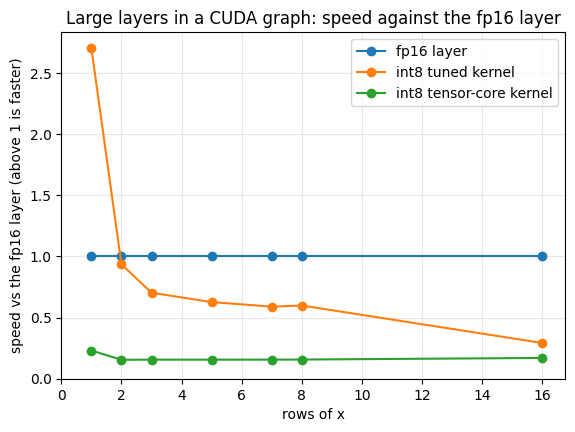

In [73]:
tuned = graph_df[graph_df.way == "int8 tuned kernel"]
by_rows = tuned.groupby("batch").vs_fp.mean()
print("the tuned int8 kernel against the fp16 layer on the large layers, inside a CUDA graph, mean by rows of x (above 1 is faster):")
print(by_rows.round(2).to_string())
dot_by_rows = graph_df[graph_df.way == "int8 tensor-core kernel"].groupby("batch").vs_fp.mean()
print("\nthe tensor-core kernel of Stage 9, same measurement:")
print(dot_by_rows.round(2).to_string())
for _, r in gate_df[~gate_df.ok].iterrows():
    print(f"  not available: {r.layer} batch {r.batch} {r.variant}: {r.error}")
RATIO_1, RATIO_5, RATIO_8 = (float(by_rows.get(b, float("nan"))) for b in (1, 5, 8))
KERNEL_GO = RATIO_5 == RATIO_5 and RATIO_5 > 1.0
if KERNEL_GO:
    print(f"\nGATE: GO. At 5 rows the tuned int8 kernel is {RATIO_5:.2f}x the fp16 layer on the large layers (1 row: {RATIO_1:.2f}x, 8 rows: {RATIO_8:.2f}x). Continue.")
else:
    print("\nGATE: NO-GO on this GPU: at 5 rows the tuned int8 kernel is not faster than the fp16 layer on the large layers. "
          "The rest of the notebook still measures what it gives, and the tables above say where the time goes.")
mean_graph = graph_df.groupby(["way", "batch"], sort=False).vs_fp.mean().reset_index()
line_groups(mean_graph, "batch", "vs_fp", "way", "Large layers in a CUDA graph: speed against the fp16 layer", "speed vs the fp16 layer (above 1 is faster)",
            xlabel="rows of x", save="stage10_layer_graph")

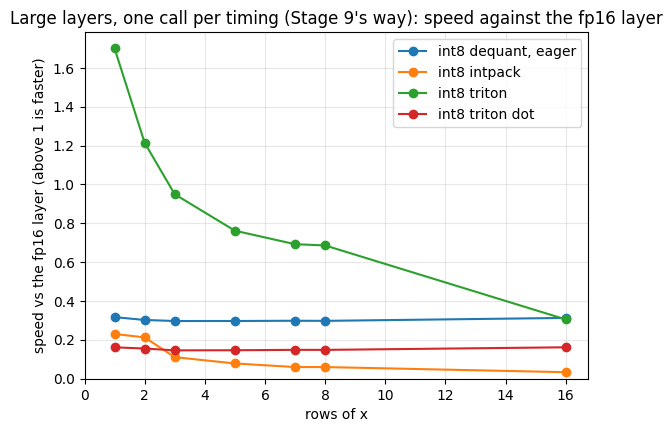

In [74]:
eager = gate_df[gate_df.layer.isin(LARGE) & gate_df.ok & gate_df.variant.isin(["int8 dequant, eager", "int8 intpack", "int8 triton", "int8 triton dot"])]
mean_eager = eager.groupby(["variant", "batch"], sort=False).vs_fp.mean().reset_index()
line_groups(mean_eager, "batch", "vs_fp", "variant", "Large layers, one call per timing (Stage 9's way): speed against the fp16 layer", "speed vs the fp16 layer (above 1 is faster)",
            xlabel="rows of x", save="stage10_layer_eager")

**How to read it.**

- **The tuning table.** `cfg_variant` by rows of x is the kernel the tuner chose. `share_of_copy` is the bandwidth it reaches for the stored bytes (timed in a graph, so it can exceed the copy figure, which counts reads and writes while this kernel only reads). If the winner of a large layer sits at the edge of its grid, the grid was too small. `failed` counts candidates that did not compile or launch.
- **The correctness table** is a precondition, not a result: the notebook stops if the kernel disagrees with the dequantize path or if a wrong scale is not caught. It lists which kernel ran at each row count.
- **The gate, in a graph.** `vs_fp` above one means faster than the fp16 layer. Rows 5, 7 and 8 run the same compiled kernel (it pads to 8), so near-equal numbers there mean the kernel does not care how many of the 8 rows are real.
- **The gate, eager.** The Stage 9 way includes one launch per call, which for a Triton kernel is about as large as a small layer. The difference between the two charts is the launch cost, and it is the reason this stage exists.
- **The tensor-core kernel** is there to answer "was Stage 9's kernel just badly tiled?".
- **The verdict is about one layer.** A pass also has norms, attention and the KV cache. Section 2 measures the pass.

**What this run shows.**

- **Correct, and the tuner chose as predicted.** The largest relative error is 7.8e-4 over 165 cases (rows 1 to 9, 16 and 37), and a wrong scale is off by at least 0.13. The one-token kernel won at 1 row on all 15 shapes, `gemvm` at 2, 4 and 8 rows on all 15, and `dequant` at 16 and 128 rows on all 15 (in the first run `dot` won one shape at 16).
- **The gate is a no-go.** In a graph, on the three large layers, the tuned kernel against the fp16 layer is 2.7x at 1 row, 0.94x at 2, 0.70x at 3, 0.63x at 5, 0.59x at 7, 0.60x at 8 and 0.29x at 16. The 1-row figure is flattered: the fp16 `lm_head` takes 5.2 ms at 1 row but 2.7 ms at 2 rows in a graph (cause: D1). The two MLP layers, which do not show it, give 2.1x and 1.7x.
- **`gemvm` is not memory-bound.** Its time grows with the rows (`lm_head`: 1.2 ms at 1 row, 2.4 at 2, 3.1 at 4, 3.8 at 8) and its bandwidth falls from 202 GB/s (the one-token kernel) to 97, 76 and 61 GB/s, about a quarter of the copy bandwidth at 8 rows. Going from 5 to 8 rows costs 6% to 7% more, so the padding to 8 behaves as designed. Going from 3 to 5 rows is not smooth: on `gate/up` the 3-row layer (0.26 ms) is slower than the 5-row one (0.22 ms), so the tile the tuner chose for the 3 to 4 row bucket is a worse one.
- **The grid was too small.** 20 of the 21 winners on matrices of 10 million weights or more are the largest tile in the grid (`BLOCK_N` 4, `BLOCK_K` 256), and 32 of the 45 `gemvm` winners use the smallest warp count. A larger grid might help; I did not run one.
- **Not FMA-bound either.** At the capped clock (correction above) the kernel reaches 0.19, 0.30 and 0.49 trillion multiply-adds a second on `lm_head` at 2, 4 and 8 rows, 8%, 13% and 21% of the 2.3 trillion peak. So it is neither memory-bound nor FMA-bound: there is real inefficiency in it, on top of a ceiling that is lower at 8 rows than the boost-clock figure suggests. My guess is the three-dimensional accumulator and the conversion of each int8 weight; I did not profile it.
- **The tensor-core kernel is not a tiling problem.** Its time barely moves with the rows (0.81 to 0.85 ms on `gate/up` from 1 to 16 rows), it is 3.7 to 5.1 times slower than `gemvm` at 5 rows, and it is 0.11x to 0.21x of the fp16 layer from 2 rows up.

---
## 2. A forward pass that lives in a graph

**Goal:** measure the cost of feeding a block of tokens through a whole model in one CUDA graph replay, against feeding one token, for fp16 and int8, and check that the multi-row kernel does not change what the model computes.

**Concept.** `StaticForward` (in `minivllm/draft.py`) is a forward pass for a *fixed* number of tokens `T` over the static KV cache of Stage 7. Everything a graph needs to replay is a static buffer: the token ids `[1, T]` and their positions `[T]` are device tensors that are overwritten before each replay, the attention mask is computed from the positions *inside* the captured pass (a key at column `c` is visible to the token at position `p` if `c <= p`), the new keys are written at those positions, and the logits are the output tensor of the graph. With `all_logits`, the output is `[1, T, vocab]`, one set of logits per fed token, which is what a checking pass needs.

The step of a plain decoder is `T = 1`. The checking pass of speculation with `k` drafts is `T = k + 1`. A round that finds fewer than `k` drafts pads the block with zeros; the rows after the real drafts are ignored.

This is also what makes the **rollback free**. A pass writes its `T` keys at the positions it is given, and a row only attends to keys at or before its own position. If the drafts after the first wrong one are rejected, the decoder just does not advance its length: the stale keys sit in the cache beyond the length, no row can see them, and the next pass overwrites them before any row could. Nothing is copied or cleared. (The tests keep a control for this: a mask that lets rows see later keys breaks the output.)

**What we measure.** For each model size, for fp16 and int8: the time of a pass of 1, 5 and 7 tokens, replayed from a graph and run eagerly, with the median and the spread over `ITERS` repeats, the time relative to the one-token pass of the same weights and mode (the **`v`** of the cost model: how much a checking pass costs in units of a plain step), and the share of the bandwidth floor. Then, at the 1.5B size, the logits of the multi-row kernel against the dequantize path for the same weights, and against fp16.

> **Predict** (written before running anything below).
>
> - **fp16, in a graph:** a pass of 5 or 7 tokens costs 1.05 to 1.2 times a one-token pass (Stage 9 measured 1.05 to 1.13 eagerly, where launches hide part of the extra work).
> - **int8, in a graph:** a pass of 5 or 7 tokens costs 1.1 to 1.6 times a one-token pass. The weights are still read once, but the FMA work of 8 rows per weight is not free (section 1). This is the number that decides the speculation results, and the one I am least sure of.
> - **Int8 in a graph is still faster than fp16 in a graph at 5 and 7 tokens** at 1.5B and 3B, if the gate was a go.
> - **Eager int8 blocks are much slower than graph blocks** (launch cost: about 250 kernel launches per pass at 1.5B), and eager fp16 blocks are closer to their graph version.
> - **Accuracy:** the multi-row kernel's logits differ from the dequantize path's by less than the int8 rounding itself: a KL divergence two orders of magnitude below that of int8 against fp16 (Stage 8: a few thousandths of a nat), and the same top token at every position.

In [75]:
BLOCK = []


def block_rows(size, variant, m):
    # a pass of T tokens (all logits when T > 1, argmax on top) on top of CTX cached tokens: replayed from a graph, and run eagerly
    nbytes = weight_bytes_read(m)
    floor_ms = 1000 * nbytes / (COPY_BW * 1e9)
    for mode, capture in (("graph", True), ("eager", False)):
        one = None
        for T in BLOCK_TOKENS:
            cache = StaticKVCache(m.n_layers, m.n_kv, CTX + 16, m.hd, m.device, m.dtype)
            f = StaticForward(m, cache, T, all_logits=T > 1, capture=capture)
            f.pos.copy_(torch.arange(CTX, CTX + T, device=device))
            st = time_stats(lambda: f.replay().argmax(-1), iters=ITERS)
            ok = mode == "eager" or f.mode == "graph"
            one = st["median_ms"] if one is None else one
            BLOCK.append({"model": size, "variant": variant, "mode": mode, "tokens": T, "ok": ok, "error": f.graph_error if mode == "graph" else None,
                          "median_ms": st["median_ms"], "spread": st["spread"], "rel_to_one_token": st["median_ms"] / one,
                          "floor_ms": floor_ms, "share": floor_ms / st["median_ms"]})
            del f, cache
            gc.collect()


for size in SIZES:
    m16, _ = load_model(size)
    q = quantize_model(m16, path="triton")           # shares the embedding table and the norms; the int8 matrices are new
    print(f"{size}: fp16 and int8 loaded, {gib():.2f} GiB in use")
    block_rows(size, "fp16", m16)
    del m16                                          # not needed again: free the fp16 matrices before the int8 runs
    gc.collect(); torch.cuda.empty_cache()
    block_rows(size, "int8", q)
    print(f"{size} done")
    del q
    gc.collect(); torch.cuda.empty_cache()

block_df = pd.DataFrame(BLOCK)
if not block_df.ok.all():
    print("WARNING: some passes could not be captured in a graph and were timed eagerly:", block_df[~block_df.ok].error.dropna().unique()[:2])
block_df[["model", "variant", "mode", "tokens", "ok", "median_ms", "spread", "rel_to_one_token", "floor_ms", "share", "error"]].round(3)

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

0.5B: fp16 and int8 loaded, 1.70 GiB in use
0.5B done


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

1.5B: fp16 and int8 loaded, 4.62 GiB in use
1.5B done


Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]

3B: fp16 and int8 loaded, 9.03 GiB in use
3B done


,model,variant,mode,tokens,ok,median_ms,spread,rel_to_one_token,floor_ms,share,error
0,0.5B,fp16,graph,1,True,8.992,0.020,1.000,4.063,0.452,None
1,0.5B,fp16,graph,5,True,9.071,0.010,1.009,4.063,0.448,None
2,0.5B,fp16,graph,7,True,9.119,0.014,1.014,4.063,0.446,None
3,0.5B,fp16,eager,1,True,22.661,0.018,1.000,4.063,0.179,None
4,0.5B,fp16,eager,5,True,23.381,0.022,1.032,4.063,0.174,None
5,0.5B,fp16,eager,7,True,23.223,0.016,1.025,4.063,0.175,None
6,0.5B,int8,graph,1,True,6.799,0.010,1.000,2.036,0.299,None
7,0.5B,int8,graph,5,True,11.600,0.008,1.706,2.036,0.175,None
8,0.5B,int8,graph,7,True,12.121,0.035,1.783,2.036,0.168,None
9,0.5B,int8,eager,1,True,32.403,0.019,1.000,2.036,0.063,None


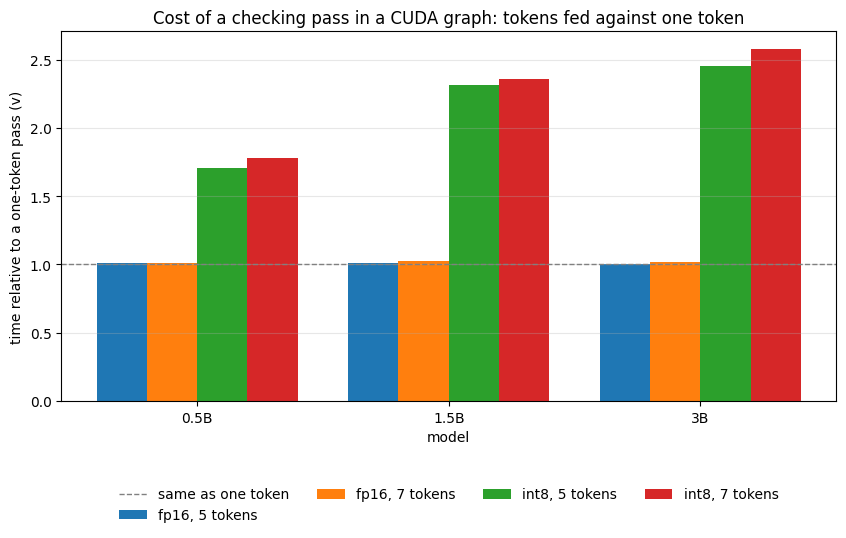

the one-token pass (argmax included), ms:
mode           graph  eager  eager / graph
model variant                             
0.5B  fp16      8.99  22.66           2.52
      int8      6.80  32.40           4.77
1.5B  fp16     19.63  27.42           1.40
      int8     11.53  38.39           3.33
3B    fp16     36.30  38.13           1.05
      int8     19.84  48.94           2.47


In [76]:
g = block_df[(block_df["mode"] == "graph") & block_df.ok & (block_df.tokens > 1)]
series = {f"{v}, {t} tokens": [float(g[(g.model == s) & (g.variant == v) & (g.tokens == t)].rel_to_one_token.iloc[0]) if len(g[(g.model == s) & (g.variant == v) & (g.tokens == t)]) else float("nan")
                              for s in SIZES] for v in ("fp16", "int8") for t in BLOCK_TOKENS if t > 1}
grouped_bar(SIZES, series, "Cost of a checking pass in a CUDA graph: tokens fed against one token", "time relative to a one-token pass (v)", hline=1.0,
            hline_label="same as one token", xlabel="model", figsize=(10, 4.8), save="stage10_block_cost")
step_view = block_df[(block_df.tokens == 1) & block_df.ok].pivot_table(index=["model", "variant"], columns="mode", values="median_ms").reindex(columns=["graph", "eager"])
step_view["eager / graph"] = step_view["eager"] / step_view["graph"]
print("the one-token pass (argmax included), ms:")
print(step_view.round(2).to_string())

In [77]:
# the multi-row kernel inside a model: block logits of the int8 model through the Triton path, through the dequantize path, and of fp16
def block_logits(m, ids, T):
    d = GraphDecoder(m, len(ids) + 16, ks=(T - 1,))          # captured, so the kernel under test is the one in the graph
    d._prefill(ids[:-T])
    out = d.verify[T - 1].run(ids[-T:], len(ids) - T).float().cpu().clone()
    del d
    return out


m16, _ = load_model(ACC_SIZE)
q = quantize_model(m16, path="triton")
ids = PROMPT_IDS["open"][0]
BLOCK_ACC = []
for T in [t for t in BLOCK_TOKENS if t > 1] + ([] if QUICK else [2, 8]):
    fp = block_logits(m16, ids, T)
    tr = block_logits(q, ids, T)
    set_path(q, "dequant")
    dq = block_logits(q, ids, T)
    set_path(q, "triton")
    BLOCK_ACC += [{"tokens": T, "compare": "int8 triton vs int8 dequant", **logit_error(dq, tr)},
                  {"tokens": T, "compare": "int8 dequant vs fp16", **logit_error(fp, dq)},
                  {"tokens": T, "compare": "int8 triton vs fp16", **logit_error(fp, tr)}]
del m16, q
gc.collect(); torch.cuda.empty_cache()
bacc_df = pd.DataFrame(BLOCK_ACC)
bacc_df.round(5)

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

,tokens,compare,max_abs,mean_abs,kl,top1
0,5,int8 triton vs int8 dequant,0.03418,0.00446,0.00002,1.00000
1,5,int8 dequant vs fp16,1.06641,0.08043,0.00114,1.00000
2,5,int8 triton vs fp16,1.09619,0.08180,0.00114,1.00000
3,7,int8 triton vs int8 dequant,0.03418,0.00495,0.00002,1.00000
4,7,int8 dequant vs fp16,1.05334,0.07874,0.00123,0.85714
5,7,int8 triton vs fp16,1.08264,0.07981,0.00127,0.85714
6,2,int8 triton vs int8 dequant,0.04297,0.00613,0.00002,1.00000
7,2,int8 dequant vs fp16,1.06006,0.10609,0.00108,1.00000
8,2,int8 triton vs fp16,1.10303,0.10893,0.00112,1.00000
9,8,int8 triton vs int8 dequant,0.03516,0.00493,0.00002,1.00000


**How to read it.**

- **`rel_to_one_token`** is the `v` of the cost model for a graph decoder: the time of a checking pass over the time of a plain step of the same weights. Speculation with a free guesser pays while `tokens per round / v` is above one, so every 0.1 of `v` matters. Compare fp16 with int8 at the same block length.
- **`eager / graph` for the one-token pass** is what the graph removes: the launches of each pass.
- **The share of the floor** can exceed one for a pass that only reads weights, because the measured copy bandwidth counts bytes read and written.
- **The accuracy table.** The first comparison is the one that matters: the two int8 paths hold the same weights, so their logits should agree to far less than the int8 error itself and take the same top token. The other two rows repeat Stage 8's int8 against fp16 distance for the same blocks. A row marked ok = False above means the capture fell back to eager, and the table says why.

**What this run shows.**

- **fp16 checking passes are free in a graph.** `v` is 1.00 to 1.03 at every size and for blocks of 5 and 7 tokens.
- **int8 checking passes are not.** `v` is 1.71 and 1.78 at 0.5B, 2.31 and 2.36 at 1.5B, and 2.45 and 2.58 at 3B (blocks of 5 and 7), against my prediction of 1.1 to 1.6. A 5-token pass takes 26.7 ms for int8 against 19.9 ms for fp16 at 1.5B, and 48.7 ms against 36.4 ms at 3B. So the int8 pass is slower than the fp16 pass at every size once more than one token goes through, while the one-token int8 pass is faster (11.5 ms against 19.6 ms at 1.5B, 19.8 ms against 36.3 ms at 3B; the fp16 figures carry the `lm_head` effect of D1). The int8 5-token pass reaches 0.24 and 0.26 of its floor at 1.5B and 3B, against 0.55 and 0.64 for one token.
- **The extra cost is the kernel and nothing else.** Adding up the tuned layer times of section 1 over every matrix of a model, 8 rows cost 17.2 ms more than 1 row at 1.5B and 33.9 ms more at 3B. The measured extra of a 7-token pass over a 1-token pass is 15.7 ms and 31.3 ms, within about a tenth. (At 0.5B the small layers are latency-bound in the tuning timings, so the sum overshoots; ignore it there.)
- **Eager passes hide it.** An eager pass of 5 or 7 tokens costs 0.98 to 1.12 times a one-token pass for both formats, because launches dominate. The graph takes the one-token pass down by 2.5x, 1.4x and 1.1x for fp16 and by 4.8x, 3.3x and 2.5x for int8 (0.5B, 1.5B, 3B), which is why a graph is where the int8 kernel can pay at all.
- **The multi-row kernel computes the right thing inside a model.** Its logits differ from the dequantize path's with a KL divergence of 2e-5 to 3e-5 (int8 against fp16 is 1.1e-3 to 1.3e-3, about fifty-five times more), the same top token at every position, and a largest logit difference of 0.03 to 0.04. The loss in this stage is speed, not accuracy.

---
## 3. Plain decoding, in a graph, end to end

**Goal:** what quantization buys a decoder at batch 1, measured as a *rate* of a whole generation and not as a step.

**Concept.** `GraphDecoder.plain` (in `minivllm/graph_decode.py`) prefills the prompt eagerly through the static cache (a prompt is a big block, so a captured pass would not help), then feeds each new token through the captured one-token pass. The token never leaves the GPU between steps: the argmax of one pass is copied into the input buffer of the next, and the generation is read back once at the end. So a step costs one graph launch and a few tiny kernels, and nothing else happens in Python.

We time a 96-token generation (an open-text prompt; the content does not change the step) `PLAIN_RUNS` times for each of: fp16 eager (the engine of Stages 2 to 9, `generate_cached`), fp16 in the graph decoder, int8 eager and int8 in the graph decoder, at 0.5B, 1.5B and 3B. The rate is the decode rate (tokens after the first, over the sum of the per-token times, prefill excluded), as the median of the runs with the spread, plus the whole-generation rate for reference. Each output is compared with the eager output of the same weights (a difference must be a near-tie, as in Stages 6 to 9).

> **Predict** (written before running anything below), from the Stage 9 step table (fp16 eager step against int8 and fp16 graph steps):
>
> - **fp16, graph against eager:** a gain that is large for the smallest model and almost none for the largest, because the 0.5B step is mostly launches and the 3B step is mostly weight reads: roughly 2 times at 0.5B, 1.4 times at 1.5B, 1.05 times at 3B.
> - **int8 in a graph against fp16 in a graph:** about 1.4 to 1.7 times, growing with the model (the step is more bandwidth-bound as the model grows), as in Stage 9's step table.
> - **int8 in a graph against fp16 eager** (the baseline of every earlier stage): roughly 3 times at 0.5B, 2 times at 1.5B and 1.8 times at 3B.
> - **int8 eager is slower than fp16 eager** at every size (Stage 9: 1.2 to 1.4 times slower), which is why the graph matters here.
> - The loop adds a little to the Stage 9 steps (the argmax and the copies between passes, attention over the whole static buffer), so rates should be within about 10% of 1 / the step.

In [78]:
PLAIN = []


def run_eager(m, ids):
    full, st = generate_cached(m, torch.tensor([ids], device=device), MAX_NEW)
    return full[0, len(ids):].tolist(), st


def time_plain(size, variant, m, ids):
    ref = greedy(m, ids, MAX_NEW)
    dec = GraphDecoder(m, MAX_LEN)
    for mode, run in (("eager", lambda: run_eager(m, ids)), ("graph", lambda: dec.plain(ids, MAX_NEW))):
        run()                                                                  # warm-up
        rates, totals, same, tie = [], [], True, None
        for _ in range(PLAIN_RUNS):
            t0 = time.perf_counter(); torch.cuda.synchronize()
            tokens, st = run()
            torch.cuda.synchronize(); wall = time.perf_counter() - t0
            rates.append((MAX_NEW - 1) / sum(st["itl"]))
            totals.append(MAX_NEW / wall)
            if tokens != ref:
                same = False
                tie = tie_gap(m, ids, ref, tokens)
        med = float(np.median(rates))
        PLAIN.append({"model": size, "variant": variant, "mode": mode, "ok": mode == "eager" or dec.mode == "graph", "error": dec.graph_error if mode == "graph" else None,
                      "decode_tok_s": med, "spread": (max(rates) - min(rates)) / med, "total_tok_s": float(np.median(totals)), "step_ms": 1000 / med,
                      "same_as_eager": same, "first_mismatch": None if tie is None else tie[0], "logit_gap": None if tie is None else tie[1]})
    del dec
    gc.collect(); torch.cuda.empty_cache()


for size in SIZES:
    m16, _ = load_model(size)
    q = quantize_model(m16, path="triton")
    ids = PROMPT_IDS["open"][0]
    print(f"{size}: fp16 and int8 loaded, {gib():.2f} GiB in use")
    time_plain(size, "fp16", m16, ids)
    del m16
    gc.collect(); torch.cuda.empty_cache()
    time_plain(size, "int8", q, ids)
    print(f"{size} done")
    del q
    gc.collect(); torch.cuda.empty_cache()

plain_df = pd.DataFrame(PLAIN)
PLAIN_EXACT = all(r["same_as_eager"] or (r["logit_gap"] is not None and r["logit_gap"] < NEAR_TIE) for r in PLAIN)
plain_df[["model", "variant", "mode", "ok", "decode_tok_s", "spread", "total_tok_s", "step_ms", "same_as_eager", "first_mismatch", "logit_gap", "error"]].round(3)

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

0.5B: fp16 and int8 loaded, 1.70 GiB in use
0.5B done


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

1.5B: fp16 and int8 loaded, 4.63 GiB in use
1.5B done


Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]

3B: fp16 and int8 loaded, 9.04 GiB in use
3B done


,model,variant,mode,ok,decode_tok_s,spread,total_tok_s,step_ms,same_as_eager,first_mismatch,logit_gap,error
0,0.5B,fp16,eager,True,45.690,0.088,45.646,21.886,True,None,None,None
1,0.5B,fp16,graph,True,110.732,0.004,108.644,9.031,True,None,None,None
2,0.5B,int8,eager,True,31.498,0.028,31.416,31.748,True,None,None,None
3,0.5B,int8,graph,True,167.596,0.002,157.963,5.967,True,None,None,None
4,1.5B,fp16,eager,True,37.601,0.064,37.571,26.595,True,None,None,None
5,1.5B,fp16,graph,True,46.950,0.046,46.715,21.299,True,None,None,None
6,1.5B,int8,eager,True,26.752,0.018,26.586,37.380,True,None,None,None
7,1.5B,int8,graph,True,87.785,0.009,84.784,11.391,True,None,None,None
8,3B,fp16,eager,True,18.523,0.440,18.531,53.987,True,None,None,None
9,3B,fp16,graph,True,25.013,0.081,24.984,39.979,True,None,None,None


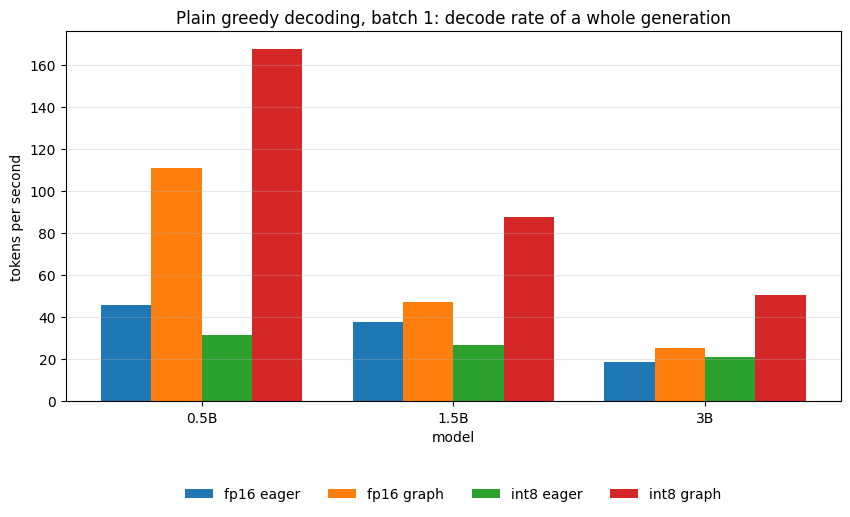

every output equals the eager output of the same weights, or differs at a near-tie: True


,model,fp16 graph / fp16 eager,int8 eager / fp16 eager,int8 graph / fp16 graph,int8 graph / fp16 eager
0,0.5B,2.42,0.69,1.51,3.67
1,1.5B,1.25,0.71,1.87,2.33
2,3B,1.35,1.14,2.01,2.72


In [79]:
def rate(size, variant, mode):
    r = plain_df[(plain_df.model == size) & (plain_df.variant == variant) & (plain_df["mode"] == mode)]
    return float(r.decode_tok_s.iloc[0]) if len(r) else float("nan")

SERIES = [("fp16", "eager"), ("fp16", "graph"), ("int8", "eager"), ("int8", "graph")]
grouped_bar(SIZES, {f"{v} {m}": [rate(s, v, m) for s in SIZES] for v, m in SERIES}, "Plain greedy decoding, batch 1: decode rate of a whole generation",
            "tokens per second", xlabel="model", figsize=(10, 4.8), save="stage10_plain_rate")
ratio_plain = pd.DataFrame([{"model": s,
                             "fp16 graph / fp16 eager": rate(s, "fp16", "graph") / rate(s, "fp16", "eager"),
                             "int8 eager / fp16 eager": rate(s, "int8", "eager") / rate(s, "fp16", "eager"),
                             "int8 graph / fp16 graph": rate(s, "int8", "graph") / rate(s, "fp16", "graph"),
                             "int8 graph / fp16 eager": rate(s, "int8", "graph") / rate(s, "fp16", "eager")} for s in SIZES])
print("every output equals the eager output of the same weights, or differs at a near-tie:", PLAIN_EXACT)
assert PLAIN_EXACT, f"a graph output differs from eager greedy where the two tokens are not nearly tied (gap of {NEAR_TIE} or more)"
ratio_plain.round(2)

**How to read it.**

- **`decode_tok_s`** is the median over the runs, `spread` the range over the median. The ratios table answers "what does each change buy": the graph alone for fp16, the weight format alone inside the graph, and the two together against the eager fp16 baseline of every earlier stage.
- **int8 eager** is in the table to show what Stage 9 found as a rate: the kernel costs as much in launches as it saves in bytes until a graph removes them.
- **`total_tok_s`** includes the prefill (eager, through the tuned table or the dequantize fallback for the prompt's rows), so it is lower and depends on the prompt length.
- **`same_as_eager`.** A graph step computes attention over the whole static buffer (masked), eager attention over exactly the cached keys, so an output can differ at an fp16 near-tie. The notebook stops if a difference is not a tie.

**What this run shows.**

| model | fp16 eager | fp16 graph | int8 eager | int8 graph |
| --- | ---: | ---: | ---: | ---: |
| 0.5B | 45.7 | 110.7 | 31.5 | 167.6 |
| 1.5B | 37.6 | 46.9 | 26.8 | 87.8 |
| 3B | 18.5 (warm-up) | 25.0 (warm-up) | 21.0 | 50.4 |

(decode tokens per second, median of 5 runs)

- **The 3B fp16 rows were measured during the warm-up of D2** (spreads of 44% eager and 8% graph; steady state is about 26 and 27 tok/s). Every 3B ratio against them is inflated. The fp16 rows are the first timed after each model load, so they are also the noisiest at the other sizes (spreads of 4% to 9%); the int8 rows have spreads of 0.2% to 3%.
- **int8 against fp16, both in a graph:** 1.51x, 1.87x and 2.01x at 0.5B, 1.5B and 3B, growing with the model as predicted (about 1.85x at 3B with the steady-state fp16 rate). The fp16 graph step carries the `lm_head` effect of D1, which is an avoidable cost: for 1.5B, with `lm_head` at its two-row speed the pass-level gain of int8 would be about 1.5x instead of 1.7x (at 0.5B the cost is a larger share of the step and at 3B a smaller one; I did not measure them).
- **The graph against eager, fp16:** 2.42x at 0.5B and 1.25x at 1.5B (1.4x for the one-token pass of section 2). At 3B the table says 1.35x, an artifact of the slow eager row: section 2's passes show the graph does not speed up the fp16 step at 3B (1.1x), since the step is weight reads, not launches. The eager int8 pass is slower than the eager fp16 pass at every size (section 2).
- **int8 in a graph against the eager fp16 baseline:** 3.67x at 0.5B and 2.33x at 1.5B. At 3B the table says 2.72x, but with section 2's eager step the figure is about 1.9x, in line with my prediction of 1.8x.
- **The loop is cheap.** The graph decoder's per-token time is at most 10% above the single-pass time of section 2 (the largest ratios, 1.09 and 1.10, are the 1.5B and 3B fp16 rows) and at or below it for int8.
- **Every output equals the eager output of the same weights** in all 12 runs, so no tie had to be read.

---
## 4. Speculation in the graph

**Goal:** answer the question of the stage. Do int8 weights and speculative decoding multiply?

**Concept.** `GraphDecoder.speculative` is the loop of Stage 6 with the checking pass in a graph. Each round the n-gram lookup proposes up to `k` tokens (a table lookup on the CPU: no model, no cost to speak of), the block `[last accepted token] + drafts` is padded with zeros to length `k + 1`, one captured pass of that fixed length returns the model's own greedy choice after every fed token, and the decoder accepts the longest prefix of drafts that agree with those choices plus the one token the pass adds. A round with no draft at all has nothing to check, so it runs the ordinary one-token pass, not a padded block. The output is the target's own greedy output for any proposer, up to fp16 near-ties.

With a free guesser, Stage 7's cost model reduces to

```
tokens per round  =  (1 - alpha^(k+1)) / (1 - alpha)
speedup over plain decoding of the same weights  =  tokens per round / v
```

where `v` is the checking pass over a plain step (section 2). **Speculation cuts the number of weight reads per token; int8 cuts the bytes per read. If a step is bandwidth-bound the two should multiply.** They multiply exactly only if `v` is the same for both weight formats. The multi-row kernel does more arithmetic per byte than the fp16 layer does, so `v` for int8 is probably higher, and the product is an upper bound.

**What we measure.** Targets 1.5B and 3B, three workloads (`copy`, `code`, `open`), `k` in `{4, 6}`, the n-gram lookup, and four setups, each with its own plain baseline (the median of `BASELINE_RUNS` timings):

| setup | engine |
| --- | --- |
| fp16 plain, fp16 n-gram | the eager engine of Stage 9 (the baseline of every earlier stage) |
| fp16 plain, fp16 n-gram | the graph decoder |
| int8 plain, int8 n-gram | the graph decoder |

Every speedup is a ratio of tokens per second of whole generations (prefill included) against *each* of fp16 eager plain, fp16 graph plain and int8 graph plain, so the gain of the graph, the gain of int8 and the gain of speculation can be read apart. Then the question itself, per workload and `k`: the gain of int8 alone, the gain of speculation alone, their product, and what int8 plus speculation actually gives.

**Exactness.** For each setup, the first prompt of each workload, 32 tokens: the speculative output against the same weights' plain eager greedy output; a difference must be an fp16 near-tie (the logit gap at the first difference is read, and the notebook stops if it is not), with an fp16 eager speculative run as the control that near-ties happen without any graph or int8. And a **control that must fail**: the same decoder with a mask that lets every row see all keys up to the end of the block must produce a different output.

For reference, what the cost model says before any measurement (nothing here is measured): the speedup of a free guesser over plain decoding of the same weights, for a few acceptance rates `alpha` and checking costs `v`, at `k = 4`:

In [80]:
grid = pd.DataFrame({f"v = {v}": [expected_tokens_per_round(a, 4) / v for a in (0.2, 0.3, 0.5, 0.7, 0.8, 0.9, 0.99)] for v in (1.0, 1.1, 1.2, 1.4, 1.7, 2.0)},
                    index=[f"alpha = {a}" for a in (0.2, 0.3, 0.5, 0.7, 0.8, 0.9, 0.99)])
grid.round(2)

,v = 1.0,v = 1.1,v = 1.2,v = 1.4,v = 1.7,v = 2.0
alpha = 0.2,1.25,1.14,1.04,0.89,0.74,0.62
alpha = 0.3,1.43,1.30,1.19,1.02,0.84,0.71
alpha = 0.5,1.94,1.76,1.61,1.38,1.14,0.97
alpha = 0.7,2.77,2.52,2.31,1.98,1.63,1.39
alpha = 0.8,3.36,3.06,2.80,2.40,1.98,1.68
alpha = 0.9,4.10,3.72,3.41,2.93,2.41,2.05
alpha = 0.99,4.90,4.46,4.08,3.50,2.88,2.45


> **Predict** (written before running anything below), from the Stage 9 acceptance table for the n-gram lookup and the section 2 and 3 predictions:
>
> - **(a) Speculation helps both weight formats on `copy` and `code`**, where the lookup finds drafts that the model accepts (Stage 9: `alpha` of 0.7 to 0.99), and is about neutral on `open` text, where it rarely finds a draft (`alpha` near 0.2 to 0.3) and rounds with no draft are plain steps.
> - **(b) The gains multiply, less a little.** Int8 plus n-gram beats int8 plain and beats fp16 n-gram on `copy` and `code`, and is within about 10% of the product of the two separate gains, below it if `v` is higher for int8 (a `v` of 1.1 for fp16 and 1.4 for int8 would give 80% of the product). On `open` text, int8 plus n-gram is about int8 plain.
> - **(c) The headline,** against fp16 eager plain: if the arithmetic of sections 2 and 3 holds, int8 plus n-gram reaches roughly 4 times at 1.5B and 5 to 6 times at 3B on `copy`, 3 to 4 times on `code` and roughly the int8 graph plain gain (2 times and 1.8 times) on `open`. This is projected from earlier numbers, not measured.
> - **(d) The graph removes the cost that an eager n-gram loop pays at the larger models too:** fp16 n-gram in a graph is faster than fp16 n-gram eager everywhere, by a margin that shrinks with the model.
> - **(e) The cost model fed with the measured `v` and `alpha` predicts the speedup to within about a quarter** (there is no draft model, so no eager first guess to overstate it), and overstates `open` text, where rounds with no draft are cheaper than the model assumes.
> - **(f) Exactness:** every difference from plain greedy is a near-tie; the fp16 eager control shows near-ties without any graph or int8; the non-causal control breaks the output.

In [81]:
SPEC_ROWS, EXACT_ROWS, CONTROL_ROWS = [], [], []
NGRAM = {"n-gram": PromptLookup()}
WL = ["copy", "code", "open"]


def sweep(t, weights, engine, tm, dec=None):
    kw = {} if dec is None else {"plain_fn": dec.plain, "spec_fn": dec.speculative}
    rows = sweep_proposers(tm, PROMPT_IDS, MAX_NEW, KS, NGRAM, verbose=False, baseline_runs=BASELINE_RUNS, **kw)
    SPEC_ROWS.extend({"target": t, "weights": weights, "engine": engine, **r} for r in rows)


def exact_rows(t, setup, tm, run):
    # first prompt of each workload, 32 tokens: `run(ids)` against the same weights' plain eager greedy output, with the logit gap at a difference
    for name in WL:
        ids = PROMPT_IDS[name][0]
        ref = greedy(tm, ids, 32)
        i, gap = tie_gap(tm, ids, ref, run(ids))
        EXACT_ROWS.append({"target": t, "setup": setup, "workload": name, "first_mismatch": i, "logit_gap": gap})


for tsize in TARGETS:
    t16, _ = load_model(tsize)
    t8 = quantize_model(t16, path="triton")
    dec16, dec8 = GraphDecoder(t16, MAX_LEN, ks=KS), GraphDecoder(t8, MAX_LEN, ks=KS)
    print(f"{tsize}: fp16 and int8 loaded, decoders captured ({dec16.mode}, {dec8.mode}), {gib():.2f} GiB in use")
    if dec16.graph_error or dec8.graph_error:
        print("  graph capture problem:", dec16.graph_error or dec8.graph_error)
    sweep(tsize, "fp16", "eager", t16)
    print(f"  {tsize}: fp16 eager done")
    sweep(tsize, "fp16", "graph", t16, dec16)
    print(f"  {tsize}: fp16 graph done")
    sweep(tsize, "int8", "graph", t8, dec8)
    print(f"  {tsize}: int8 graph done")
    exact_rows(tsize, "fp16 eager n-gram (control)", t16, lambda ids: generate_speculative(t16, ids, 32, k=4, proposer=PromptLookup())[0])
    exact_rows(tsize, "fp16 graph n-gram", t16, lambda ids: dec16.speculative(ids, 32, 4, PromptLookup())[0])
    exact_rows(tsize, "int8 graph n-gram", t8, lambda ids: dec8.speculative(ids, 32, 4, PromptLookup())[0])
    exact_rows(tsize, "int8 graph plain", t8, lambda ids: dec8.plain(ids, 32)[0])
    if tsize == TARGETS[0]:
        broken = GraphDecoder(t16, MAX_LEN, ks=(4,), causal=False)          # the negative control: rows may see keys after their own position
        for name in WL:
            ids = PROMPT_IDS[name][0]
            ref = greedy(t16, ids, 32)
            CONTROL_ROWS.append({"target": tsize, "workload": name, "differs": broken.speculative(ids, 32, 4, PromptLookup())[0] != ref})
        del broken
    del dec16, dec8, t16, t8
    gc.collect(); torch.cuda.empty_cache()

exact_df, control_df = pd.DataFrame(EXACT_ROWS), pd.DataFrame(CONTROL_ROWS)
SPEC_EXACT = all(r["first_mismatch"] is None or r["logit_gap"] < NEAR_TIE for r in EXACT_ROWS)
CONTROL_BREAKS = bool(control_df.differs.any())
print(exact_df.round(3).to_string(index=False))
print("\nevery speculative difference is a near-tie:", SPEC_EXACT)
print("a mask that lets rows see later keys changes the output (so the check can fail):", CONTROL_BREAKS)
assert SPEC_EXACT, f"a speculative output differs from plain greedy where the two tokens are not nearly tied (logit gap of {NEAR_TIE} or more): that is not fp16 rounding"
assert CONTROL_BREAKS, "the non-causal control did not change any output, so the exactness check cannot be trusted"

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

1.5B: fp16 and int8 loaded, decoders captured (graph, graph), 4.65 GiB in use
  1.5B: fp16 eager done
  1.5B: fp16 graph done
  1.5B: int8 graph done


Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]

3B: fp16 and int8 loaded, decoders captured (graph, graph), 9.04 GiB in use
  3B: fp16 eager done
  3B: fp16 graph done
  3B: int8 graph done
target                       setup workload  first_mismatch  logit_gap
  1.5B fp16 eager n-gram (control)     copy             NaN        NaN
  1.5B fp16 eager n-gram (control)     code             NaN        NaN
  1.5B fp16 eager n-gram (control)     open             NaN        NaN
  1.5B           fp16 graph n-gram     copy             NaN        NaN
  1.5B           fp16 graph n-gram     code             NaN        NaN
  1.5B           fp16 graph n-gram     open             NaN        NaN
  1.5B           int8 graph n-gram     copy             NaN        NaN
  1.5B           int8 graph n-gram     code             2.0      0.008
  1.5B           int8 graph n-gram     open             NaN        NaN
  1.5B            int8 graph plain     copy             NaN        NaN
  1.5B            int8 graph plain     code             NaN        NaN
  1.5B

In [82]:
spec_df = pd.DataFrame(SPEC_ROWS)
spec_df["setup"] = spec_df.weights + " " + spec_df.engine + " " + spec_df.proposer


def plain_rate(weights, engine):
    r = spec_df[(spec_df.weights == weights) & (spec_df.engine == engine) & (spec_df.proposer == "plain")]
    return r.set_index(["target", "workload"]).tok_s


base_eager, base_g16, base_g8 = plain_rate("fp16", "eager"), plain_rate("fp16", "graph"), plain_rate("int8", "graph")
spec_df["vs_fp16_eager"] = [r.tok_s / base_eager[(r.target, r.workload)] for r in spec_df.itertuples()]
spec_df["vs_fp16_graph"] = [r.tok_s / base_g16[(r.target, r.workload)] for r in spec_df.itertuples()]
spec_df["vs_int8_graph"] = [r.tok_s / base_g8[(r.target, r.workload)] for r in spec_df.itertuples()]
plain_ms = spec_df[spec_df.proposer == "plain"].set_index(["target", "weights", "engine", "workload"]).target_ms
# the cost model fed with this row's own measured numbers (tokens per round from its alpha; v and the guess from its own timings), against plain of the same weights and engine
spec_df["v"] = [float("nan") if r.proposer == "plain" else r.target_ms / plain_ms[(r.target, r.weights, r.engine, r.workload)] for r in spec_df.itertuples()]
spec_df["pred_x"] = [float("nan") if r.proposer == "plain" else r.expected_tokens * plain_ms[(r.target, r.weights, r.engine, r.workload)] / (r.guess_ms + r.target_ms)
                     for r in spec_df.itertuples()]
view = spec_df[spec_df.proposer != "plain"][["target", "workload", "setup", "k", "alpha", "tokens_per_step", "draft_found_frac", "target_ms", "v", "speedup_x", "pred_x",
                                             "vs_fp16_eager", "vs_fp16_graph", "vs_int8_graph", "n_exact", "n_prompts"]]
view.round(2)

,target,workload,setup,k,alpha,tokens_per_step,draft_found_frac,target_ms,v,speedup_x,pred_x,vs_fp16_eager,vs_fp16_graph,vs_int8_graph,n_exact,n_prompts
1,1.5B,copy,fp16 eager n-gram,4,0.79,2.48,0.72,29.11,1.05,2.27,3.15,2.27,1.67,1.01,3,3
2,1.5B,copy,fp16 eager n-gram,6,0.80,2.71,0.70,29.06,1.04,2.49,3.78,2.49,1.83,1.11,3,3
4,1.5B,code,fp16 eager n-gram,4,0.70,2.18,0.68,30.77,1.15,1.86,2.43,1.86,1.39,0.84,3,3
5,1.5B,code,fp16 eager n-gram,6,0.71,2.36,0.66,29.71,1.11,2.08,2.82,2.08,1.55,0.94,3,3
7,1.5B,open,fp16 eager n-gram,4,0.29,1.14,0.37,27.92,1.05,1.09,1.34,1.09,0.82,0.49,3,3
8,1.5B,open,fp16 eager n-gram,6,0.30,1.15,0.37,27.89,1.05,1.10,1.36,1.10,0.83,0.49,2,3
10,1.5B,copy,fp16 graph n-gram,4,0.79,2.48,0.72,20.23,1.02,2.37,3.22,3.24,2.37,1.44,3,3
11,1.5B,copy,fp16 graph n-gram,6,0.80,2.71,0.70,20.30,1.03,2.58,3.86,3.52,2.58,1.56,3,3
13,1.5B,code,fp16 graph n-gram,4,0.72,2.18,0.69,20.10,1.01,2.10,2.83,2.82,2.10,1.27,3,3
14,1.5B,code,fp16 graph n-gram,6,0.71,2.36,0.67,20.31,1.02,2.24,3.09,3.01,2.24,1.36,3,3


In [83]:
# do the gains multiply? per target, workload and k: int8 alone, speculation alone, their product, and int8 plus speculation measured
MULT = []
for t in TARGETS:
    for w in WL:
        for k in KS:
            def tok_s(weights, engine, proposer):
                r = spec_df[(spec_df.target == t) & (spec_df.workload == w) & (spec_df.weights == weights) & (spec_df.engine == engine) & (spec_df.proposer == proposer)
                            & ((spec_df.k == k) if proposer != "plain" else True)]
                return float(r.tok_s.iloc[0])
            fp_plain, i8_plain = tok_s("fp16", "graph", "plain"), tok_s("int8", "graph", "plain")
            fp_spec, i8_spec = tok_s("fp16", "graph", "n-gram"), tok_s("int8", "graph", "n-gram")
            row = spec_df[(spec_df.target == t) & (spec_df.workload == w) & (spec_df.setup == "int8 graph n-gram") & (spec_df.k == k)].iloc[0]
            MULT.append({"target": t, "workload": w, "k": k, "int8_alone": i8_plain / fp_plain, "ngram_alone_fp16": fp_spec / fp_plain, "ngram_alone_int8": i8_spec / i8_plain,
                         "product": (i8_plain / fp_plain) * (fp_spec / fp_plain), "measured_both": i8_spec / fp_plain,
                         "both_over_product": (i8_spec / fp_plain) / ((i8_plain / fp_plain) * (fp_spec / fp_plain)),
                         "v_int8": row.v, "v_fp16": float(spec_df[(spec_df.target == t) & (spec_df.workload == w) & (spec_df.setup == "fp16 graph n-gram") & (spec_df.k == k)].v.iloc[0]),
                         "vs_fp16_eager_plain": i8_spec / tok_s("fp16", "eager", "plain")})
mult_df = pd.DataFrame(MULT)
mult_df.round(2)

,target,workload,k,int8_alone,ngram_alone_fp16,ngram_alone_int8,product,measured_both,both_over_product,v_int8,v_fp16,vs_fp16_eager_plain
0,1.5B,copy,4,1.65,2.37,1.25,3.92,2.07,0.53,1.98,1.02,2.82
1,1.5B,copy,6,1.65,2.58,1.35,4.25,2.23,0.53,2.00,1.03,3.05
2,1.5B,code,4,1.65,2.10,1.14,3.47,1.88,0.54,1.85,1.01,2.52
3,1.5B,code,6,1.65,2.24,1.20,3.71,1.98,0.53,1.87,1.02,2.65
4,1.5B,open,4,1.69,1.14,0.80,1.93,1.35,0.70,1.50,1.00,1.78
5,1.5B,open,6,1.69,1.15,0.79,1.95,1.34,0.69,1.53,1.00,1.77
6,3B,copy,4,1.95,4.68,1.82,9.15,3.56,0.39,2.34,0.91,4.27
7,3B,copy,6,1.95,5.97,2.25,11.66,4.40,0.38,2.41,0.93,5.28
8,3B,code,4,1.95,2.09,0.96,4.08,1.88,0.46,1.93,0.91,1.94
9,3B,code,6,1.95,2.21,0.97,4.30,1.89,0.44,1.98,0.92,1.96


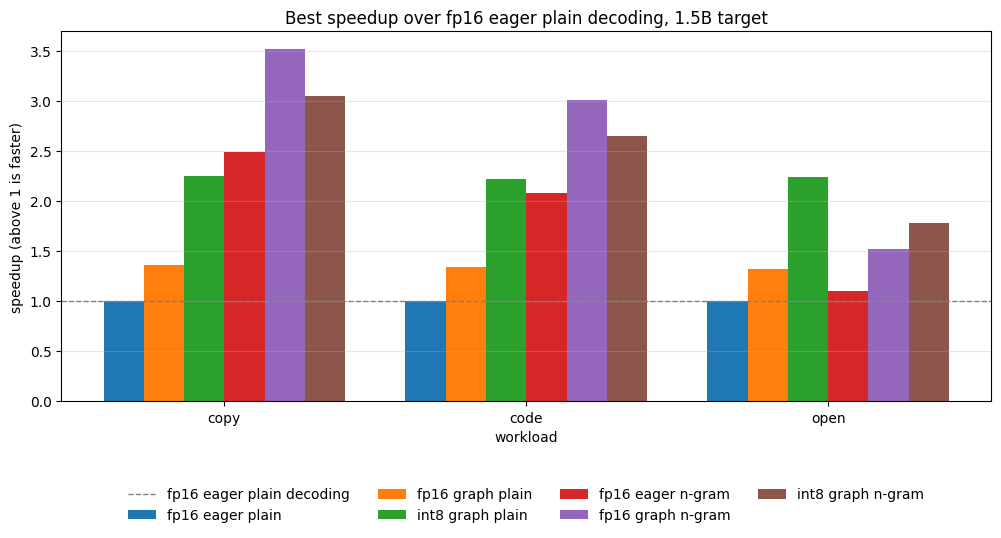

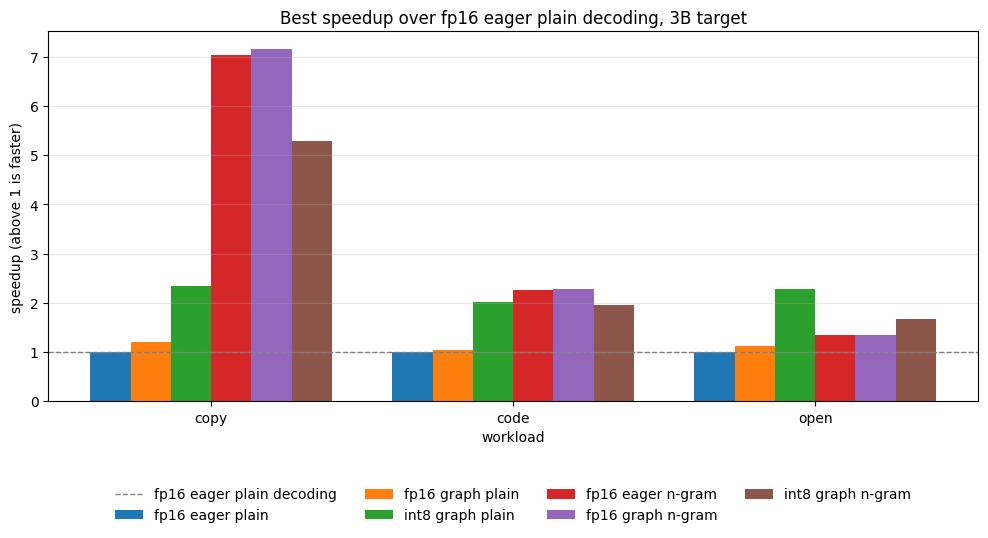

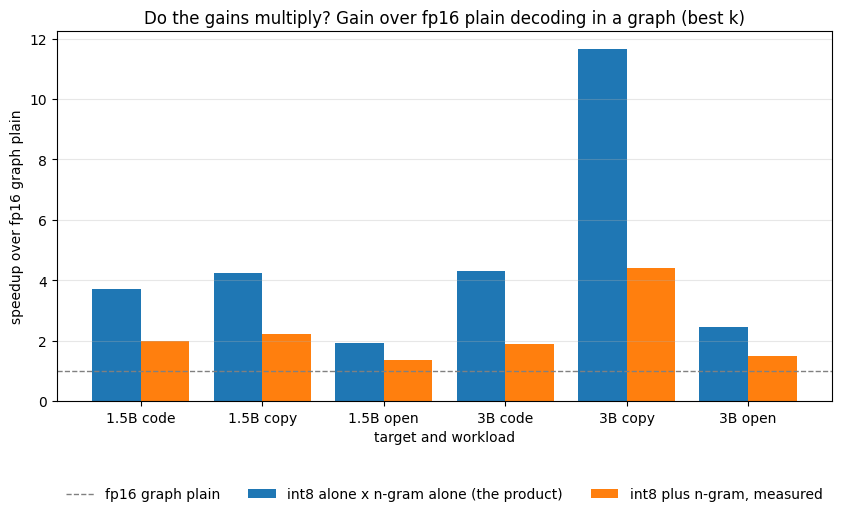

,target,workload,setup,k,vs_fp16_eager,vs_fp16_graph,alpha,tokens_per_step
0,1.5B,code,fp16 eager n-gram,6,2.08,1.55,0.71,2.36
1,1.5B,code,fp16 eager plain,0,1.00,0.75,0.00,1.00
2,1.5B,code,fp16 graph n-gram,6,3.01,2.24,0.71,2.36
3,1.5B,code,fp16 graph plain,0,1.34,1.00,0.00,1.00
4,1.5B,code,int8 graph n-gram,6,2.65,1.98,0.71,2.28
5,1.5B,code,int8 graph plain,0,2.22,1.65,0.00,1.00
6,1.5B,copy,fp16 eager n-gram,6,2.49,1.83,0.80,2.71
7,1.5B,copy,fp16 eager plain,0,1.00,0.73,0.00,1.00
8,1.5B,copy,fp16 graph n-gram,6,3.52,2.58,0.80,2.71
9,1.5B,copy,fp16 graph plain,0,1.36,1.00,0.00,1.00


In [84]:
idx = spec_df.groupby(["target", "workload", "setup"])["vs_fp16_eager"].idxmax()       # the best draft length of each setup
best = spec_df.loc[idx].reset_index(drop=True)
ORDER = ["fp16 eager plain", "fp16 graph plain", "int8 graph plain", "fp16 eager n-gram", "fp16 graph n-gram", "int8 graph n-gram"]
for tsize in TARGETS:
    b = best[best.target == tsize].set_index(["setup", "workload"]).vs_fp16_eager
    grouped_bar(WL, {s: [float(b.get((s, w), float("nan"))) for w in WL] for s in ORDER},
                f"Best speedup over fp16 eager plain decoding, {tsize} target", "speedup (above 1 is faster)", hline=1.0, hline_label="fp16 eager plain decoding",
                xlabel="workload", figsize=(12, 4.8), save=f"stage10_speedup_{tsize.replace('.', 'p').lower()}")
m_best = mult_df.loc[mult_df.groupby(["target", "workload"]).measured_both.idxmax()]
labels = [f"{r.target} {r.workload}" for r in m_best.itertuples()]
grouped_bar(labels, {"int8 alone x n-gram alone (the product)": list(m_best["product"]), "int8 plus n-gram, measured": list(m_best["measured_both"])},
            "Do the gains multiply? Gain over fp16 plain decoding in a graph (best k)", "speedup over fp16 graph plain", hline=1.0, hline_label="fp16 graph plain",
            xlabel="target and workload", figsize=(10, 4.8), save="stage10_multiply")
best[best.setup.isin(ORDER)][["target", "workload", "setup", "k", "vs_fp16_eager", "vs_fp16_graph", "alpha", "tokens_per_step"]].round(2)

**How to read it.**

- **The three baselines.** `vs_fp16_eager` is the speedup against the engine of every earlier stage, `vs_fp16_graph` isolates what the graph decoder does on its own for fp16, and `vs_int8_graph` is the gain of speculation on int8 weights alone. Reading across a row separates the three effects.
- **`v`** is the measured checking cost of this setup: the mean time of a round over the mean plain step of the same weights and engine, with rounds that found no draft (cheap one-token passes) included. `draft_found_frac` says how often a round had anything to check.
- **The multiplication table.** `product` is the gain of int8 alone times the gain of the lookup alone on fp16, `measured_both` is what int8 plus the lookup gave, both against fp16 plain in a graph. `both_over_product` near one means the gains compose. `ngram_alone_int8`, is the gain the lookup gives *on top of* int8.
- **`pred_x` against `speedup_x`.** The cost model fed with this row's own measured numbers.
- **Noise.** The baseline is the median of several timings. The speculative rows are single passes, so differences of a few percent are noise.
- **Exactness.** `n_exact` counts outputs identical to plain greedy for each row. Only the first prompt of each workload is gap-checked; the counts in the sweep also show that the eager fp16 engine itself differs from its own plain greedy in a few outputs.

**What this run shows.** Tokens per second at the best `k` of each setup:

| target | workload | fp16 eager plain | fp16 eager lookup | fp16 graph plain | fp16 graph lookup | int8 graph plain | int8 graph lookup |
| --- | --- | ---: | ---: | ---: | ---: | ---: | ---: |
| 1.5B | copy | 36.6 | 91.2 | 50.0 | **128.8** | 82.4 | 111.6 |
| 1.5B | code | 37.3 | 77.6 | 50.1 | **112.4** | 82.7 | 99.0 |
| 1.5B | open | 37.5 | 41.1 | 49.5 | 57.0 | **83.9** | 66.8 |
| 3B | copy | 20.3 (slow) | 143.0 | 24.4 (slow) | **145.5** | 47.7 | 107.3 |
| 3B | code | 23.7 (slow) | 53.4 | 24.6 (slow) | **54.2** | 47.9 | 46.4 |
| 3B | open | 21.3 (slow) | 28.6 | 24.0 (slow) | 28.8 | **48.6** | 35.7 |

The 3B fp16 plain baselines were measured during the warm-up of D2 (steady state about 26 and 27 tok/s), so ratios against them are inflated.

- **int8 and speculation do not multiply with this kernel.** `both_over_product` is 0.38 to 0.54 on copy and code and 0.61 to 0.70 on open text. The reason is `v`: the lookup's checking pass costs fp16 1.0 times a plain step and int8 1.9 to 2.4 times on copy and code (1.5 to 1.6 on open, where many rounds find no draft). The best setup is fp16 in a graph with the lookup on copy and code at both sizes, and int8 plain in a graph on open text. The best of the three against the fp16 eager baseline is 3.5x, 3.0x and 2.2x at 1.5B (copy, code, open), and at 3B 5.6x, 2.1x and 1.9x against the steady-state rate (the table would say 7.2x, 2.3x and 2.3x).
- **Where int8 plus the lookup does win:** over int8 plain on copy (1.35x at 1.5B, 2.25x at 3B). It is 1.20x on code at 1.5B and 0.97x at 3B, and **loses on open text** (0.80x and 0.73x), where a round that finds a draft costs more than two plain steps for well under two tokens. The prediction that it would be about neutral there missed.
- **Acceptance depends on the workload, not on the weights:** the lookup's `alpha` differs by at most 0.08 between fp16 and int8 on the same workload (slightly higher for int8 on open text).
- **The graph helps the lookup** on fp16, by less for the bigger model: 1.4x on copy, code and open at 1.5B and 1.0x at 3B.
- **The cost model.** With the `alpha`-based tokens per round it overstates the speedup of every lookup row by 14% to 52%, because the lookup's drafts are often shorter than `k` (my prediction of "within a quarter" held only for part of the rows). Fed with the **measured** tokens per round instead, it is within -1% to +10%.
- **A projection, not a result:** if the int8 checking pass cost 1.15 times a plain step instead of 1.9 to 2.4, the same arithmetic puts int8 plus the lookup at about 1.3x to 1.8x the measured fp16 graph plus lookup once each format's prefill is included (about 1.6x to 1.9x for decoding alone), on every workload and both sizes. The low end is copy at 3B, where the fp16 lookup run is so short that the prefill is a large share of it. At the capped clock a kernel may not reach that at 8 rows (correction in section 1).
- **Exactness.** Of 24 setups checked against their own plain greedy output (first prompt of each workload, 32 tokens), 22 are identical and two differ, both the int8 lookup on code (1.5B at token 2 with a logit gap of 0.008, 3B at token 28 with a gap of 0.0), so both are ties. The eager fp16 control showed no difference in these checks. The non-causal control changes the output on all three workloads. Over the whole sweep, 92 of 108 outputs are identical to plain greedy: 33 of 36 for fp16 eager and for fp16 in a graph (so the graph adds none), 26 of 36 for int8. Only the 24 checked outputs have their logit gap read.

---
## 5. Save results

`results/stage10.json` holds everything needed to re-plot without re-running:

- `env` and `config`: GPU, library versions, model revisions, and every experiment parameter,
- `tuning`, `kernel_check` and `gate`: section 1 (the tuned kernels and block sizes, correctness, and the one-layer gate both ways with the measured copy bandwidth),
- `block_cost` and `block_accuracy`: section 2,
- `plain`: section 3,
- `speculation`, `multiply` and `exactness`: section 4.

Final published numbers should come from one consistent environment.

In [85]:
def records(df):
    # JSON has no NaN: missing values become null
    return df.round(5).astype(object).where(pd.notnull(df), None).to_dict(orient="records")

ENV["model"] = ", ".join(MODEL_IDS[s] for s in SIZES)
ENV["model_revision"] = "; ".join(f"{m.split('/')[-1]} {str(h)[:8]}" for m, h in ENV.get("revisions", {}).items())
out = {
    "env": {**ENV, "max_pos": MAX_POS},
    "config": {
        "seed": SEED, "quick": QUICK, "sizes": SIZES, "targets": TARGETS, "models": {s: MODEL_IDS[s] for s in SIZES}, "context": CTX, "iters": ITERS,
        "kernel": {"tune_rows": list(TUNE_ROWS), "check_rows": CHECK_ROWS, "gate_rows": GATE_ROWS, "gate_model": MODEL_IDS[GATE_SIZE], "max_gemvm_rows": int8_kernel.MAX_GEMVM_ROWS},
        "block": {"tokens": BLOCK_TOKENS, "accuracy_model": MODEL_IDS[ACC_SIZE]},
        "plain": {"max_new": MAX_NEW, "runs": PLAIN_RUNS},
        "speculation": {"max_new": MAX_NEW, "prompts_per_workload": N_PROMPTS, "ks": KS, "baseline_runs": BASELINE_RUNS, "near_tie_gap": NEAR_TIE, "cache_len": MAX_LEN},
    },
    "tuning": records(tune_df),
    "kernel_check": records(check_df),
    "gate": {"copy_bw_gbps": COPY_BW, "spec_bw_gbps": SPEC_BW, "go": bool(KERNEL_GO),
             "ratio_1_row": None if RATIO_1 != RATIO_1 else RATIO_1, "ratio_5_rows": None if RATIO_5 != RATIO_5 else RATIO_5, "ratio_8_rows": None if RATIO_8 != RATIO_8 else RATIO_8,
             "rows": records(gate_df), "graph_rows": records(graph_df)},
    "block_cost": records(block_df),
    "block_accuracy": records(bacc_df),
    "plain": {"rows": records(plain_df), "exact": bool(PLAIN_EXACT)},
    "speculation": records(spec_df),
    "multiply": records(mult_df),
    "exactness": {"rows": records(exact_df), "speculative_exact": bool(SPEC_EXACT), "control": records(control_df), "control_breaks": CONTROL_BREAKS},
}
save_results("results/stage10.json", out)

saved results/stage10.json


### Figure inventory

Every figure was written to `results/` by the cell that produced it. This cell lists them and fails if one is missing.

In [86]:
FIGURES = {
    "stage10_layer_graph.png": "Speed of the tuned int8 kernel and the tensor-core kernel against the fp16 layer by rows of x, timed in a CUDA graph (section 1)",
    "stage10_layer_eager.png": "The same comparison the Stage 9 way, one call per timing, with the dequantize path and the built-in int8 matmul (section 1)",
    "stage10_block_cost.png": "Cost of a checking pass of 5 and 7 tokens relative to a one-token pass, fp16 and int8, in a CUDA graph (section 2)",
    "stage10_plain_rate.png": "Decode rate of plain greedy decoding, fp16 and int8, eager and in a graph (section 3)",
    "stage10_multiply.png": "Gain of int8 plus the n-gram lookup against the product of the two separate gains (section 4)",
}
for t in TARGETS:
    FIGURES[f"stage10_speedup_{t.replace('.', 'p').lower()}.png"] = f"Best speedup over fp16 eager plain decoding by workload and setup, {t} target (section 4)"
missing = [f for f in FIGURES if not os.path.exists(f"results/{f}")]
assert not missing, f"missing figures: {missing}"
pd.DataFrame({"file": list(FIGURES), "what it shows": list(FIGURES.values())})

,file,what it shows
0,stage10_layer_graph.png,Speed of the tuned int8 kernel and the tensor-...
1,stage10_layer_eager.png,"The same comparison the Stage 9 way, one call ..."
2,stage10_block_cost.png,Cost of a checking pass of 5 and 7 tokens rela...
3,stage10_plain_rate.png,"Decode rate of plain greedy decoding, fp16 and..."
4,stage10_multiply.png,Gain of int8 plus the n-gram lookup against th...
5,stage10_speedup_1p5b.png,Best speedup over fp16 eager plain decoding by...
6,stage10_speedup_3b.png,Best speedup over fp16 eager plain decoding by...


---
## Publish results (and code, if this is the newest notebook) to GitHub (optional)

Set `PUSH = True` to push this run to your repo. The cell below is identical in every notebook of the series except `PUSH` and `COMMIT_MSG`. It calls `publish()` from `bench/publish.py`, which clones the repo, pulls, copies `results/` in, and copies `minivllm/` and `bench/` in only if this notebook's stage is at least the stage recorded in the repo (`minivllm/STAGE`). It then commits and pushes, printing git's output and raising an error if any git step fails. This is the newest notebook, so it publishes code as well as results. An older notebook rerun later pushes results only and cannot overwrite this code.

It needs a Kaggle secret named `minivllm-github-token` holding a GitHub token with write access. The repo name and git identity are constants at the top of `bench/publish.py`. The token is used only for the clone, pull and push commands and is not stored in the repo's git config.

In [87]:
PUSH = True                              # True: publish to GitHub at the end of the run
COMMIT_MSG = "Stage 10: multi-row int8 kernel and speculation in CUDA graphs"   # the only other line that differs between notebooks
FORCE_CODE = False                       # leave False: code is published automatically from the newest stage

if PUSH:
    from kaggle_secrets import UserSecretsClient
    from bench.publish import publish, SECRET_NAME
    publish(token=UserSecretsClient().get_secret(SECRET_NAME), message=COMMIT_MSG, force_code=FORCE_CODE)

Updating 24fb217..7da472f
Fast-forward
 RESULTS.md | 912 ++++++++++++++++++++++++++++++-------------------------------
 1 file changed, 456 insertions(+), 456 deletions(-)
remote: Enumerating objects: 5, done.        
remote: Counting objects: 100% (5/5), done.        
remote: Compressing objects: 100% (1/1), done.        
remote: Total 3 (delta 2), reused 3 (delta 2), pack-reused 0 (from 0)        
From https://github.com/chizkidd/minivllm
 * branch            HEAD       -> FETCH_HEAD
notebook stage 10, repo code stage 10: publishing code and results
[main 3f42cae] Stage 10: multi-row int8 kernel and speculation in CUDA graphs
 8 files changed, 2900 insertions(+), 3080 deletions(-)
Enumerating objects: 21, done.
Counting objects: 100% (21/21), done.
Delta compression using up to 4 threads
Compressing objects: 100% (11/11), done.
Writing objects: 100% (11/11), 353.26 KiB | 14.13 MiB/s, done.
Total 11 (delta 3), reused 0 (delta 0), pack-reused 0
To https://github.com/chizkidd/minivllm.g

---
## 6. Summary and lessons

In [88]:
from IPython.display import Markdown, display

def show_table(rows, headers=("Metric", "Result", "Note")):
    esc = lambda c: str(c).replace("|", "\\|")   # a literal | would break the table
    out_ = ["| " + " | ".join(headers) + " |", "|" + "|".join(["---"] * len(headers)) + "|"]
    for r in rows:
        out_.append("| " + " | ".join([f"**{esc(r[0])}**"] + [esc(c) for c in r[1:]]) + " |")
    display(Markdown("\n".join(out_)))

rows = []
rows.append(("Kernel gate", f"{'GO' if KERNEL_GO else 'NO-GO'}: {RATIO_5:.2f}x the fp16 layer on the large layers at 5 rows, in a graph",
             f"1 row {RATIO_1:.2f}x, 8 rows {RATIO_8:.2f}x; largest error {check_df.rel_err.max():.1e}; copy bandwidth {COPY_BW:.0f} GB/s"))
for s in SIZES:
    for T in [t for t in BLOCK_TOKENS if t > 1][:1]:
        a = block_df[(block_df.model == s) & (block_df["mode"] == "graph") & (block_df.tokens == T)].set_index("variant").rel_to_one_token
        if "fp16" in a.index and "int8" in a.index:
            rows.append((f"Checking pass of {T} tokens, {s}", f"fp16 {a['fp16']:.2f}x, int8 {a['int8']:.2f}x a one-token pass", "in a CUDA graph"))
for r in ratio_plain.itertuples(index=False):
    rows.append((f"Plain decoding, {r[0]}", f"int8 graph / fp16 eager = {r[4]:.2f}x; int8 graph / fp16 graph = {r[3]:.2f}x", f"fp16 graph / fp16 eager = {r[1]:.2f}x"))
for t in TARGETS:
    for w in WL:
        s = best[(best.target == t) & (best.workload == w) & (best.setup == "int8 graph n-gram")].iloc[0]
        m = m_best[(m_best.target == t) & (m_best.workload == w)].iloc[0]
        rows.append((f"int8 + n-gram, {t}, {w}", f"{s.vs_fp16_eager:.2f}x fp16 eager plain (k = {int(s.k)})", f"{m.measured_both:.2f}x fp16 graph plain; the product of the separate gains {m['product']:.2f}x"))
rows.append(("Exactness", f"every difference a near-tie: {SPEC_EXACT}; non-causal control breaks the output: {CONTROL_BREAKS}", f"fp16 eager control included, gap bound {NEAR_TIE}"))
show_table(rows)

| Metric | Result | Note |
|---|---|---|
| **Kernel gate** | NO-GO: 0.63x the fp16 layer on the large layers at 5 rows, in a graph | 1 row 2.71x, 8 rows 0.60x; largest error 7.8e-04; copy bandwidth 243 GB/s |
| **Checking pass of 5 tokens, 0.5B** | fp16 1.01x, int8 1.71x a one-token pass | in a CUDA graph |
| **Checking pass of 5 tokens, 1.5B** | fp16 1.01x, int8 2.31x a one-token pass | in a CUDA graph |
| **Checking pass of 5 tokens, 3B** | fp16 1.00x, int8 2.45x a one-token pass | in a CUDA graph |
| **Plain decoding, 0.5B** | int8 graph / fp16 eager = 3.67x; int8 graph / fp16 graph = 1.51x | fp16 graph / fp16 eager = 2.42x |
| **Plain decoding, 1.5B** | int8 graph / fp16 eager = 2.33x; int8 graph / fp16 graph = 1.87x | fp16 graph / fp16 eager = 1.25x |
| **Plain decoding, 3B** | int8 graph / fp16 eager = 2.72x; int8 graph / fp16 graph = 2.01x | fp16 graph / fp16 eager = 1.35x |
| **int8 + n-gram, 1.5B, copy** | 3.05x fp16 eager plain (k = 6) | 2.23x fp16 graph plain; the product of the separate gains 4.25x |
| **int8 + n-gram, 1.5B, code** | 2.65x fp16 eager plain (k = 6) | 1.98x fp16 graph plain; the product of the separate gains 3.71x |
| **int8 + n-gram, 1.5B, open** | 1.78x fp16 eager plain (k = 4) | 1.35x fp16 graph plain; the product of the separate gains 1.93x |
| **int8 + n-gram, 3B, copy** | 5.28x fp16 eager plain (k = 6) | 4.40x fp16 graph plain; the product of the separate gains 11.66x |
| **int8 + n-gram, 3B, code** | 1.96x fp16 eager plain (k = 6) | 1.89x fp16 graph plain; the product of the separate gains 4.30x |
| **int8 + n-gram, 3B, open** | 1.67x fp16 eager plain (k = 4) | 1.49x fp16 graph plain; the product of the separate gains 2.44x |
| **Exactness** | every difference a near-tie: True; non-causal control breaks the output: True | fp16 eager control included, gap bound 0.5 |

### What we learned

#### Questions

- **Can int8 weights be read once for all the rows of a checking pass?** (Section 1: the multi-row kernel and its gate.)
- **What does a block of tokens cost in a graph, for fp16 and for int8?** (Section 2: the `v` of the cost model.)
- **What does quantization buy a decoder once the loop itself is fast?** (Section 3: plain decoding as a rate.)
- **Do int8 and speculation multiply?** (Section 4.)

#### Answers

- **Can int8 weights be read once for all the rows of a checking pass?** Not at memory speed, with this kernel. The multi-row kernel is correct (largest relative error 7.8e-4) but its time grows with the rows: against the fp16 layer on the large layers, in a graph, it is 0.94x at 2 rows, 0.63x at 5 and 0.60x at 8, at a quarter of the copy bandwidth, and about a fifth of the multiply-add peak of the power-capped GPU. The gate is a no-go. Its tile winners sit at the edge of the grid, so the grid was too small.
- **What does a block of tokens cost in a graph?** fp16: nothing (1.00 to 1.03 of a one-token pass at 5 and 7 tokens). int8: 1.7x to 1.8x at 0.5B, 2.3x to 2.4x at 1.5B and 2.5x to 2.6x at 3B, so a 5-token int8 pass is slower than the fp16 one at every size, though the one-token int8 pass is faster. The extra cost equals the sum of the multi-row kernel's layer times, within about a tenth: the kernel is the whole loss.
- **What does quantization buy a decoder once the loop is fast?** In a graph, int8 decodes 1.5x, 1.9x and 2.0x faster than fp16 at 0.5B, 1.5B and 3B (about 1.85x at 3B with the steady-state fp16 rate), against stock `F.linear`: the fp16 graph step carries an avoidable cost at `lm_head` at one row (D1; for 1.5B the gain would be about 1.5x at the pass level with `lm_head` on two rows). Against the eager fp16 baseline it is 3.7x and 2.3x at 0.5B and 1.5B. The graph alone helps fp16 by 2.4x at 0.5B and 1.3x to 1.4x at 1.5B and not at all at 3B.
- **Do int8 and speculation multiply?** No. Int8 plus the n-gram lookup reaches 0.38 to 0.70 of the product of the two gains, and fp16 plus the lookup in a graph beats it on copy and code at both sizes (1.5B copy: 129 against 112 tokens per second; 3B copy: 146 against 107). The best setups are fp16 in a graph with the lookup on repetitive text (3.5x and 5.6x the eager fp16 baseline on copy at 1.5B and 3B) and int8 plain in a graph on open text (2.2x and 1.9x). The cause is the checking pass: 1.9 to 2.4 plain steps for int8, 1.0 for fp16. Fed the measured tokens per round, the cost model predicts the speedups to within -1% to +10%. If the int8 checking pass cost 1.15 plain steps, the same arithmetic gives about 1.3x to 1.8x the fp16 graph plus lookup once the prefill is included (1.6x to 1.9x for decoding alone) (a projection, not a result).

### Next: a better multi-row kernel

The result points at one thing. The graph decoder works (every output equals plain greedy up to fp16 ties, and the non-causal control breaks it), the lookup is free, and the whole int8 loss sits in one kernel whose per-layer times add up to the full extra cost of a checking pass. The next notebook rewrites that kernel and gates it again: one two-dimensional accumulator per row, in an unrolled loop, as the one-token kernel has (instead of a three-dimensional accumulator), a larger grid (all winners on the large layers sit at the largest tile and the smallest warp count), and the same gate: the tuned 5-row layer at least as fast as the fp16 layer, in a graph. If it passes, the measurement to repeat is the 2x2 of section 4. Because the T4 runs power-capped here (about 2.3 trillion multiply-adds a second), the notebook should also try a 4-row variant (a draft length of 3) and cheaper arithmetic per weight, compute the fp16 `lm_head` on two rows for a fair baseline, and log the GPU clocks and warm up before each timing block. After that, draft models with a captured feed, and then the engine leaves the notebook: package it, add what a server needs (a real request loop on a real clock, end-of-sequence stopping, sampling), run it on a bigger GPU, and compare it with an established serving system on the same traces and metrics.

### Exercises

1. **One accumulator per row.** Replace the `[MAX_M, BLOCK_N, BLOCK_K]` accumulator of `gemvm` by `MAX_M` two-dimensional accumulators in an unrolled loop, each updated from the same int8 tile. Does the time per layer stop growing with the rows?
2. **A bigger grid.** The winners sit at `BLOCK_N` 4, `BLOCK_K` 256 and two warps, the corner of the grid. Extend it (`BLOCK_N` 8 and 16, `BLOCK_K` 512, other warp counts) and see where the optimum is.
3. **Why is the multi-row kernel where it is?** Profile it (Nsight Compute or `triton.testing`) and find whether the conversion, the FMAs, the layout conversions or the memory system limits it at 8 rows.
4. **A tensor-core kernel for 5 to 16 rows.** `tl.dot` needs 16 rows, and the Stage 9 tile is flat in the rows (0.82 to 0.85 ms on gate/up from 1 to 16 rows) at a tenth to a fifth of the fp16 layer's speed. Use a transposed formulation (the weights as the 16-row operand, the few activation rows as the narrow one) and see whether the tensor cores beat the FMA units.
5. **Draft models with a captured feed.** Make `DraftModel` feed the tokens the target accepted as one captured fixed-length pass, so a round with a 0.5B draft is graph launches end to end. What does the cost ratio become, and does the 0.5B draft beat the lookup on open text?
6. **Variable-length blocks.** Capture checking passes for several lengths and run the smallest that fits the drafts found, instead of padding to `k + 1`. When does it pay, given that every extra graph costs memory?
7. **Sampling.** Replace the greedy acceptance with speculative sampling (Leviathan et al., Chen et al.): accept a draft with probability `min(1, p / q)` and resample on rejection. The output distribution stays the target's. What changes in the rollback?
8. **A decode batch above 8.** The multi-row kernel stops at eight rows. Where is the crossover with the dequantize path, and with a kernel tuned for the batch sizes of a server?
9. **Split-K for the narrow layers.** The `k/v` projections have few output rows. Split the loop over `K` across programs and reduce the partial sums; does the pass stop being launch-bound inside the graph?
10. **A graph for the prefill.** Capture the prompt pass for a few bucketed lengths. How much of the time to first token is launches?
11. **Tree speculation.** Check several candidate continuations per position in one pass with a tree mask. With a fixed-shape graph, what is the mask, and what does a wider block cost on int8?

### References

- Leviathan, Kalman, Matias, *Fast Inference from Transformers via Speculative Decoding*: https://arxiv.org/abs/2211.17192
- Chen et al., *Accelerating Large Language Model Decoding with Speculative Sampling*: https://arxiv.org/abs/2302.01318
- Saxena, *Prompt Lookup Decoding*: https://github.com/apoorvumang/prompt-lookup-decoding
- PyTorch, *Accelerating PyTorch with CUDA Graphs*: https://pytorch.org/blog/accelerating-pytorch-with-cuda-graphs/
- PyTorch, *gpt-fast* (weight-only int8 with `torch.compile` and a static cache): https://github.com/pytorch-labs/gpt-fast
- Tillet, Kung, Cox, *Triton: An Intermediate Language and Compiler for Tiled Neural Network Computations*: https://dl.acm.org/doi/10.1145/3315508.3329973
- Williams, Waterman, Patterson, *Roofline: An Insightful Visual Performance Model*: https://dl.acm.org/doi/10.1145/1498765.1498785